# Connect Forest Management Model with Forest Carbon Budget Model

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
import ws3.forest
import time
import gurobipy as grb
import pickle
import libcbm
import os
from util_opt import compile_events, cbm_report, compile_scenario_maxstock, plot_scenario_maxstock, run_cbm_emissionstock, run_scenario, plugin_c_curves, plugin_c_curves_both, cbm_report_both, compare_ws3_cbm, compare_ws3_cbm_both, track_system_stock, track_system_emission, compile_scenario_minemission, plot_scenario_minemission, kpi_age, kpi_species, cmp_c_ss, cmp_c_se, results_scenarios, bootstrap_ogi, compare_kpi_age

In [2]:
base_year = 2020
horizon = 10
period_length = 10
max_age = 1000
n_steps = 100
tvy_name = 'totvol'
max_harvest = 1.0

In [3]:
# Define scenario options based on case study
scenario_options = {
    'redchris': ['no_cons','evenflow_cons', 'redchrs_AAC_90%', 'redchrs_AAC_80%', 'redchrs_AAC_70%', 'redchrs_AAC_60%', 'redchrs_AAC_50%', 'redchrs_AAC_40%', 'redchrs_AAC_30%', 'redchrs_AAC_20%', 'redchrs_AAC_10%' ],
    'goldenbear': ['no_cons', 'evenflow_cons', 'gldbr_AAC_90%', 'gldbr_AAC_80%', 'gldbr_AAC_70%', 'gldbr_AAC_60%', 'gldbr_AAC_50%', 'gldbr_AAC_40%', 'gldbr_AAC_30%', 'gldbr_AAC_20%', 'gldbr_AAC_10%'],
    'equitysilver': [ 'no_cons','evenflow_cons', 'eqtslvr_AAC_90%', 'eqtslvr_AAC_80%', 'eqtslvr_AAC_70%', 'eqtslvr_AAC_60%', 'eqtslvr_AAC_50%', 'eqtslvr_AAC_40%', 'eqtslvr_AAC_30%', 'eqtslvr_AAC_20%', 'eqtslvr_AAC_10%'],
    'test': ['no_cons', 'evenflow_cons', 'bau_redchrs']
}

# Function to handle case study selection and update scenario dropdown
def select_case_study(case_study):
    print(f"Selected case study: {case_study}")
    # Update the scenario dropdown based on the selected case study
    scenario_dropdown.options = scenario_options.get(case_study, [])
    scenario_dropdown.value = scenario_options[case_study][0]  # Set a default value

# Case study dropdown
case_study_dropdown = widgets.Dropdown(
    options=['redchris', 'goldenbear', 'equitysilver', 'test'],
    value='equitysilver',
    description='Case Study:'
)
case_study_dropdown.observe(lambda change: select_case_study(change['new']), names='value')
display(case_study_dropdown)

# Function to handle scenario selection
def select_scenario(scenario_name):
    print(f"Selected scenario: {scenario_name}")

# Scenario dropdown
scenario_dropdown = widgets.Dropdown(
    options=scenario_options['redchris'],  # Set initial options based on default case study
    value=scenario_options['redchris'][1],  # Set initial value
    description='Scenario:'
)
scenario_dropdown.observe(lambda change: select_scenario(change['new']), names='value')
display(scenario_dropdown)

# Function to handle objective functon
def select_obj(obj_mode):
    print(f"Selected objective: {obj_mode}")
obj_dropdown = widgets.Dropdown(
    options=['max_hv', 'min_ha', 'max_st', 'min_em'],
    value='max_st',
    description='Objective:'
)
display(obj_dropdown)
obj_dropdown.observe(lambda change: select_obj(change['new']), names='value')

Dropdown(description='Case Study:', index=2, options=('redchris', 'goldenbear', 'equitysilver', 'test'), value…

Dropdown(description='Scenario:', index=1, options=('no_cons', 'evenflow_cons', 'redchrs_AAC_90%', 'redchrs_AA…

Dropdown(description='Objective:', index=2, options=('max_hv', 'min_ha', 'max_st', 'min_em'), value='max_st')

In [4]:
# Initialize main widget components 
hwp_pool_effect = widgets.FloatSlider(min=0, max=1, step=1, description='HWP_effect', value=1, layout=widgets.Layout(margin='10px 0'))
release_immediately = widgets.FloatSlider(min=0, max=1, step=1, description='Release immediately', value=1, layout=widgets.Layout(margin='10px 0'))
displacement_effect = widgets.FloatSlider(min=0, max=1, step=1, description='Displacement', value=1, layout=widgets.Layout(margin='10px 0'))
clt_percentage = widgets.FloatSlider(min=0, max=1, step=0.1, description='CLT_percent:', value=0.5, layout=widgets.Layout(margin='10px 0'))
credibility = widgets.FloatSlider(min=0, max=1, step=0.1, description='Credibility:', value=1, layout=widgets.Layout(margin='10px 0'))
# max_harvest = widgets.FloatSlider(min=0, max=1, step=0.05, description='Max_harvest:', value=1.0, layout=widgets.Layout(margin='10px 0'))
budget_input = widgets.FloatText(value=10000000, description='Budget:', layout=widgets.Layout(margin='10px 0'))

release_immediately.layout.display = 'none' if hwp_pool_effect.value != 0 else 'block'
displacement_effect.layout.display = 'block' if hwp_pool_effect.value != 0 else 'none'
clt_percentage.layout.display = 'block' if hwp_pool_effect.value != 0 and displacement_effect.value != 0 else 'none'
credibility.layout.display = 'block' if hwp_pool_effect.value != 0 and displacement_effect.value != 0 else 'none'

container = widgets.VBox([
    hwp_pool_effect, release_immediately, displacement_effect, clt_percentage, credibility, budget_input  
    # ,max_harvest
])

display(container)

def update_widgets(change):
    hwp_pool_effect_value = hwp_pool_effect.value
    displacement_effect_value = displacement_effect.value

    release_immediately.layout.display = 'block' if hwp_pool_effect_value == 0 else 'none'
    displacement_effect.layout.display = 'block' if hwp_pool_effect_value != 0 else 'none'

    clt_percentage.layout.display = 'block' if hwp_pool_effect_value != 0 and displacement_effect_value != 0 else 'none'
    credibility.layout.display = 'block' if hwp_pool_effect_value != 0 and displacement_effect_value != 0 else 'none'

hwp_pool_effect.observe(update_widgets, names='value')
displacement_effect.observe(update_widgets, names='value')

In [5]:
#Start Calculating the Running Time
Start = time.time()

In [6]:
case_study = case_study_dropdown.value
scenario_name = scenario_dropdown.value
obj_mode = obj_dropdown.value
hwp_pool_effect_value = hwp_pool_effect.value
release_immediately_value = release_immediately.value if hwp_pool_effect_value == 0 else 0
displacement_effect = displacement_effect.value if hwp_pool_effect_value != 0 else 0
clt_percentage = clt_percentage.value if displacement_effect != 0 else 0
credibility = credibility.value if displacement_effect != 0 else 0
# max_harvest = max_harvest.value
budget_input = budget_input.value

In [7]:
# Define case study mappings and retrieve model details based on case study
case_study_options = {
    'redchris': {
        'model_name': 'redchris',
        'model_path': './data/woodstock_model_files_redchris'
    },
    'goldenbear': {
        'model_name': 'goldenbear',
        'model_path': './data/woodstock_model_files_goldenbear'
    },
    'equitysilver': {
        'model_name': 'equitysilver',
        'model_path': './data/woodstock_model_files_equitysilver'
    },
    'test': {
        'model_name': 'redchris',
        'model_path': './data/woodstock_model_files_redchris_test'
    }
}

model_info = case_study_options.get(case_study)

if model_info:
    model_name = model_info['model_name']
    model_path = model_info['model_path']
else:
    print('The case study name is not valid')


In [8]:
# Create and Run `ForestModel` instance
fm = ws3.forest.ForestModel(model_name=model_name,
                            model_path=model_path,
                            base_year=base_year,
                            horizon=horizon,
                            period_length=period_length,
                            max_age=max_age)
fm.import_landscape_section()
fm.import_areas_section()
fm.import_yields_section()
fm.import_actions_section()
fm.import_transitions_section()
fm.initialize_areas()
fm.add_null_action()
fm.reset_actions()
fm.grow()

In [9]:
# Flag 'harvest' as a harvesting action in the ws3 model
harvest_acode='harvest'
fm.actions[harvest_acode].is_harvest = True

In [10]:
# Read curves
file_directory = "./inputs/curves"
file_names = [f"{case_study}_c_curves_p.pkl", f"{case_study}_c_curves_f.pkl"]
loaded_data = {}

for filename in file_names:
    file_path = os.path.join(file_directory, filename)
    with open(file_path, 'rb') as file:
        loaded_data[filename] = pickle.load(file)
    print(f"Loaded data from {file_path}")

c_curves_p = loaded_data.get(f"{case_study}_c_curves_p.pkl")
c_curves_f = loaded_data.get(f"{case_study}_c_curves_f.pkl")

Loaded data from ./inputs/curves/equitysilver_c_curves_p.pkl
Loaded data from ./inputs/curves/equitysilver_c_curves_f.pkl


In [11]:
# Plug carbon and old groth yield curves into forest model
plugin_c_curves_both(fm, c_curves_p, c_curves_f)
bootstrap_ogi(fm)

Running for equitysilver_max_st_no_cons...
running no_cons scenario
Set parameter Username
Academic license - for non-commercial use only - expires 2025-01-09
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17023 rows, 83258 columns and 83258 nonzeros
Model fingerprint: 0x23d4e977
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 17023 rows and 83258 columns
Presolve time: 0.07s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    1.6774505e+09   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.09 seconds (0.03 work units)
Optimal objective  1.677450535e+09


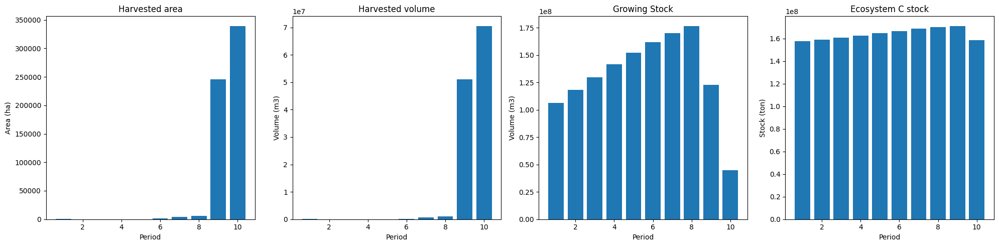

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_no_cons_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  130647
The economic indicator (the provincial government revenues) is:  4455359
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


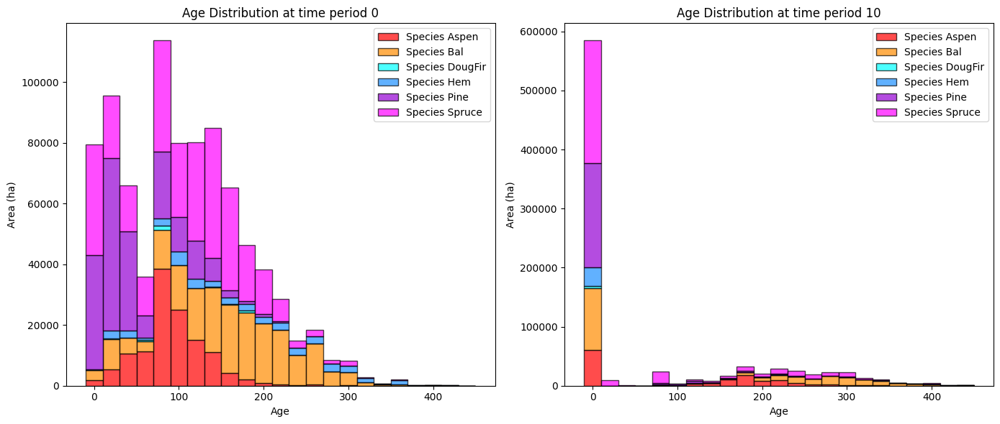

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_no_cons_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6126.874563 -13025.252666
DougFir    947.047810    387.176384   -559.871426
Bal      59315.970469  79882.187655  20566.217186
Spruce   36410.744598  52548.704990  16137.960392
Aspen    29632.731169  61943.511569  32310.780400
Pine      7432.733686   6721.590051   -711.143635

Overall diversity has **increased** by 54718.69 hectares from time period 0 to time period 10.


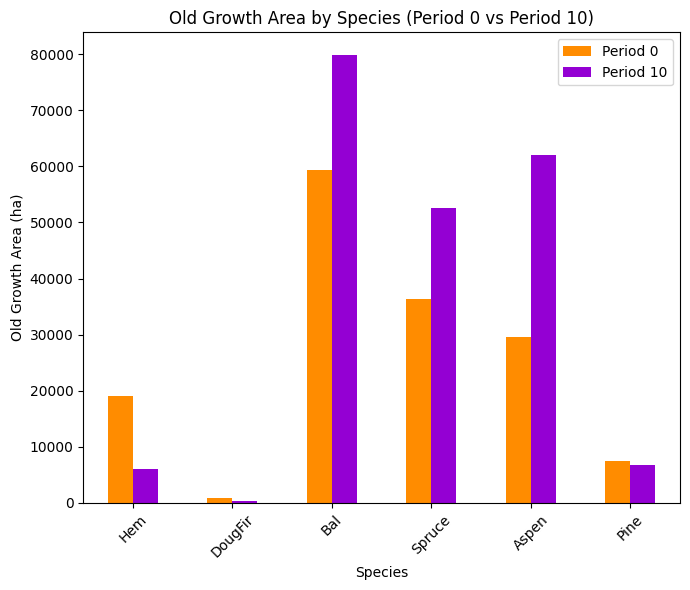

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_no_cons_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7335

Diversity has **decreased** by 2.56% from time 0 to time 10.


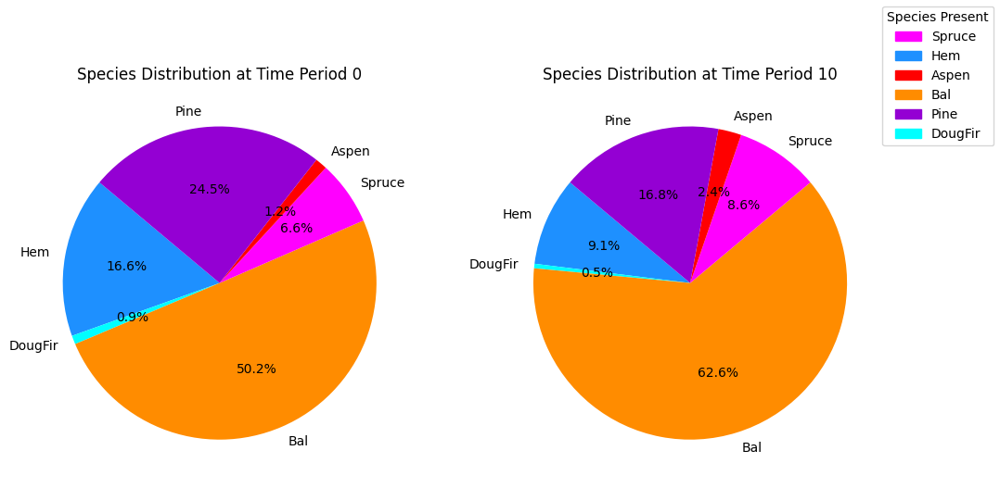

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_no_cons_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.35s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering t

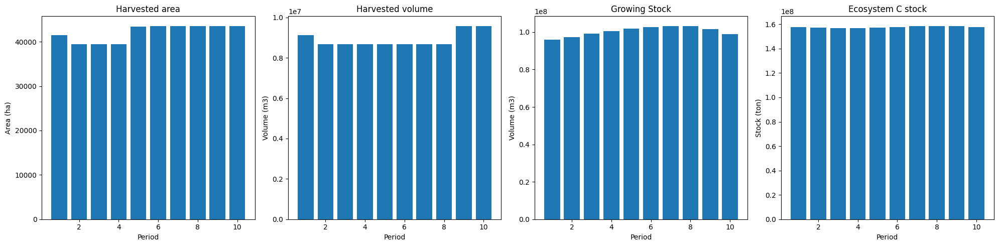

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


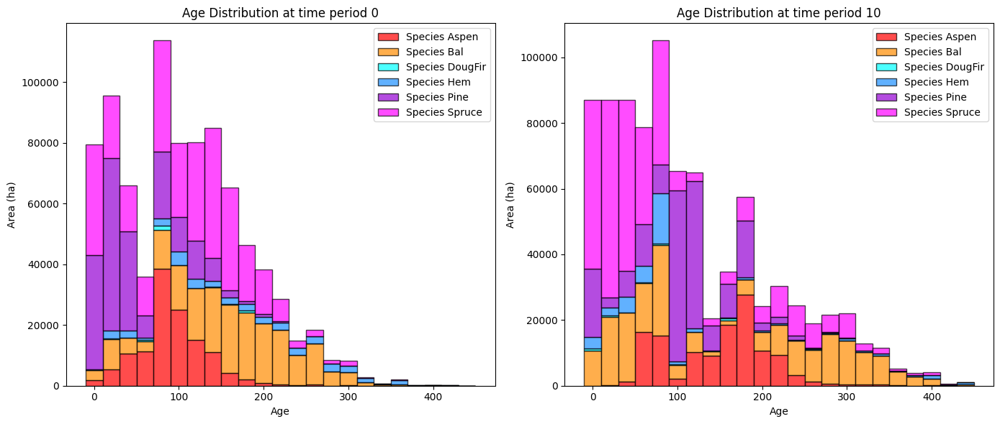

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


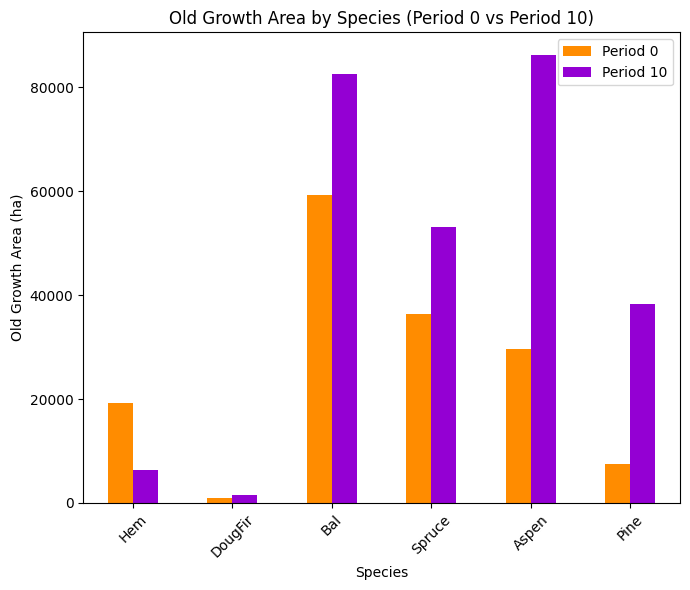

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


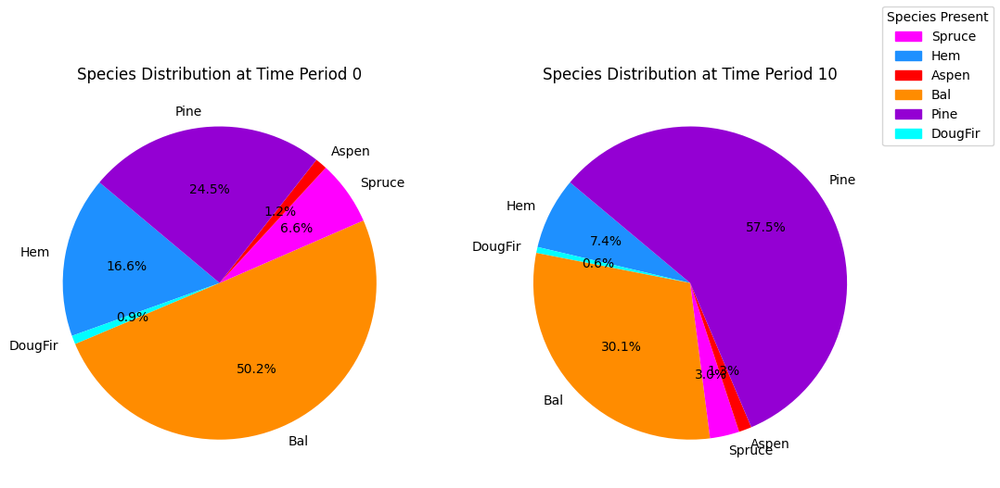

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


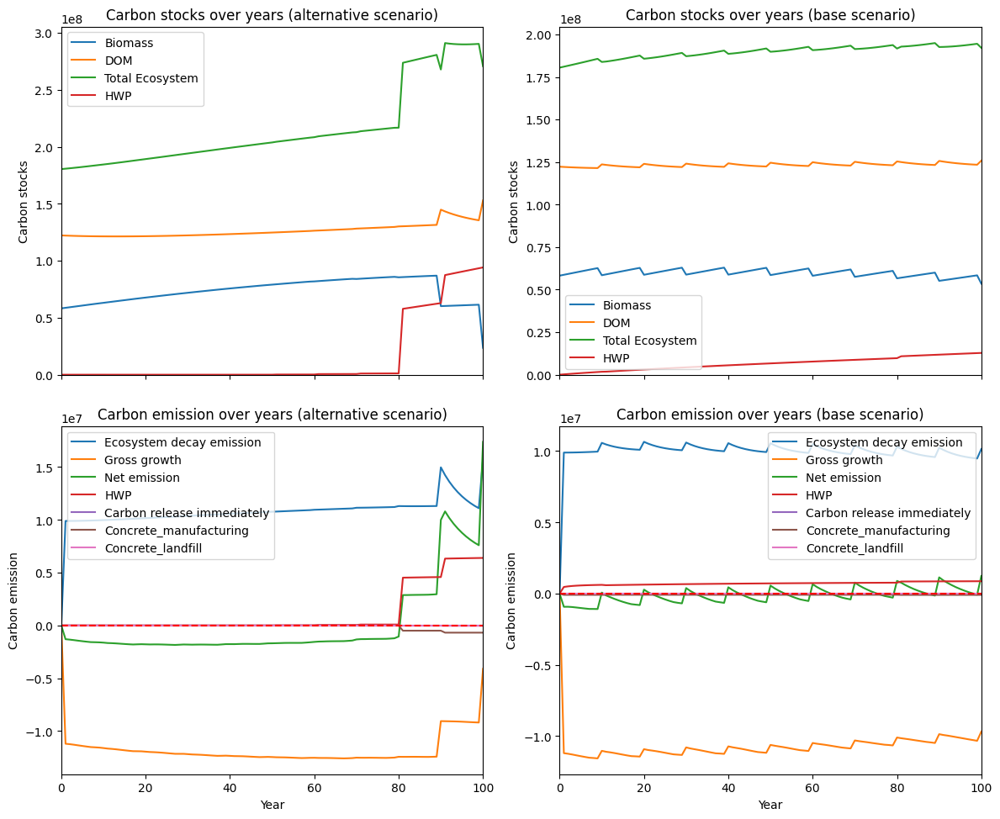

---------------------------------------------------------------------------------------
Net emission difference -25541423.05299055
Net emission base scenario -39459347.59402669
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.391520863158372
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   -209.385029   -209.385029
DougFir  0.0  -1099.719628  -1099.719628
Bal      0.0  -2728.435771  -2728.435771
Spruce   0.0   -478.761144   -478.761144
Aspen    0.0 -24280.547193 -24280.547193
Pine     0.0 -31531.979211 -31531.979211

Overall, the old growth area has **decreased** by -60328.83 hectares in the alternative scenario compared to the base scenario.


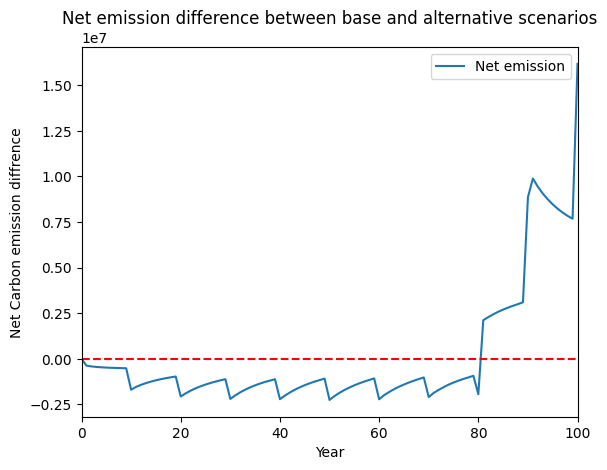

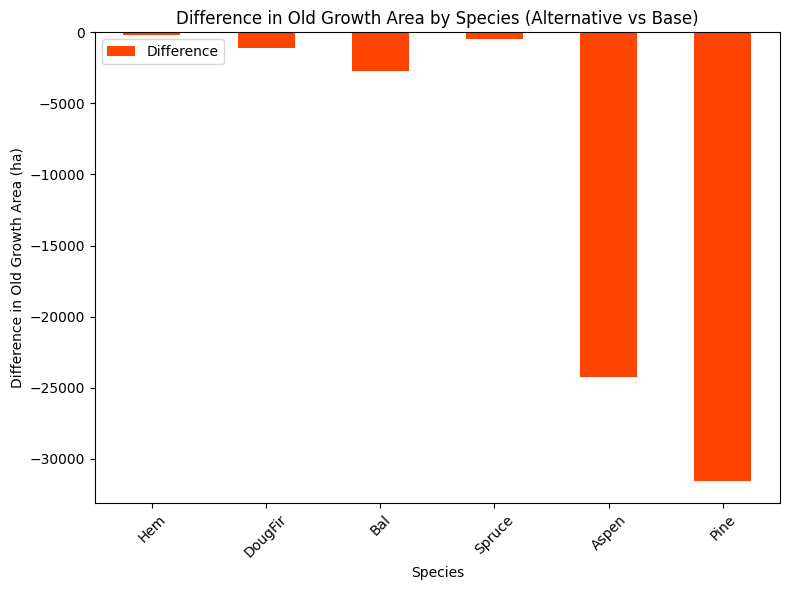

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


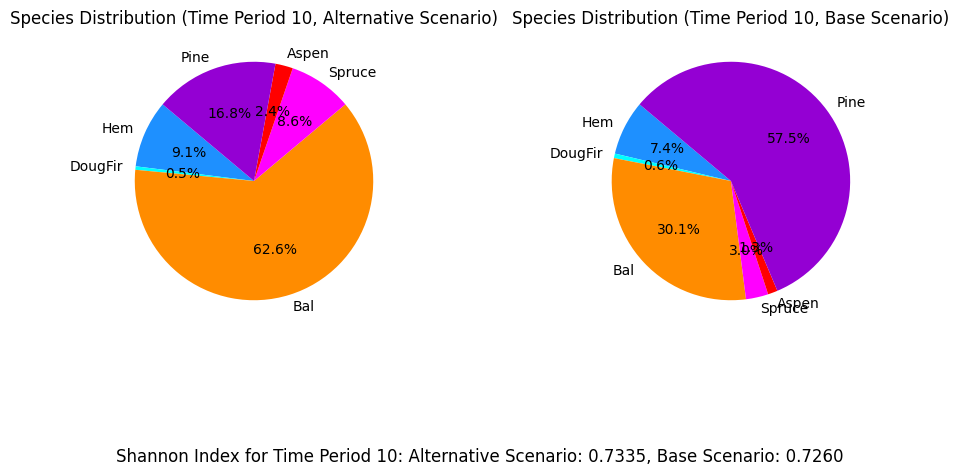

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_evenflow_cons...
running even flow constraints scenario
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17063 rows, 83258 columns and 514878 nonzeros
Model fingerprint: 0x72f21ba2
Coefficient statistics:
  Matrix range     [5e-03, 6e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 8690 rows and 8883 columns
Presolve time: 0.27s
Presolved: 8373 rows, 74375 columns, 486425 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Orde

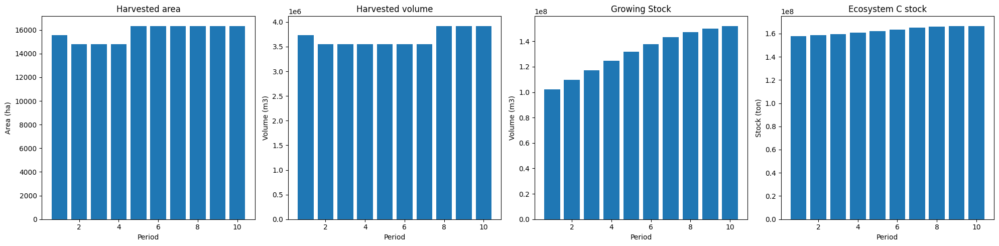

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_evenflow_cons_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  38891
The economic indicator (the provincial government revenues) is:  1326297
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


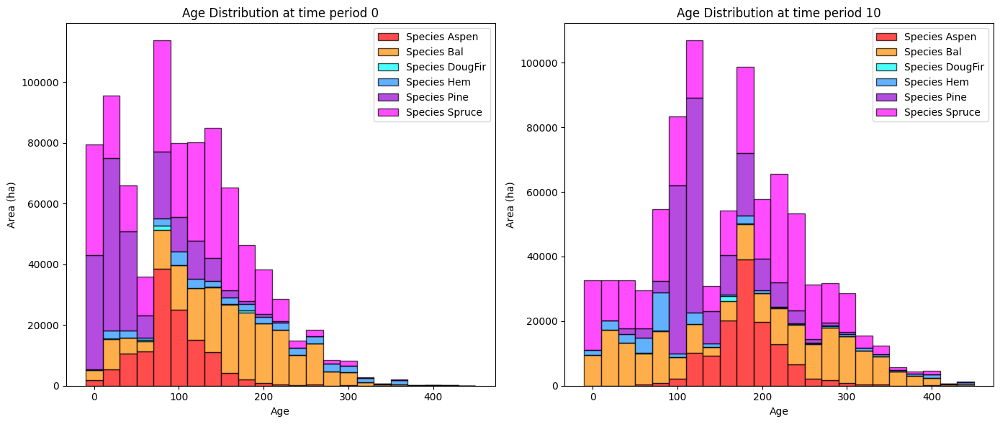

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_evenflow_cons_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   10716.831431   -8435.295797
DougFir    947.047810    2607.841586    1660.793776
Bal      59315.970469   98798.721755   39482.751286
Spruce   36410.744598  153356.886522  116946.141924
Aspen    29632.731169  117852.853466   88220.122297
Pine      7432.733686   65582.164943   58149.431257

Overall diversity has **increased** by 296023.94 hectares from time period 0 to time period 10.


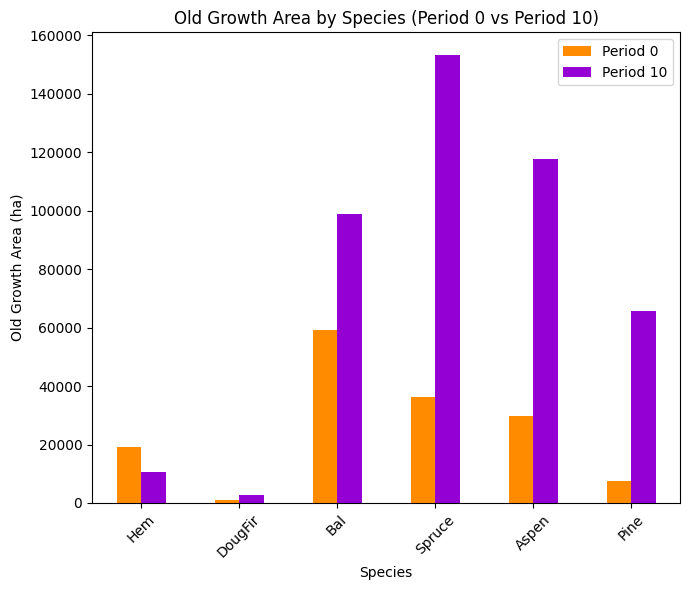

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_evenflow_cons_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7123

Diversity has **decreased** by 4.69% from time 0 to time 10.


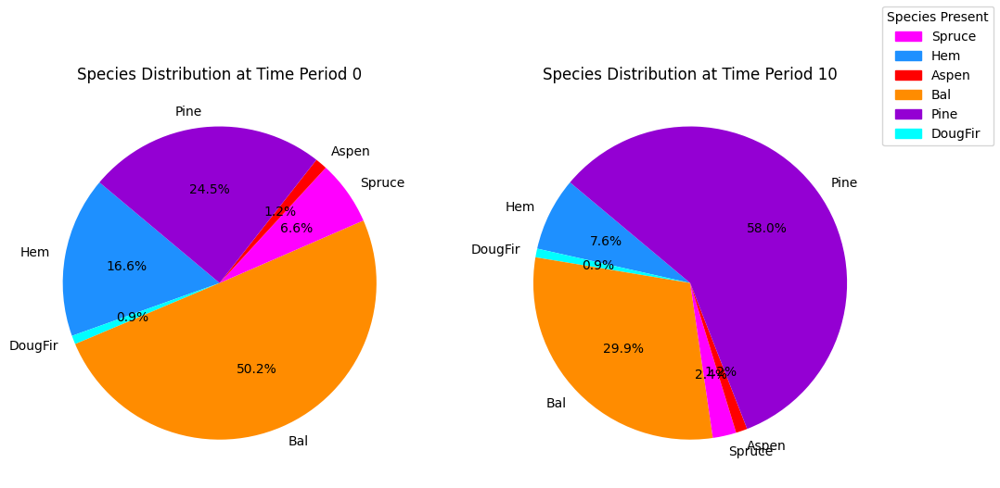

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_evenflow_cons_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.31s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Orde

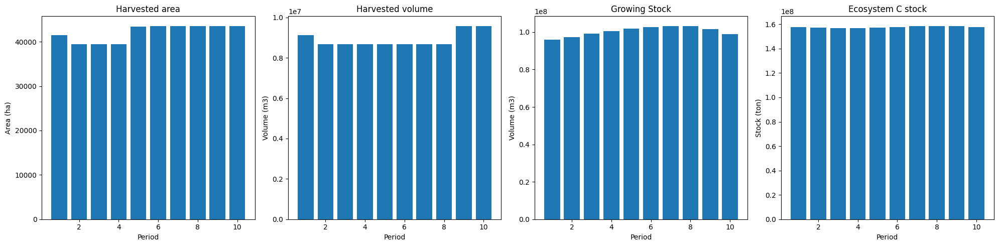

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


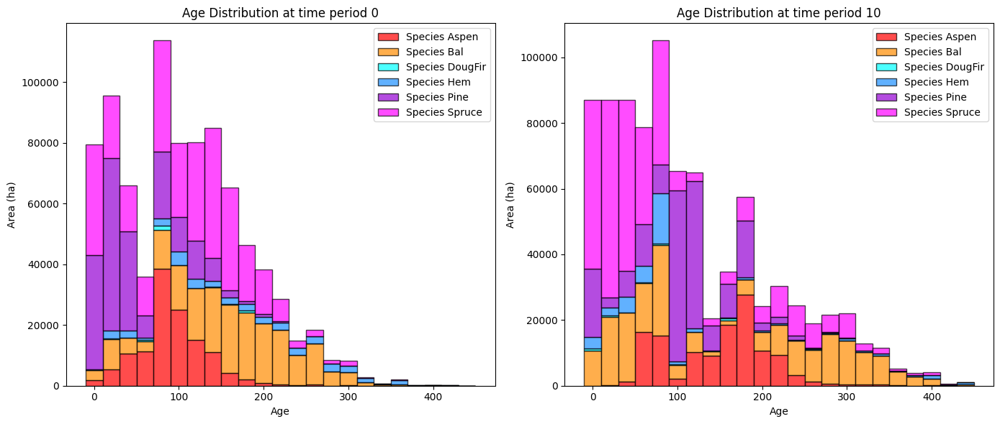

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


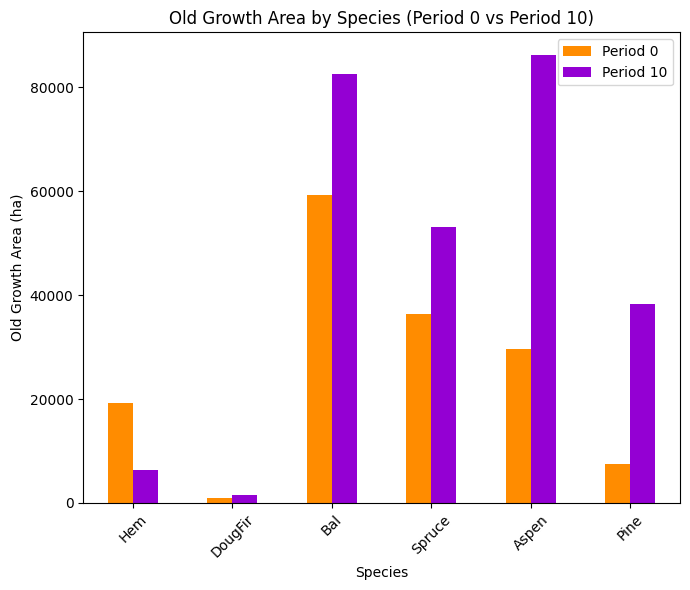

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


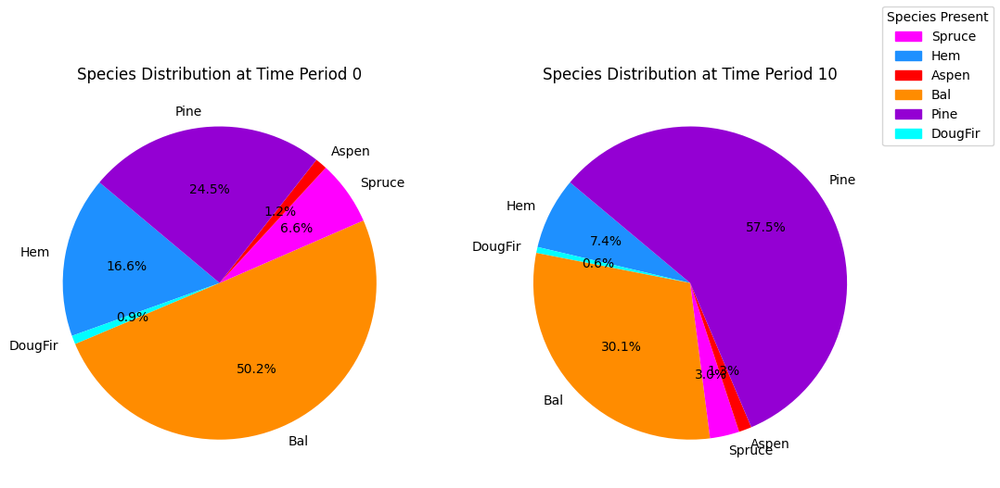

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


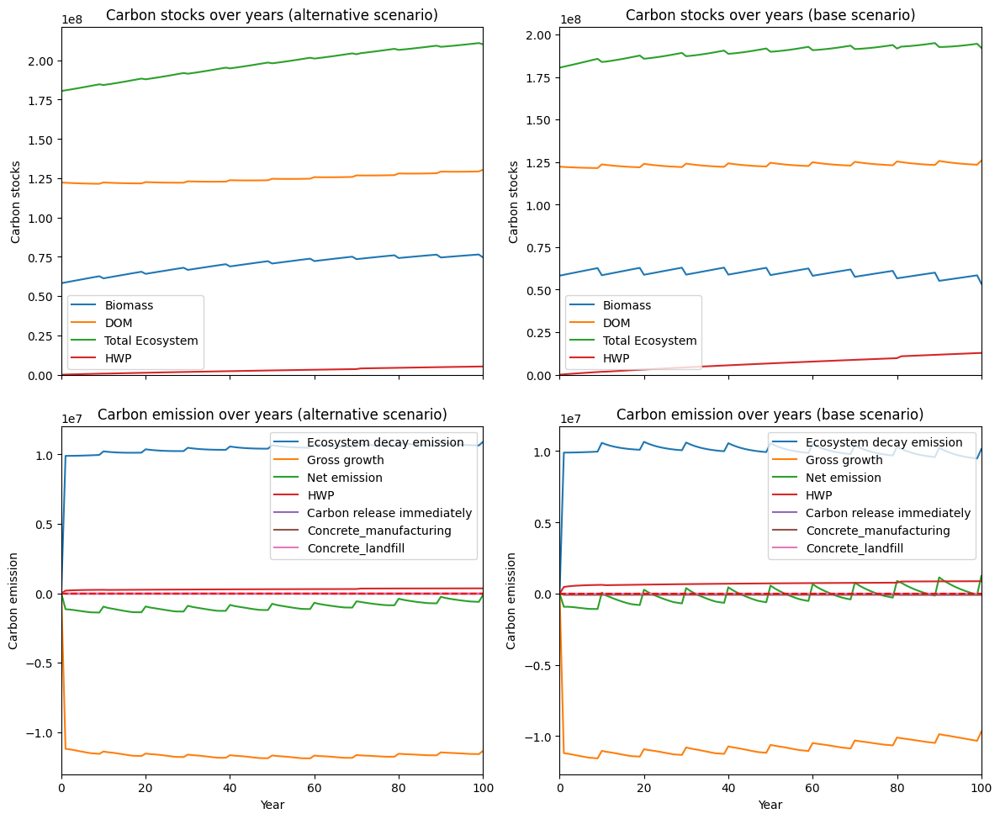

---------------------------------------------------------------------------------------
Net emission difference -15100737.047422383
Net emission base scenario -29018661.588458534
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.6622193319833317
Comparison of Old Growth Areas (Alternative - Base)
           0             10     Difference
Hem      0.0    4380.571840    4380.571840
DougFir  0.0    1120.945574    1120.945574
Bal      0.0   16188.098329   16188.098329
Spruce   0.0  100329.420387  100329.420387
Aspen    0.0   31628.794705   31628.794705
Pine     0.0   27328.595680   27328.595680

Overall, the old growth area has **increased** by 180976.43 hectares in the alternative scenario compared to the base scenario.


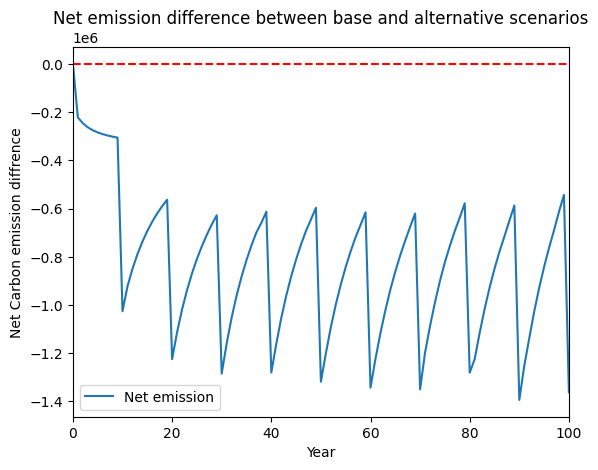

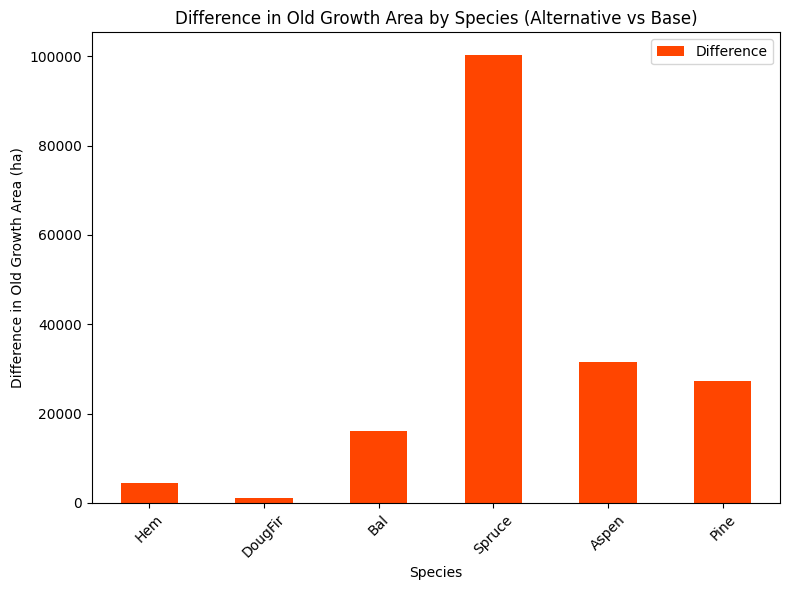

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


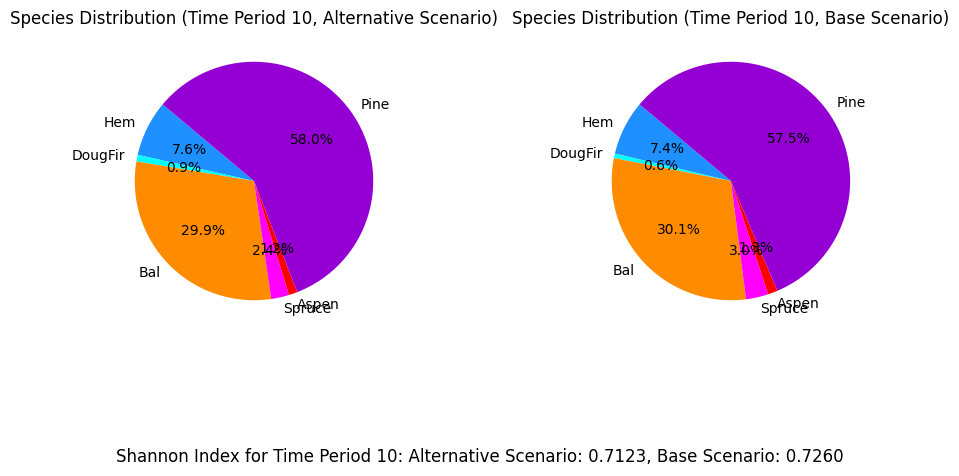

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_bau_eqtslvr...
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.34s
Presolved: 8375 ro

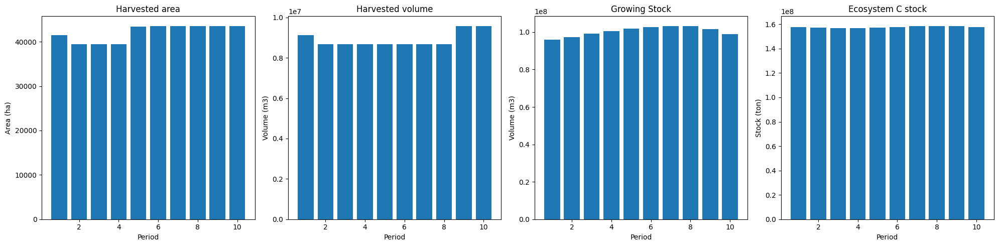

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


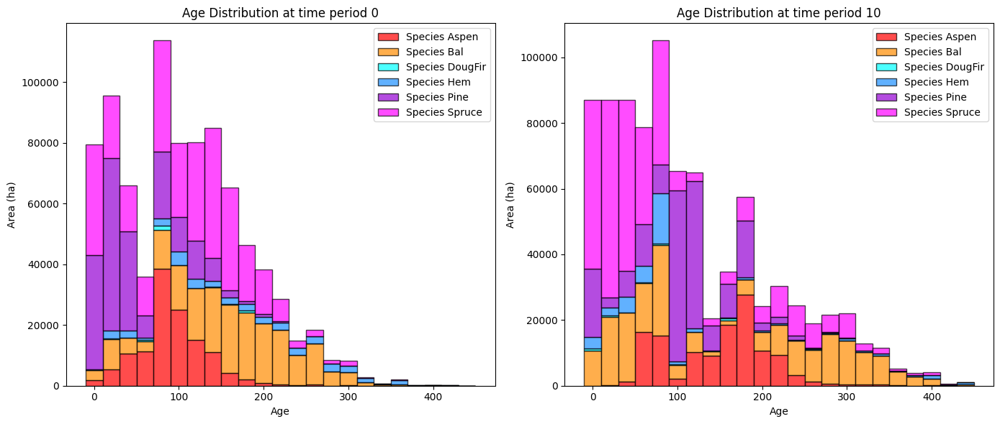

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


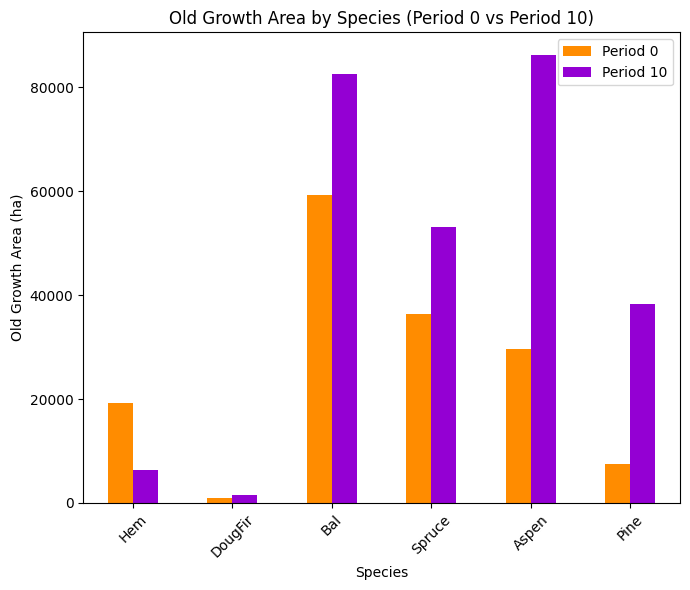

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


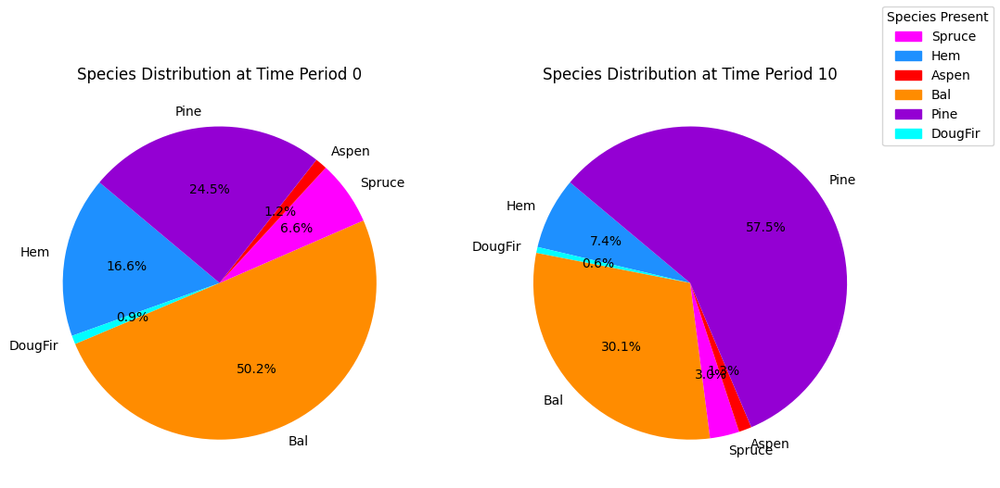

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.39s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Orderi

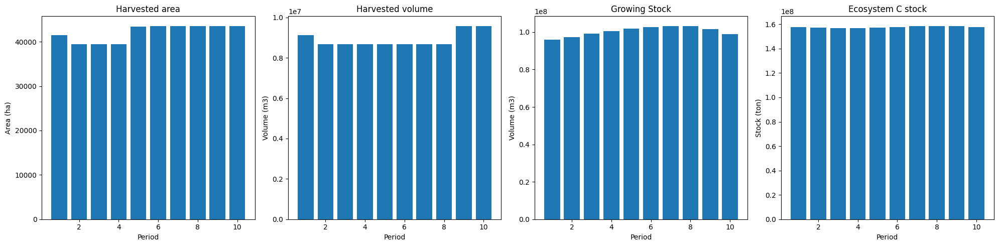

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


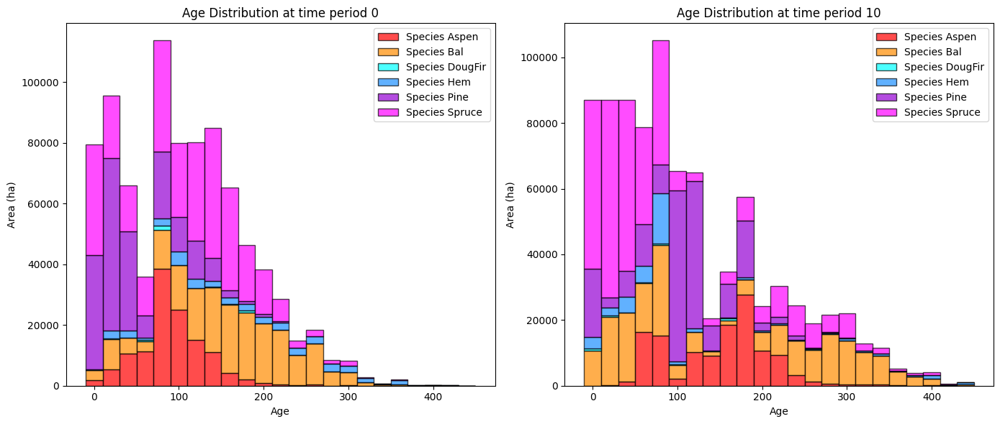

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


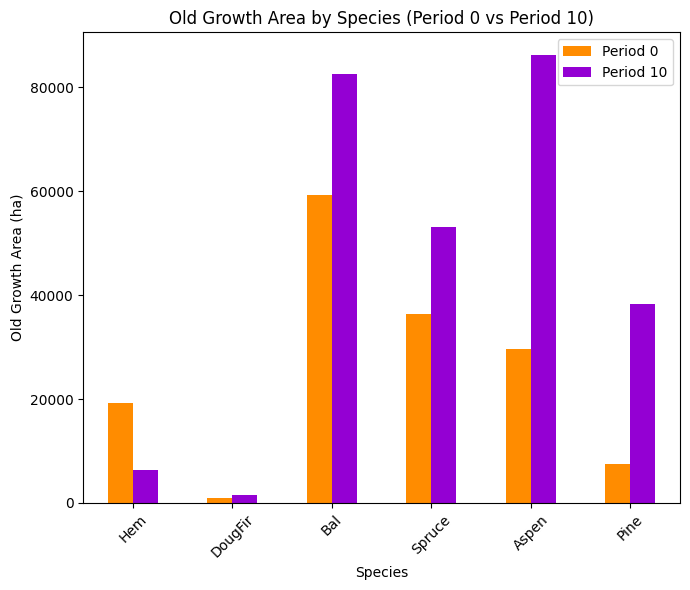

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


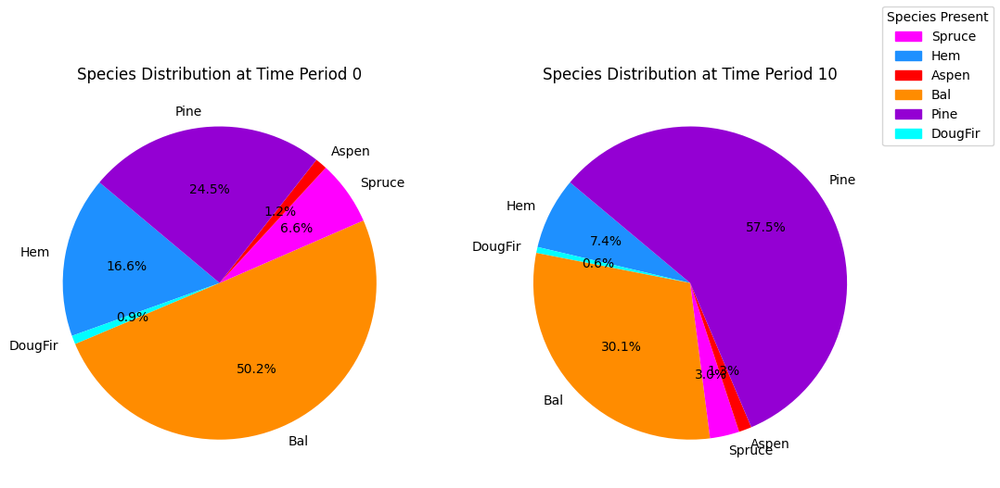

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


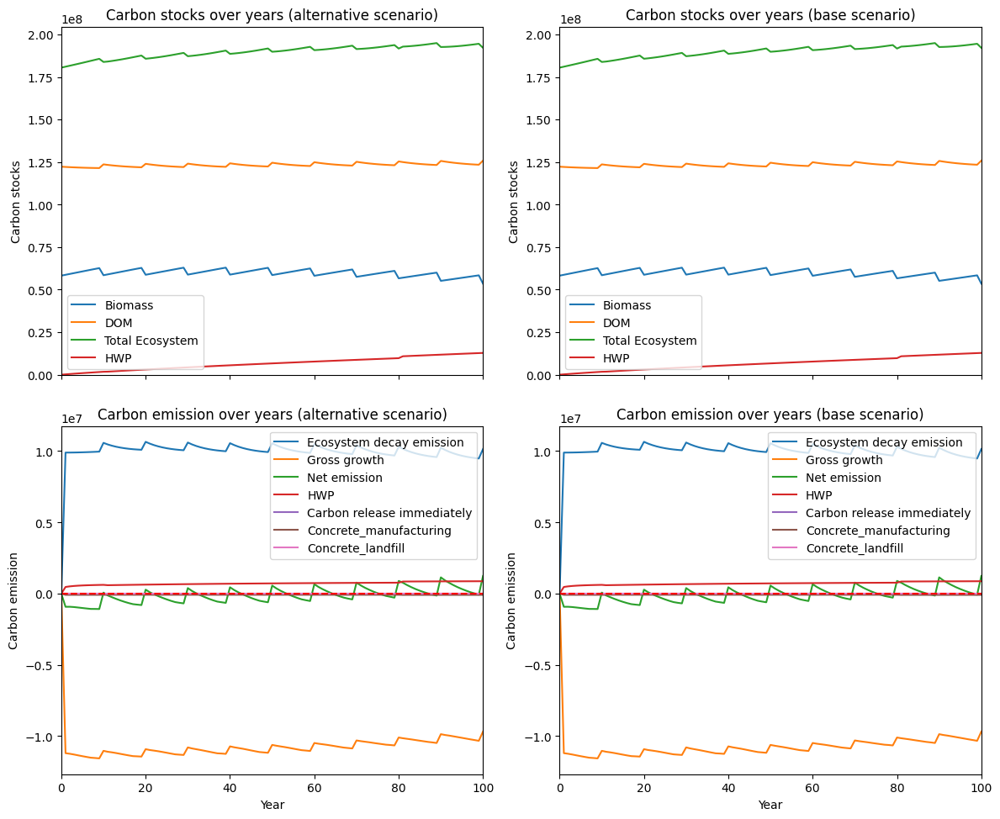

---------------------------------------------------------------------------------------
Net emission difference 0.0
Net emission base scenario -13917924.541036148
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  inf
Comparison of Old Growth Areas (Alternative - Base)
           0   10  Difference
Hem      0.0  0.0         0.0
DougFir  0.0  0.0         0.0
Bal      0.0  0.0         0.0
Spruce   0.0  0.0         0.0
Aspen    0.0  0.0         0.0
Pine     0.0  0.0         0.0

Overall, the old growth area has **increased** by 0.00 hectares in the alternative scenario compared to the base scenario.


/media/data/project/eghasemi/nbds_mining/util_opt.py:1211: RuntimeWarning: divide by zero encountered in scalar divide
  dollar_per_ton = abs(budget_input / dif_scenario.iloc[:25]['Net emission'].sum())


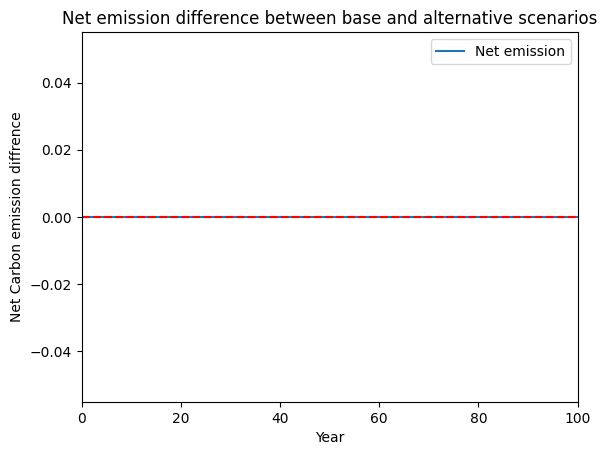

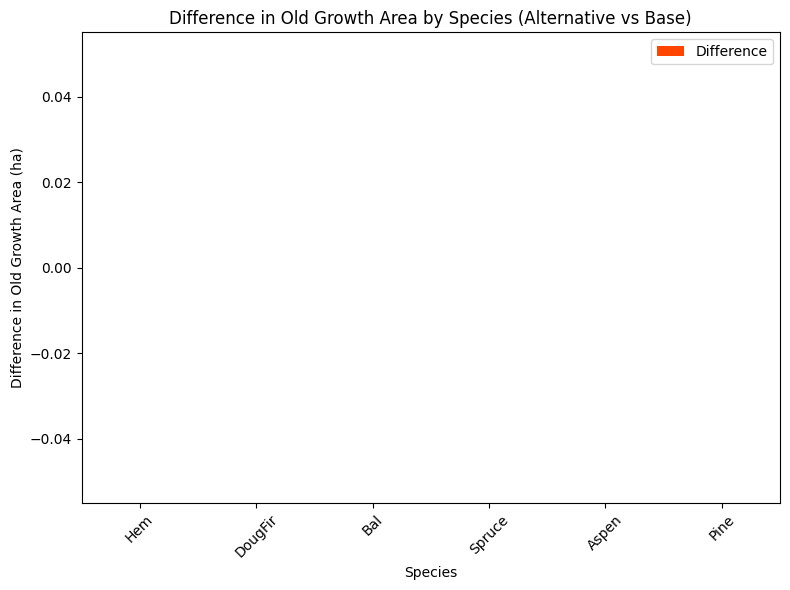

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


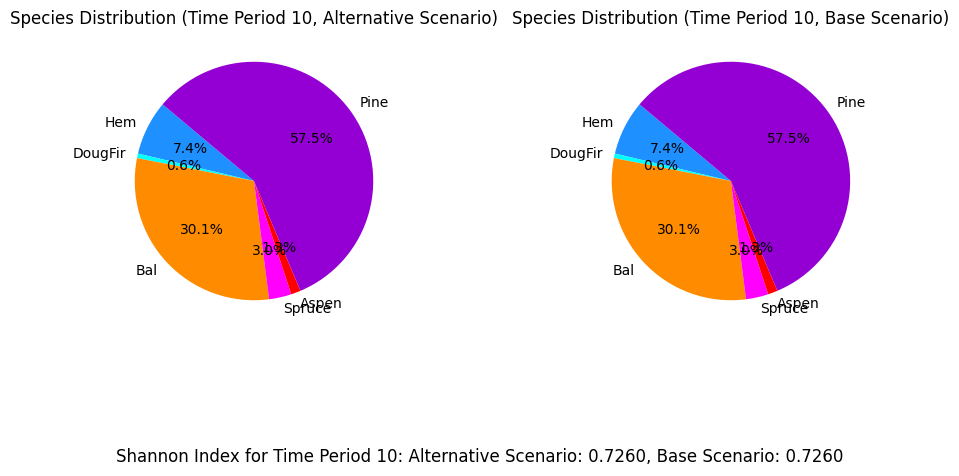

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_90%...
running the scenario for the Equity Silver mining site (90%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x8a1fbdf1
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.31s
Presolved: 8375 r

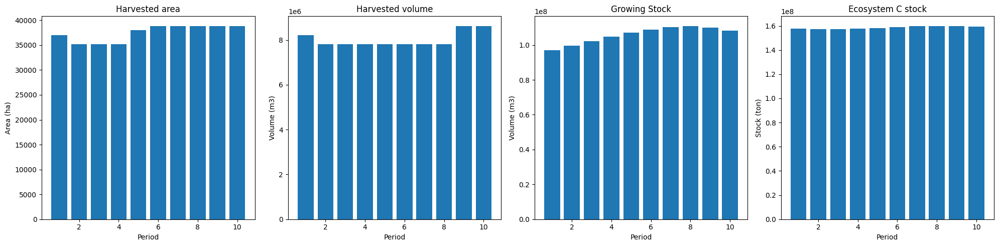

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_90%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  84678
The economic indicator (the provincial government revenues) is:  2887716
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


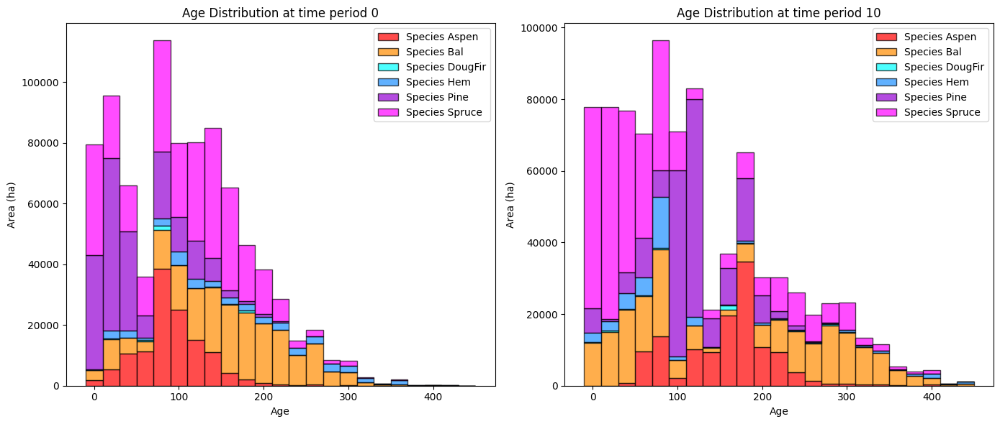

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_90%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   7216.472254 -11935.654975
DougFir    947.047810   1856.189930    909.142120
Bal      59315.970469  88278.443522  28962.473053
Spruce   36410.744598  53152.448451  16741.703853
Aspen    29632.731169  95000.428083  65367.696914
Pine      7432.733686  47249.209376  39816.475689

Overall diversity has **increased** by 139861.84 hectares from time period 0 to time period 10.


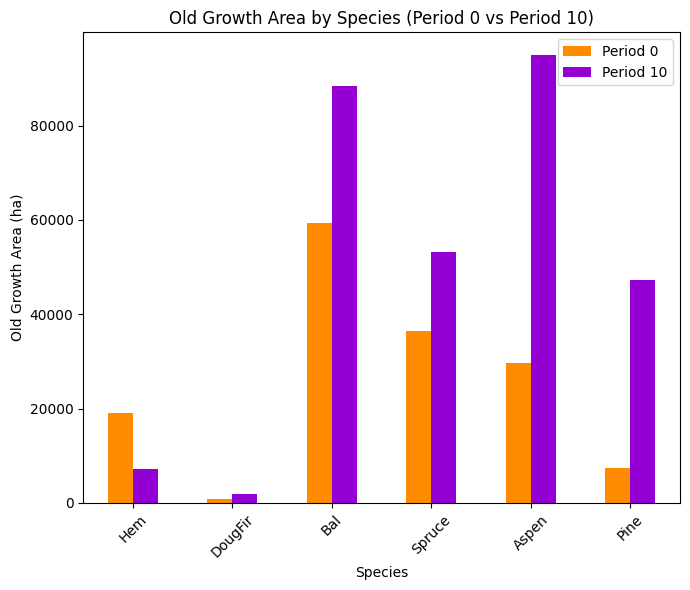

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_90%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7176

Diversity has **decreased** by 4.16% from time 0 to time 10.


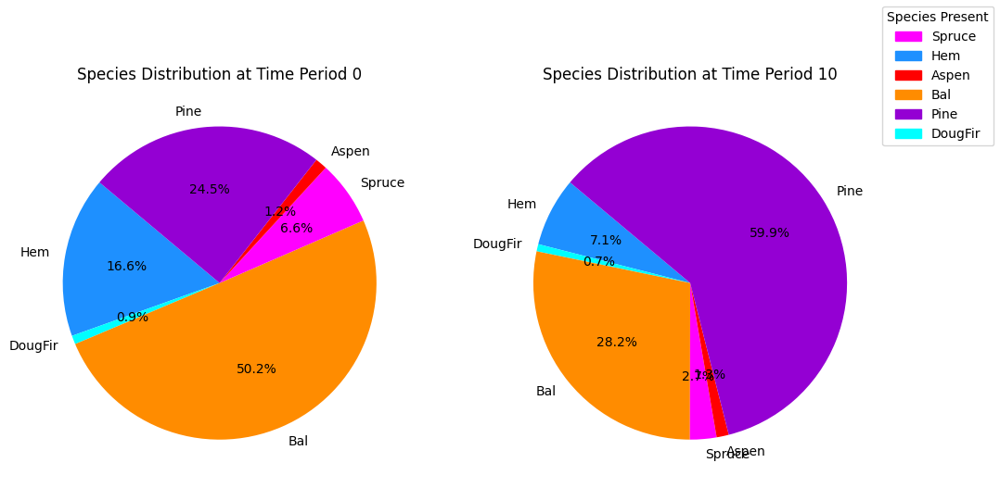

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_90%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.26s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

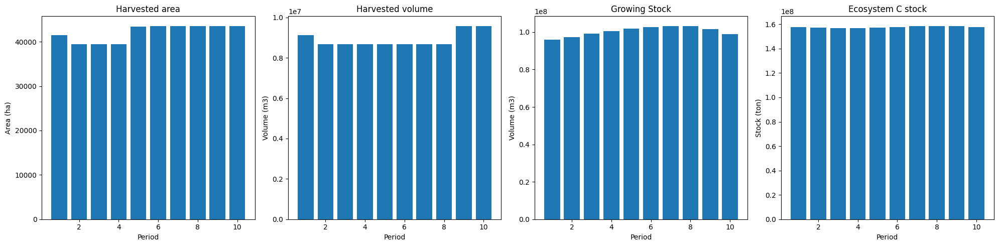

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


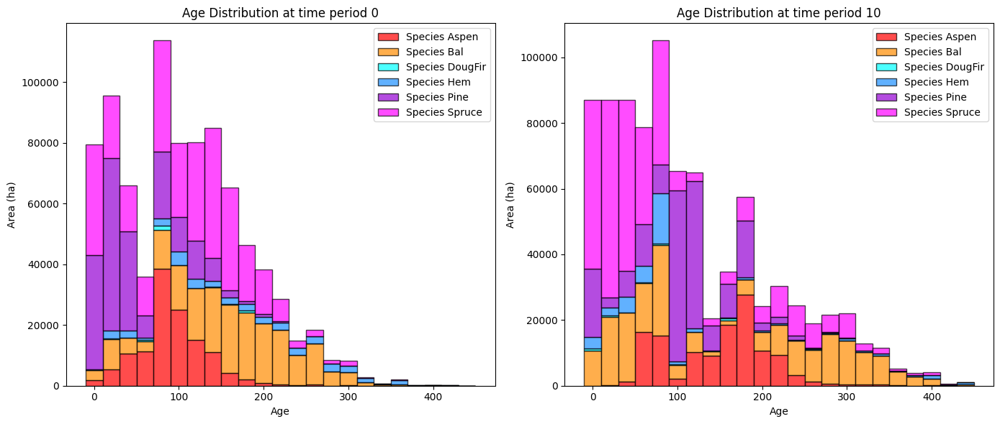

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


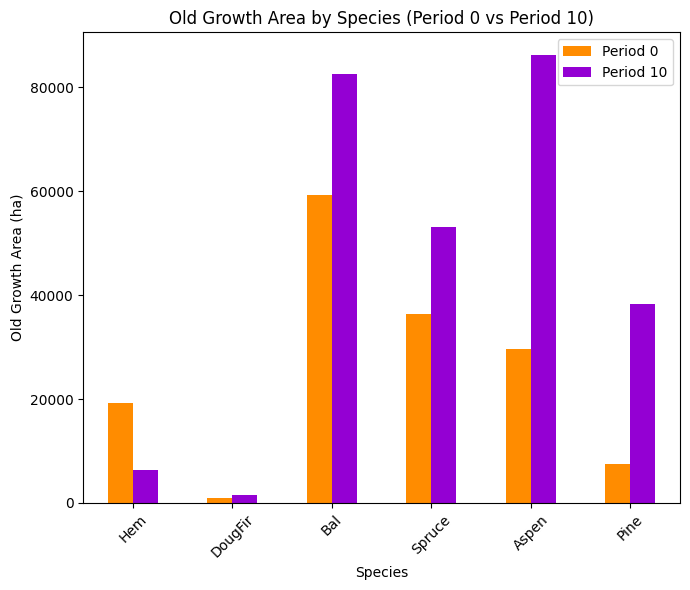

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


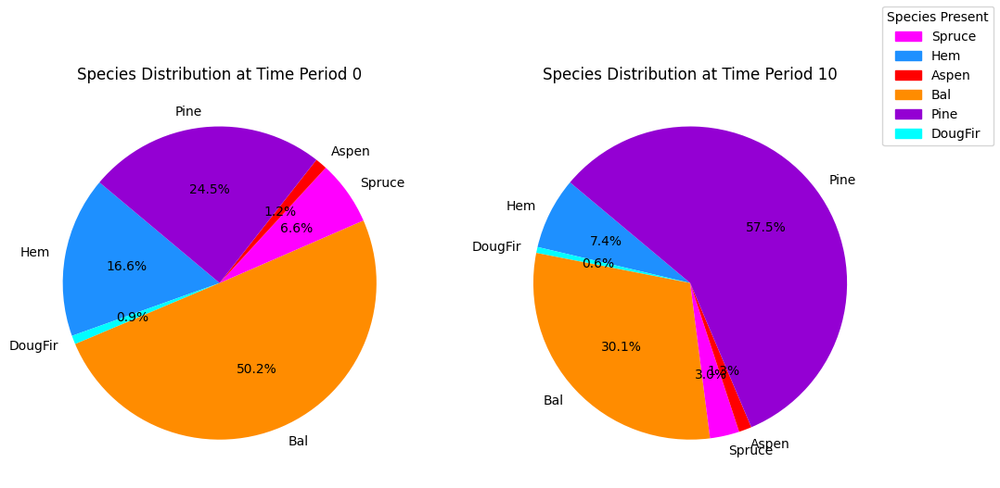

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


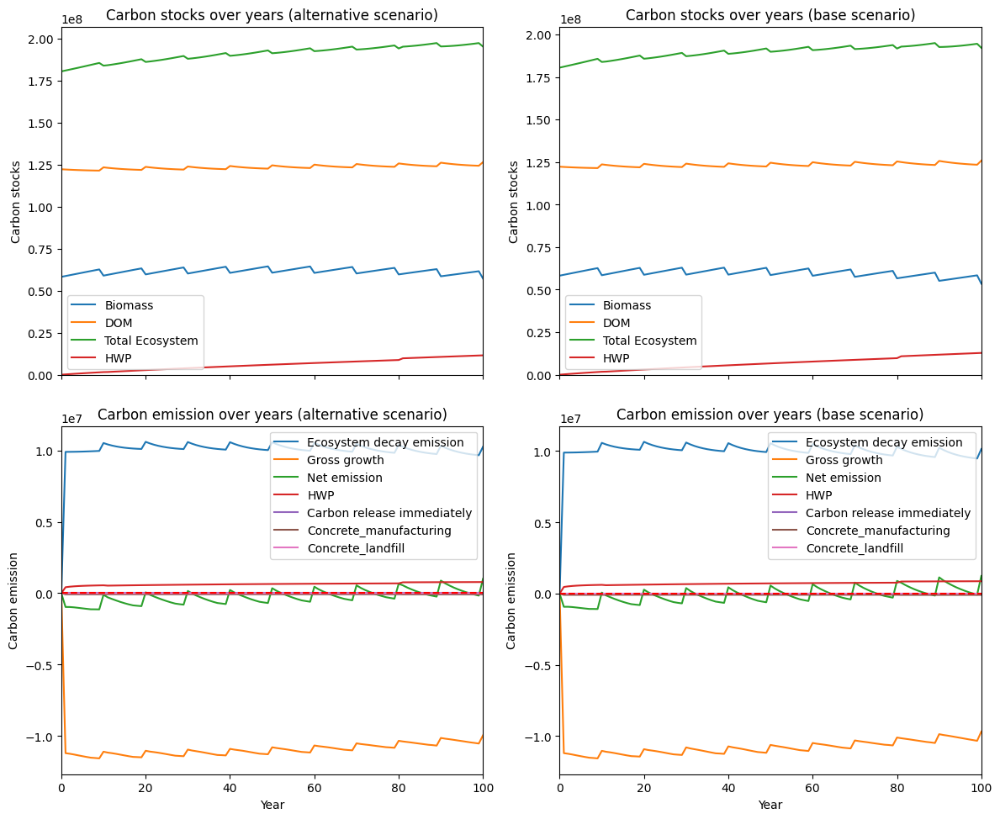

---------------------------------------------------------------------------------------
Net emission difference -2657518.80560134
Net emission base scenario -16575443.346637491
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  3.7629084614275055
Comparison of Old Growth Areas (Alternative - Base)
           0           10   Difference
Hem      0.0   880.212662   880.212662
DougFir  0.0   369.293918   369.293918
Bal      0.0  5667.820096  5667.820096
Spruce   0.0   124.982316   124.982316
Aspen    0.0  8776.369322  8776.369322
Pine     0.0  8995.640113  8995.640113

Overall, the old growth area has **increased** by 24814.32 hectares in the alternative scenario compared to the base scenario.


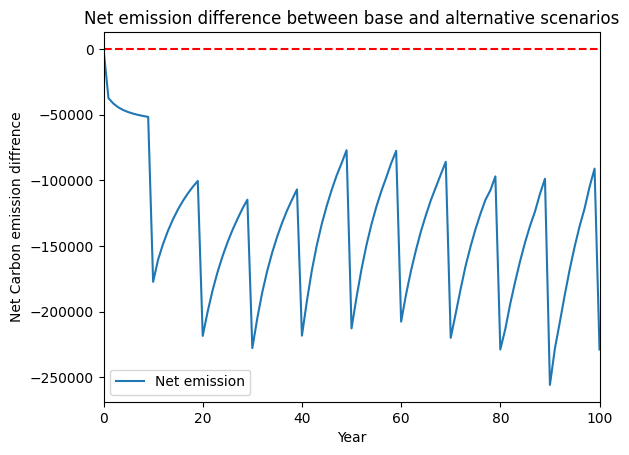

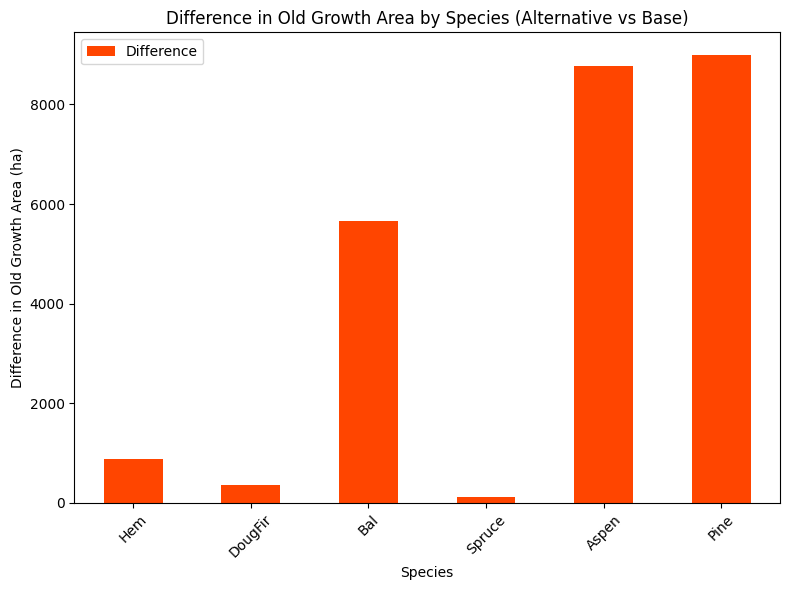

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


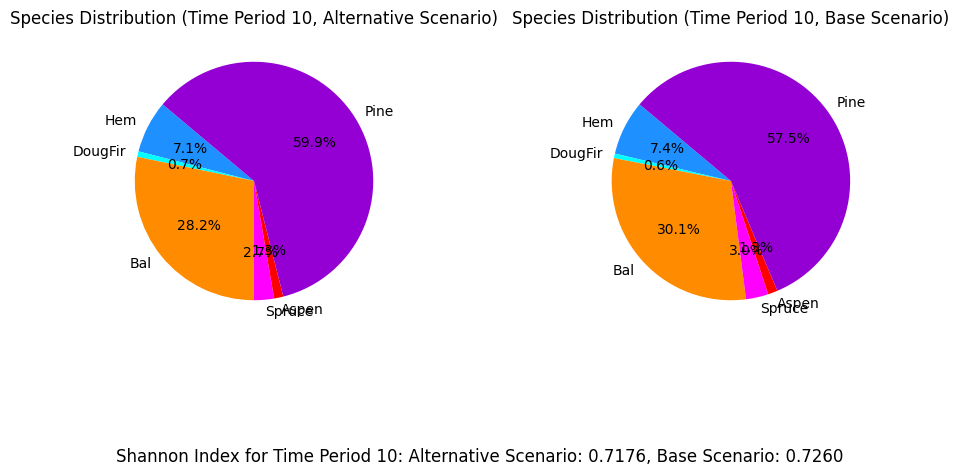

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_80%...
running the scenario for the Equity Silver mining site (80%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x886f03ed
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.23s
Presolved: 8375 r

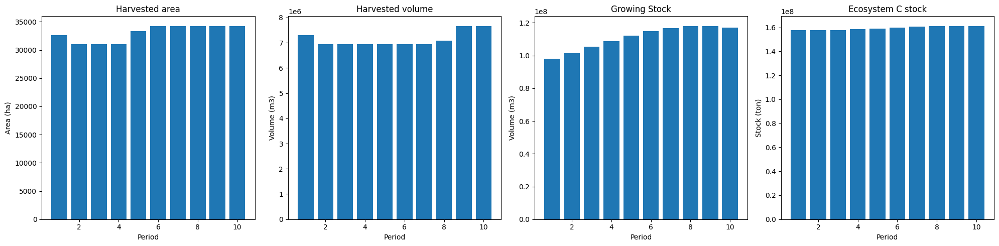

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_80%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  75430
The economic indicator (the provincial government revenues) is:  2572352
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


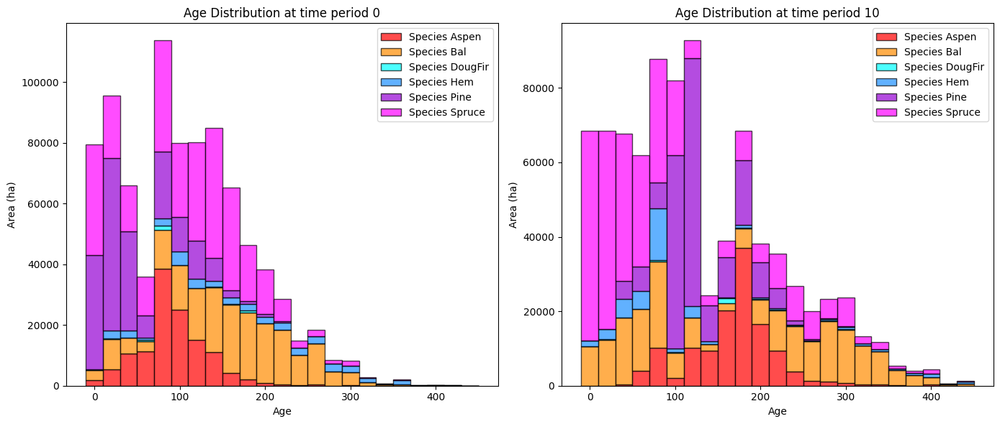

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_80%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    7869.127036 -11283.000193
DougFir    947.047810    2013.028648   1065.980838
Bal      59315.970469   91178.288248  31862.317779
Spruce   36410.744598   53783.965712  17373.221114
Aspen    29632.731169  104630.392780  74997.661611
Pine      7432.733686   55223.851148  47791.117462

Overall diversity has **increased** by 161807.30 hectares from time period 0 to time period 10.


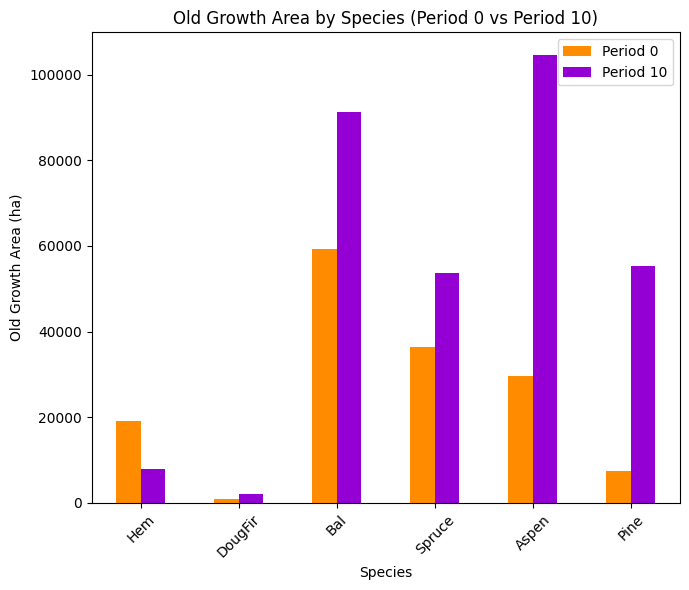

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_80%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7167

Diversity has **decreased** by 4.25% from time 0 to time 10.


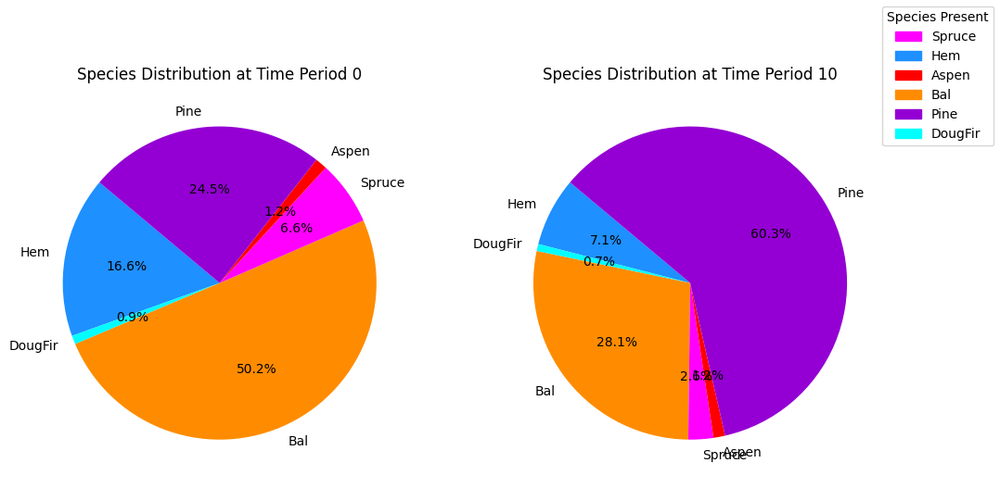

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_80%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.22s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

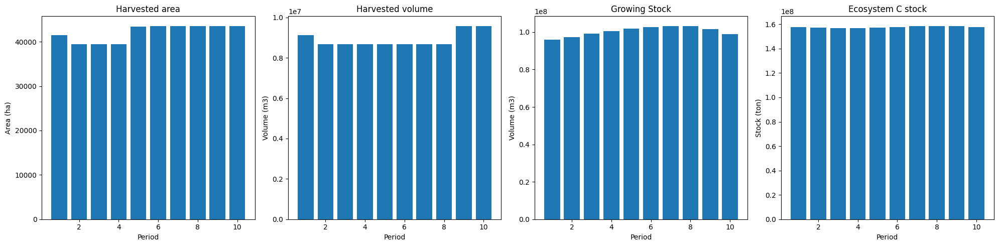

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


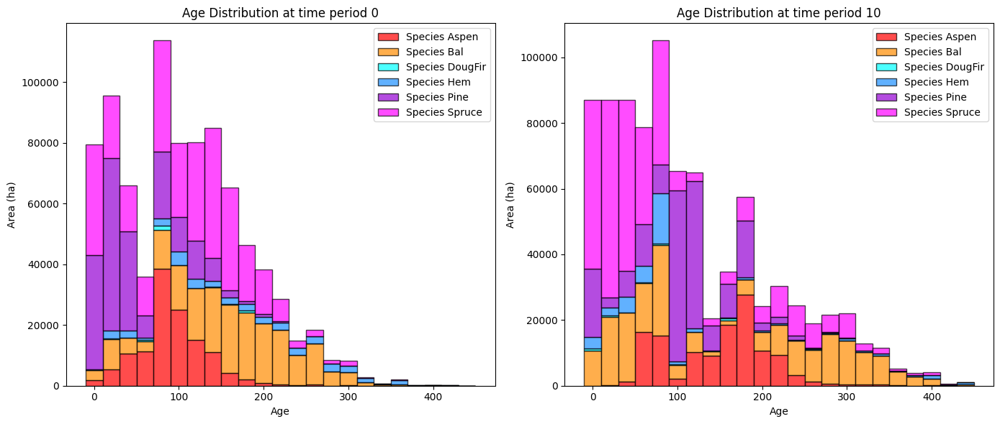

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


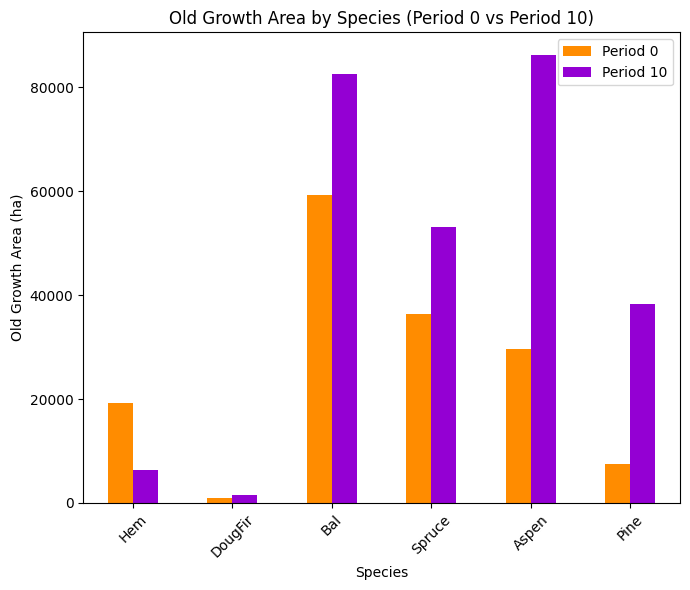

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


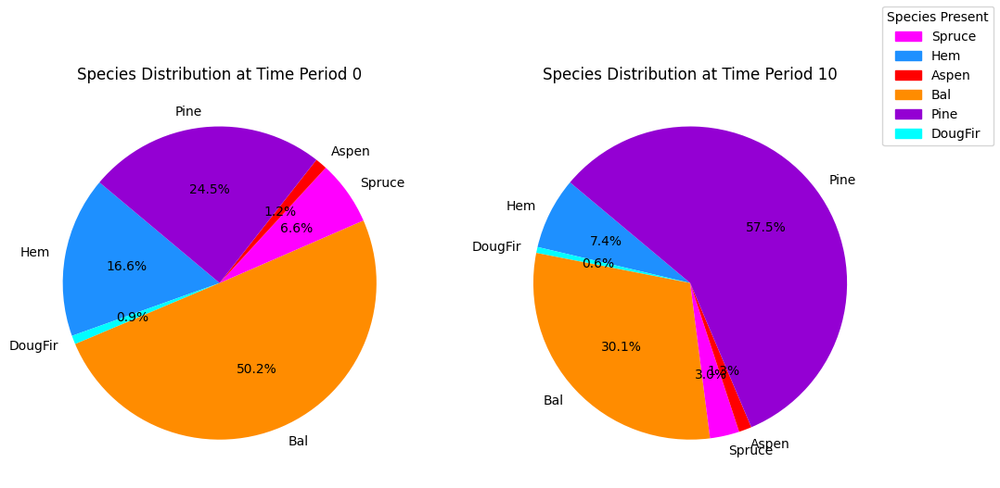

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


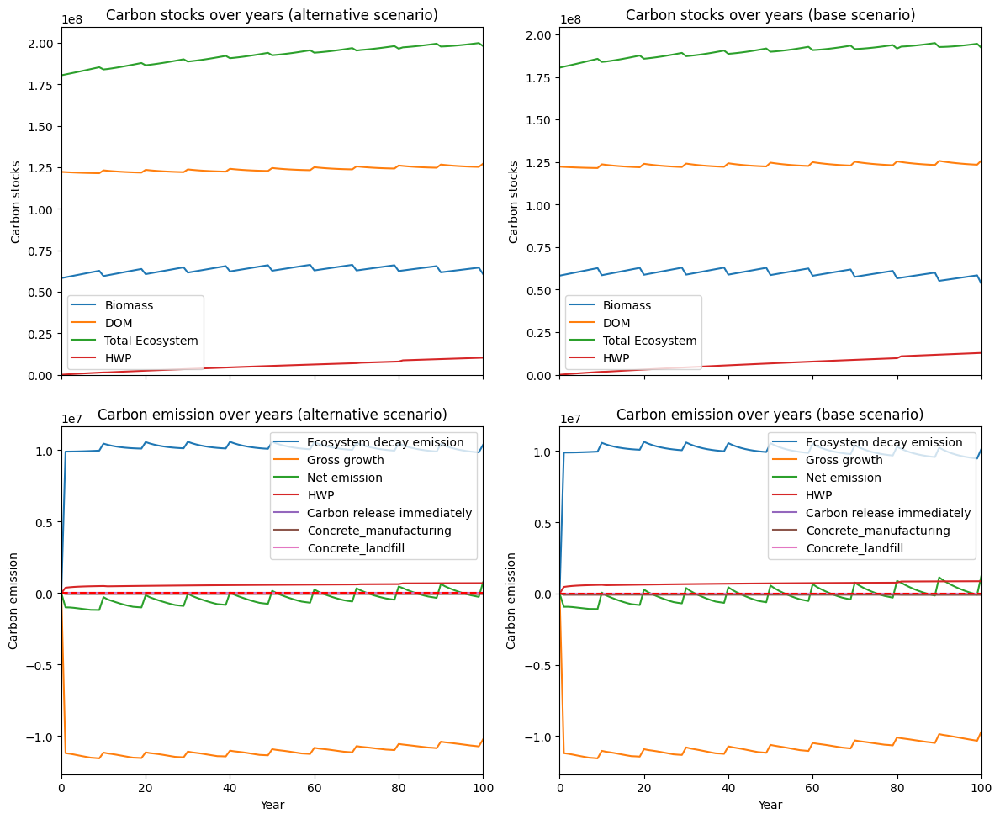

---------------------------------------------------------------------------------------
Net emission difference -5246390.294935034
Net emission base scenario -19164314.835971184
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  1.9060724494047254
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   1532.867444   1532.867444
DougFir  0.0    526.132636    526.132636
Bal      0.0   8567.664822   8567.664822
Spruce   0.0    756.499577    756.499577
Aspen    0.0  18406.334018  18406.334018
Pine     0.0  16970.281886  16970.281886

Overall, the old growth area has **increased** by 46759.78 hectares in the alternative scenario compared to the base scenario.


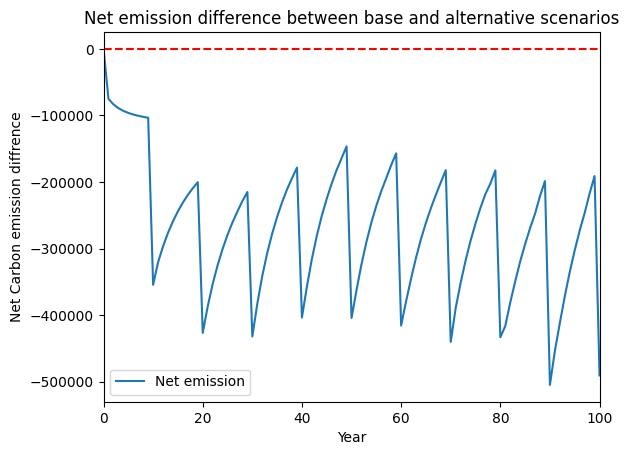

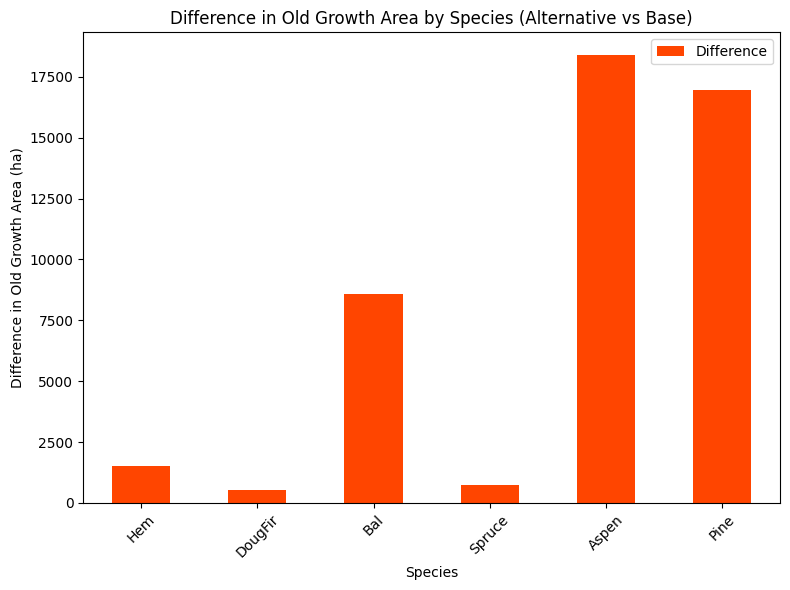

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


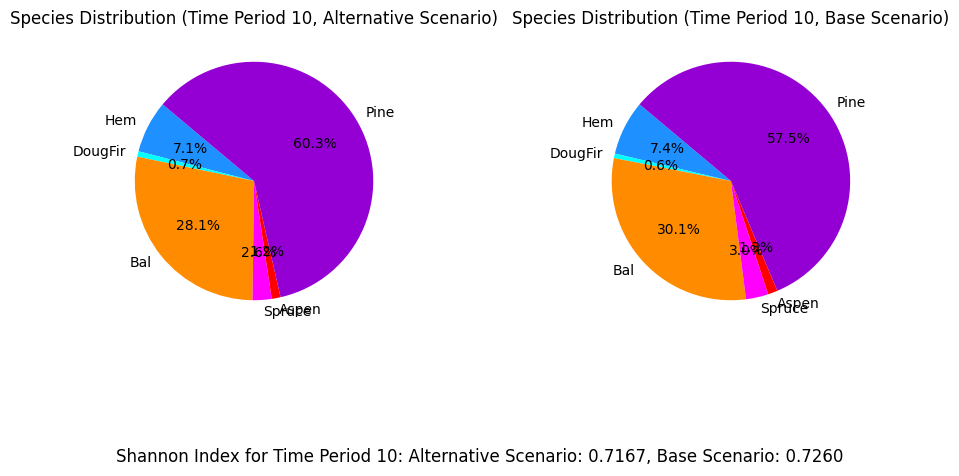

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_70%...
running the scenario for the Equity Silver mining site (70%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xcc6f6514
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.23s
Presolved: 8375 r

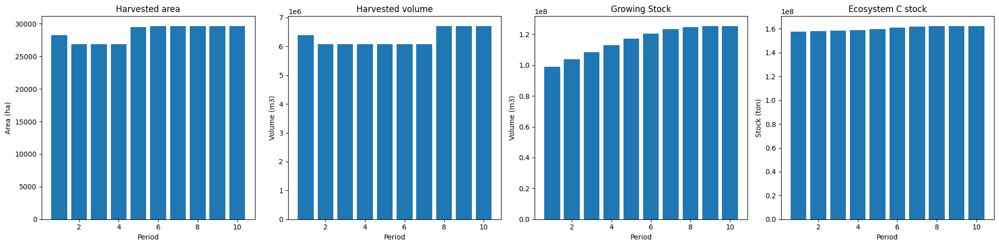

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_70%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  66536
The economic indicator (the provincial government revenues) is:  2269037
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


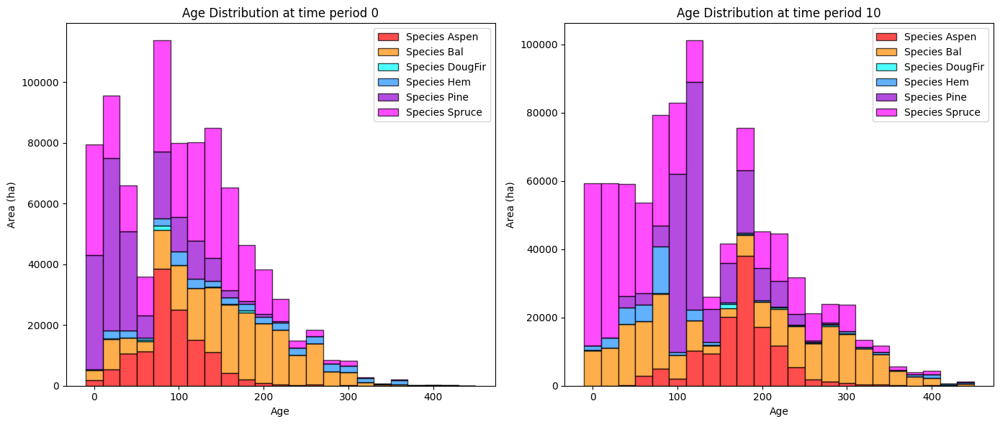

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_70%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    7927.094758 -11225.032471
DougFir    947.047810    2329.596842   1382.549032
Bal      59315.970469   92552.648547  33236.678078
Spruce   36410.744598   68605.450719  32194.706121
Aspen    29632.731169  111035.698516  81402.967347
Pine      7432.733686   60896.150399  53463.416713

Overall diversity has **increased** by 190455.28 hectares from time period 0 to time period 10.


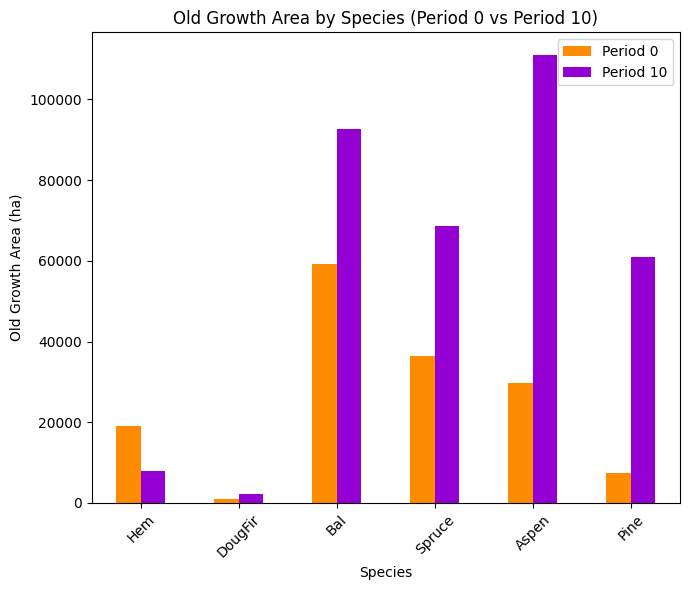

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_70%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7201

Diversity has **decreased** by 3.91% from time 0 to time 10.


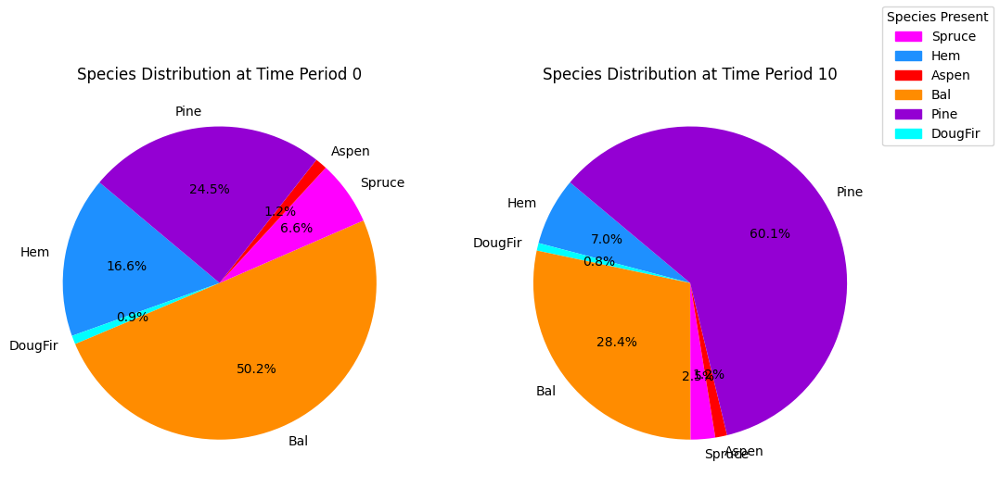

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_70%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.24s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

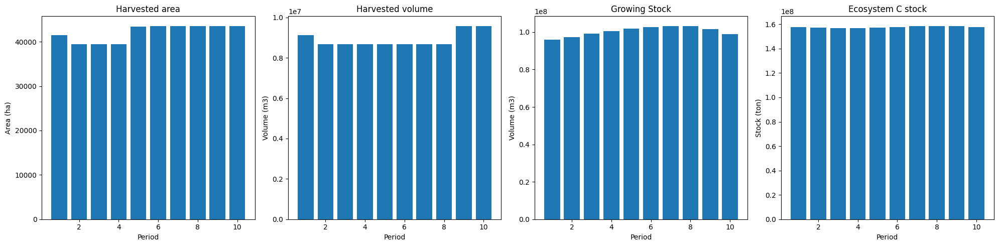

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


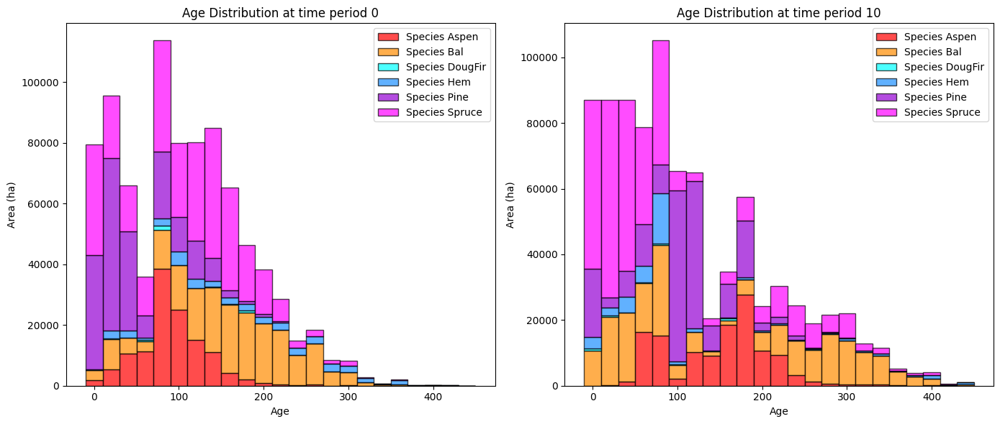

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


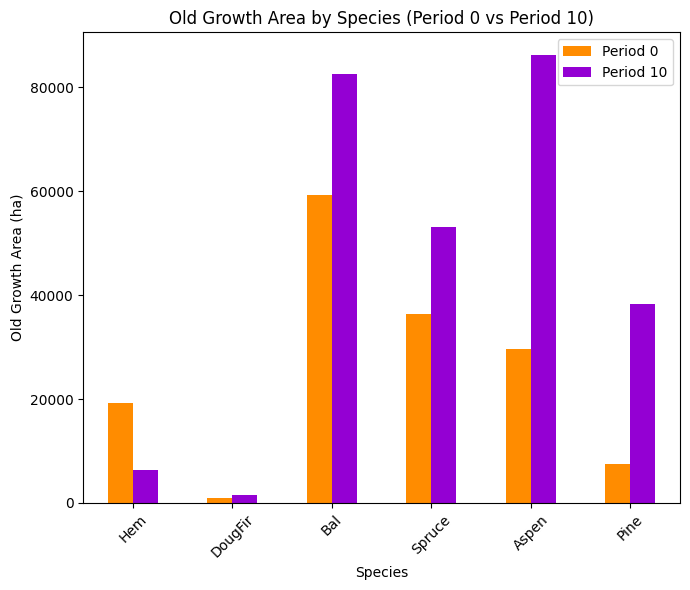

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


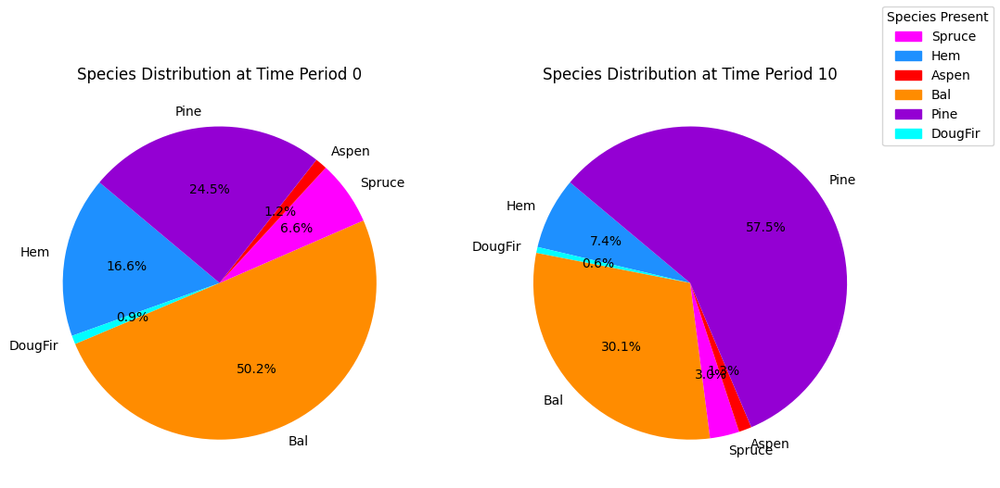

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


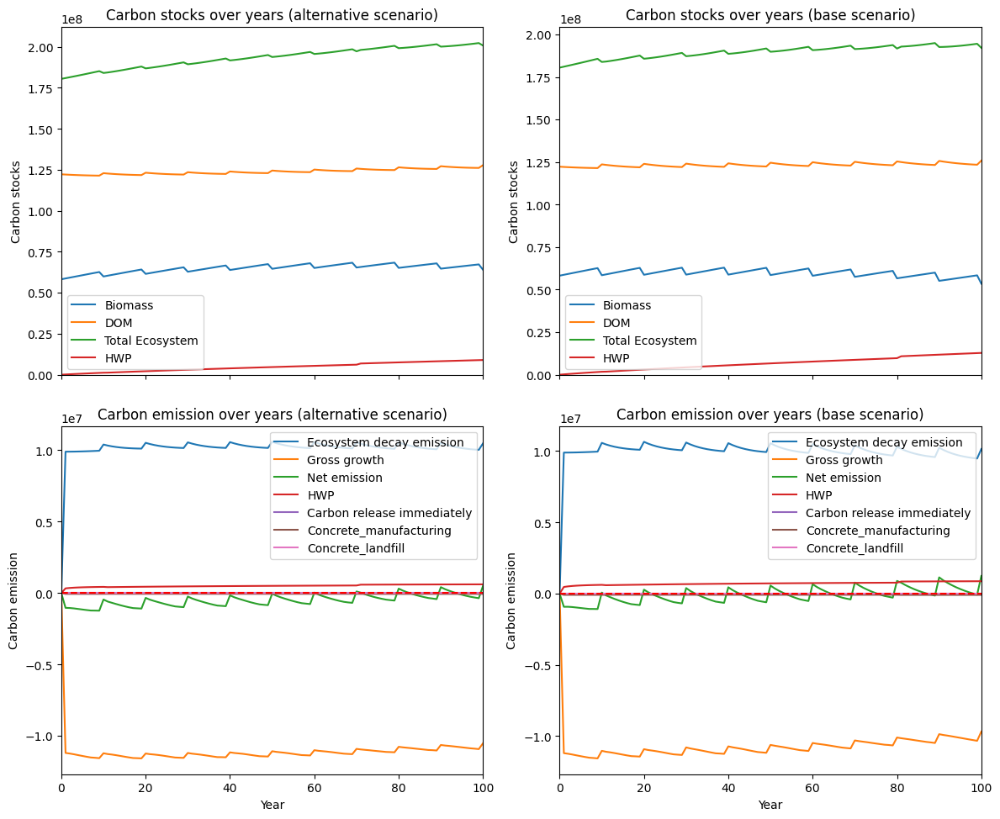

---------------------------------------------------------------------------------------
Net emission difference -7616886.476031851
Net emission base scenario -21534811.017068
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  1.312872396282539
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   1590.835166   1590.835166
DougFir  0.0    842.700830    842.700830
Bal      0.0   9942.025121   9942.025121
Spruce   0.0  15577.984584  15577.984584
Aspen    0.0  24811.639754  24811.639754
Pine     0.0  22642.581137  22642.581137

Overall, the old growth area has **increased** by 75407.77 hectares in the alternative scenario compared to the base scenario.


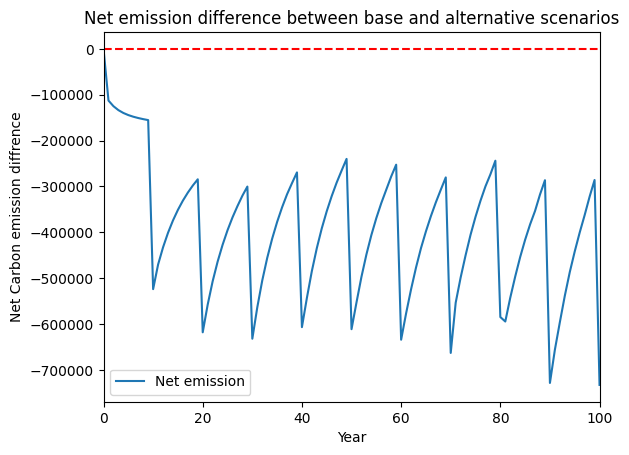

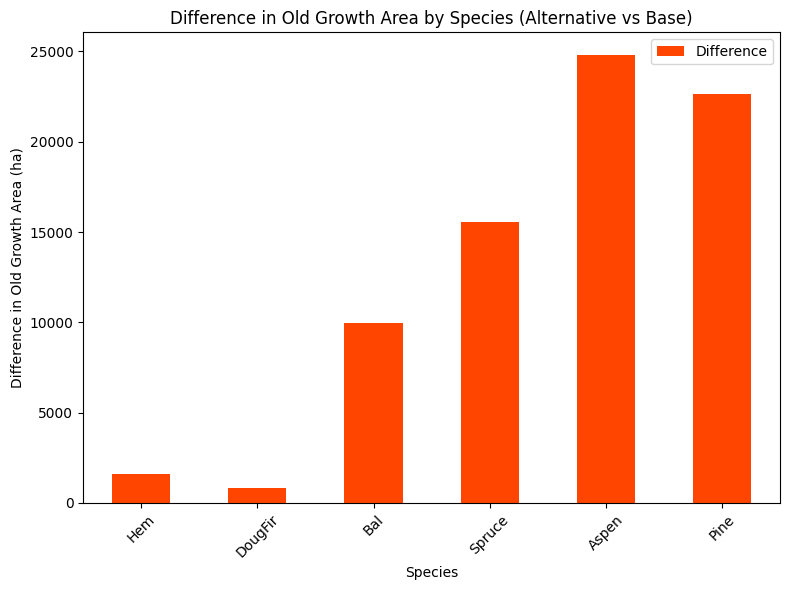

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


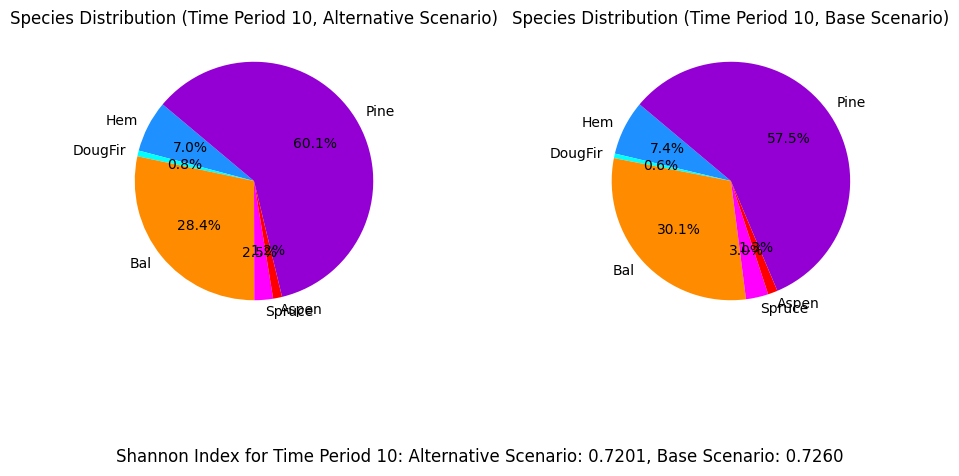

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_60%...
running the scenario for the Equity Silver mining site (60%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x7854cec6
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.23s
Presolved: 8375 r

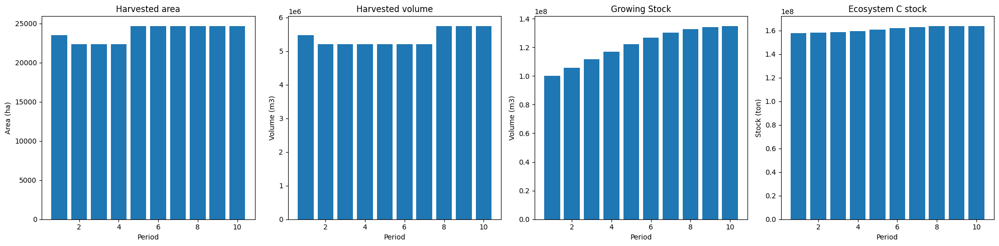

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_60%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  57031
The economic indicator (the provincial government revenues) is:  1944889
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


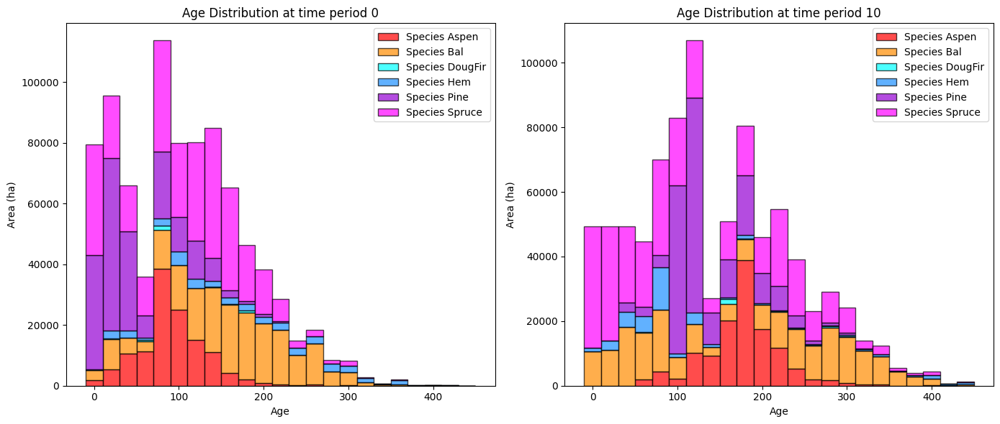

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_60%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    8558.090221 -10594.037007
DougFir    947.047810    2572.498932   1625.451122
Bal      59315.970469   94207.030586  34891.060117
Spruce   36410.744598   97161.924830  60751.180232
Aspen    29632.731169  112855.799874  83223.068705
Pine      7432.733686   63665.381800  56232.648114

Overall diversity has **increased** by 226129.37 hectares from time period 0 to time period 10.


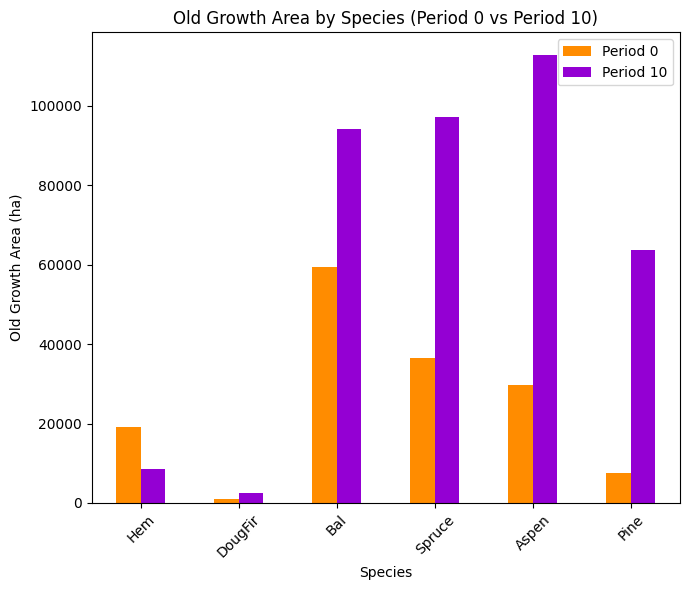

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_60%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7214

Diversity has **decreased** by 3.78% from time 0 to time 10.


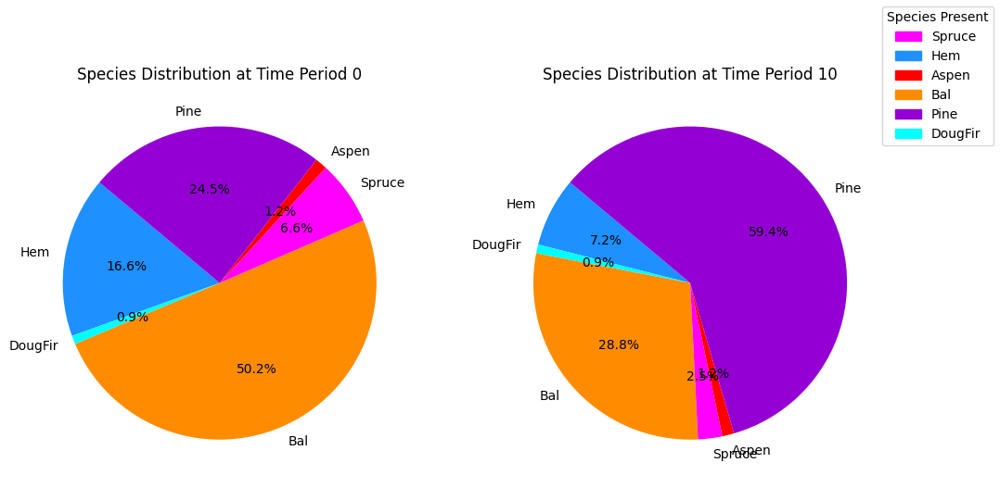

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_60%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.30s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

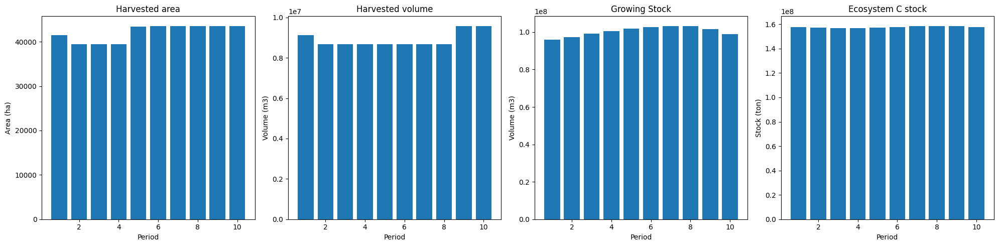

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


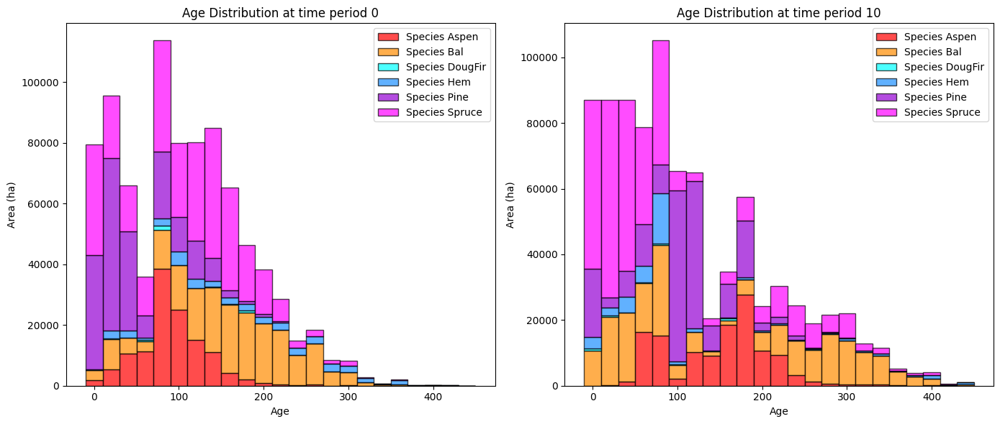

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


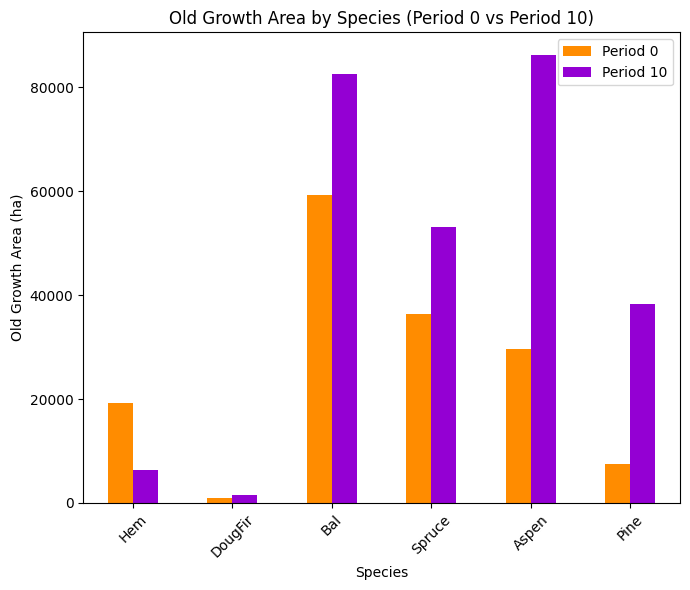

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


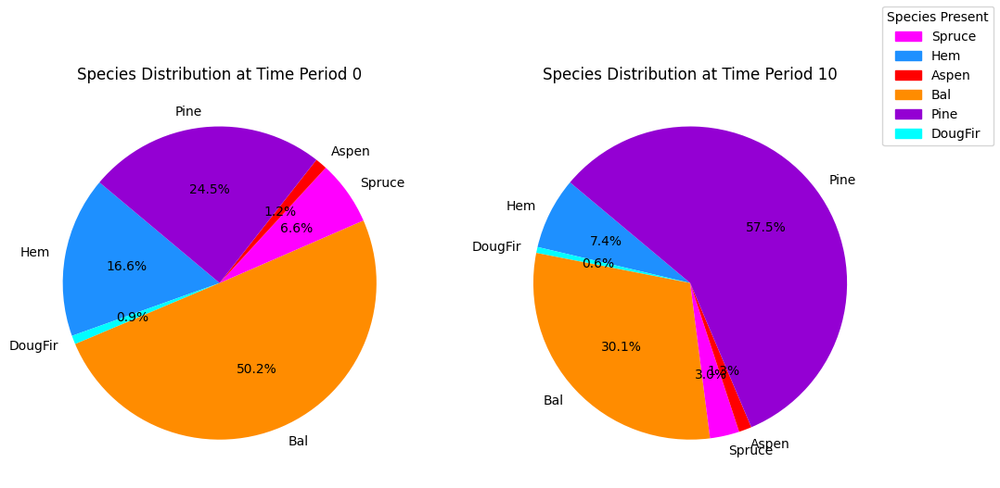

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


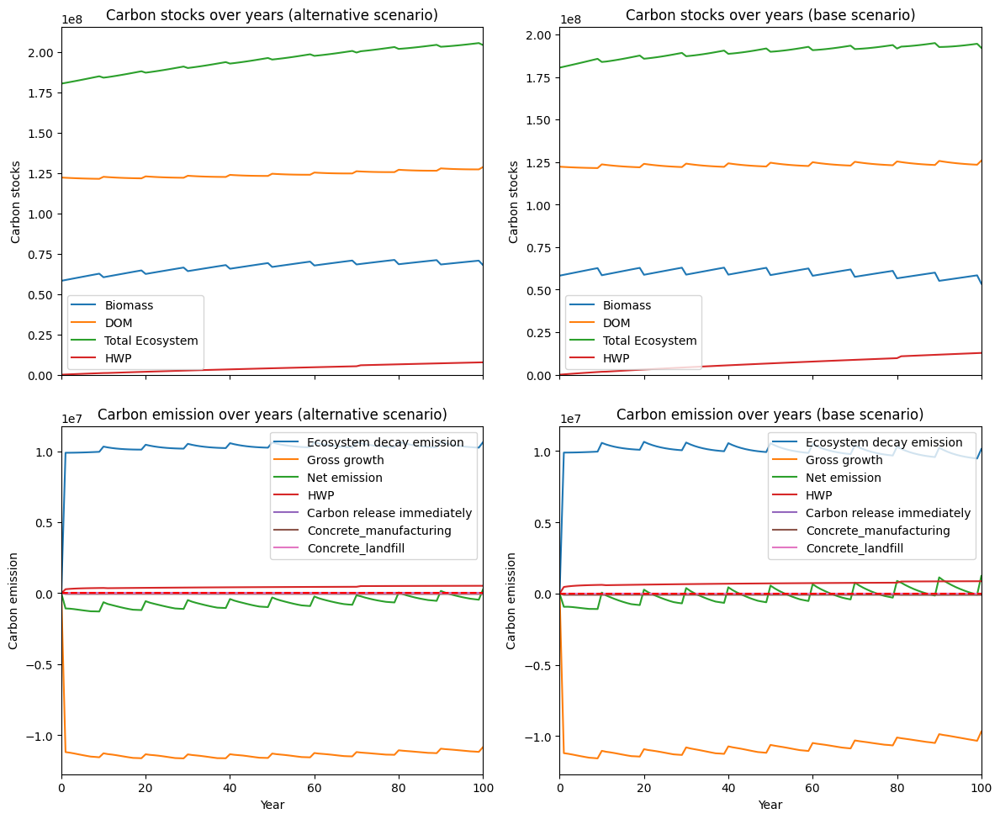

---------------------------------------------------------------------------------------
Net emission difference -10314044.271610927
Net emission base scenario -24231968.812647074
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.9695517816929171
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   2221.830630   2221.830630
DougFir  0.0   1085.602920   1085.602920
Bal      0.0  11596.407160  11596.407160
Spruce   0.0  44134.458695  44134.458695
Aspen    0.0  26631.741112  26631.741112
Pine     0.0  25411.812537  25411.812537

Overall, the old growth area has **increased** by 111081.85 hectares in the alternative scenario compared to the base scenario.


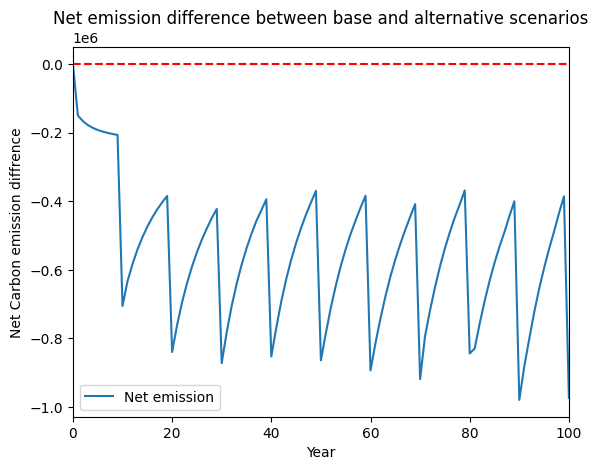

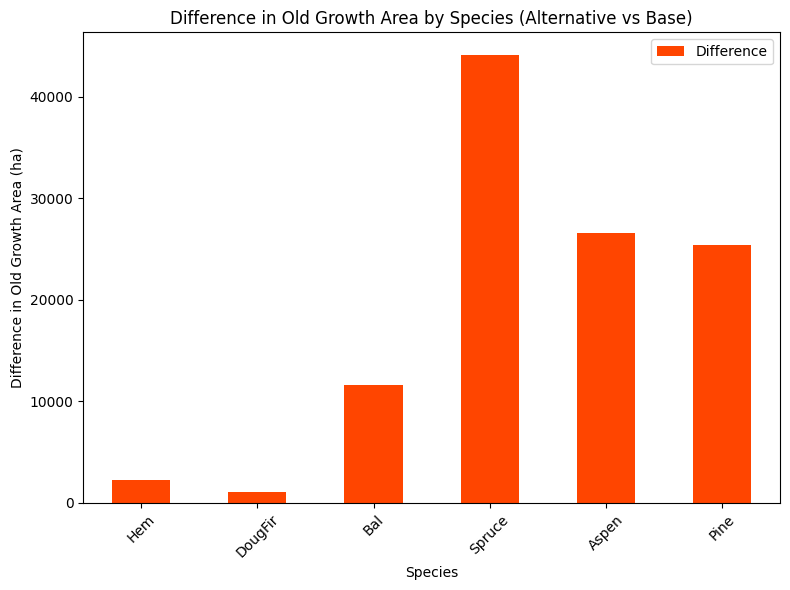

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


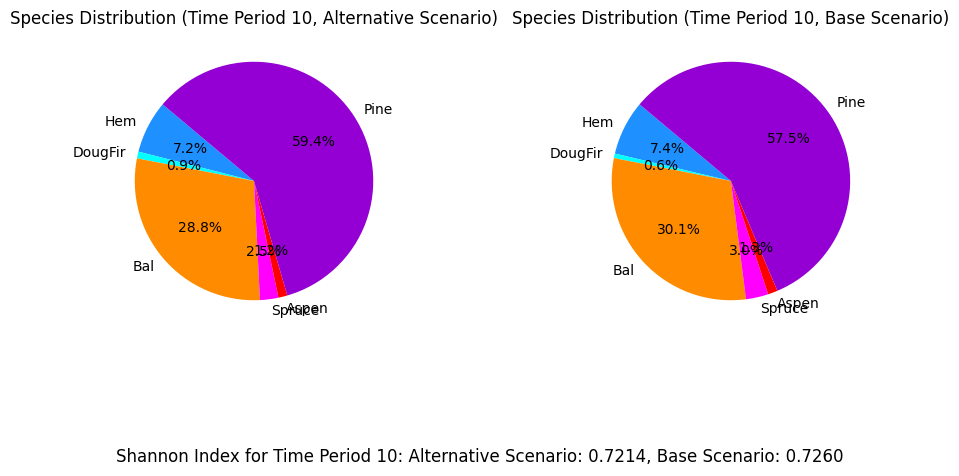

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_50%...
running the scenario for the Equity Silver mining site (50%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x3e73f2a1
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8231 rows and 8227 columns
Presolve time: 0.06s

Solved in 0 iter

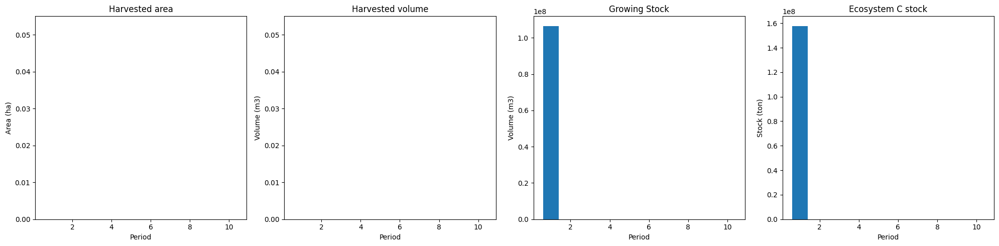

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_50%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  0
The economic indicator (the provincial government revenues) is:  0
------------------------------------------------


UnboundLocalError: local variable 'sch' referenced before assignment

In [12]:
Start = time.time()
scenario_names = scenario_options.get(case_study, [])
for scenario_name in scenario_names:
    print(f"Running for {case_study}_{obj_mode}_{scenario_name}...")
    results_scenarios(fm, 
                      clt_percentage, 
                      credibility, 
                      budget_input, 
                      n_steps, 
                      max_harvest, 
                      scenario_name, 
                      displacement_effect, 
                      hwp_pool_effect_value, 
                      release_immediately_value, 
                      case_study, 
                      obj_mode,                   
                      pickle_output_base=False, 
                      pickle_output_alter=False)
print('It took', round((time.time() - Start) / 60, 1), "minutes to run all scenarios.")

Running for equitysilver_max_st_eqtslvr_AAC_50%...
running the scenario for the Equity Silver mining site (50%_AAC),
Set parameter Username
Academic license - for non-commercial use only - expires 2025-01-09
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x9f5283f2
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.24s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier l

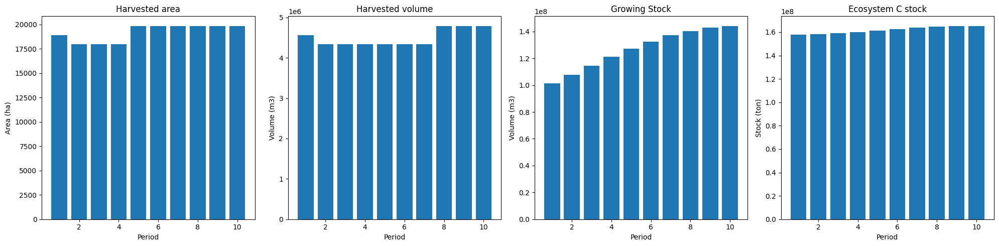

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_50%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  47526
The economic indicator (the provincial government revenues) is:  1620741
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


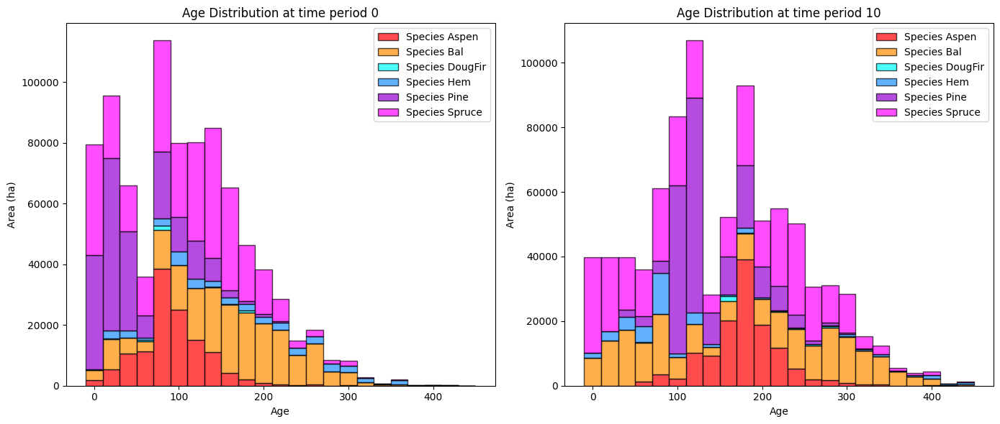

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_50%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    8924.037696 -10228.089532
DougFir    947.047810    2587.448146   1640.400336
Bal      59315.970469   95550.158355  36234.187887
Spruce   36410.744598  133537.938785  97127.194187
Aspen    29632.731169  114324.783990  84692.052821
Pine      7432.733686   64675.837444  57243.103758

Overall diversity has **increased** by 266708.85 hectares from time period 0 to time period 10.


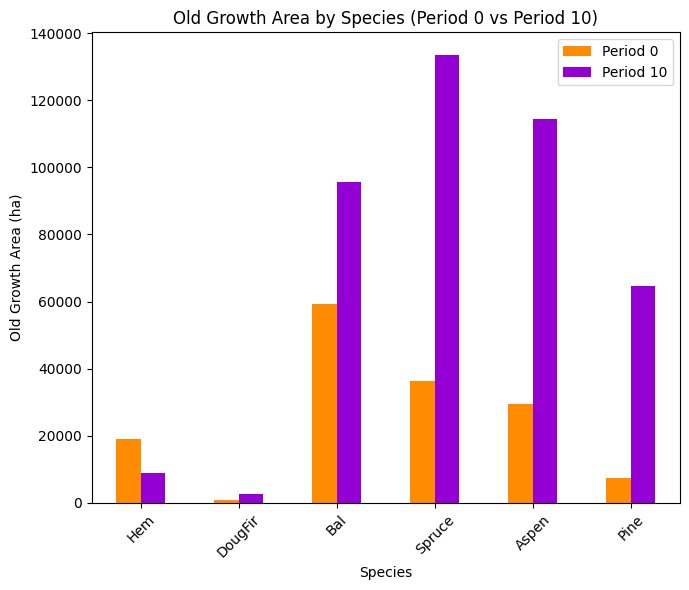

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_50%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7158

Diversity has **decreased** by 4.34% from time 0 to time 10.


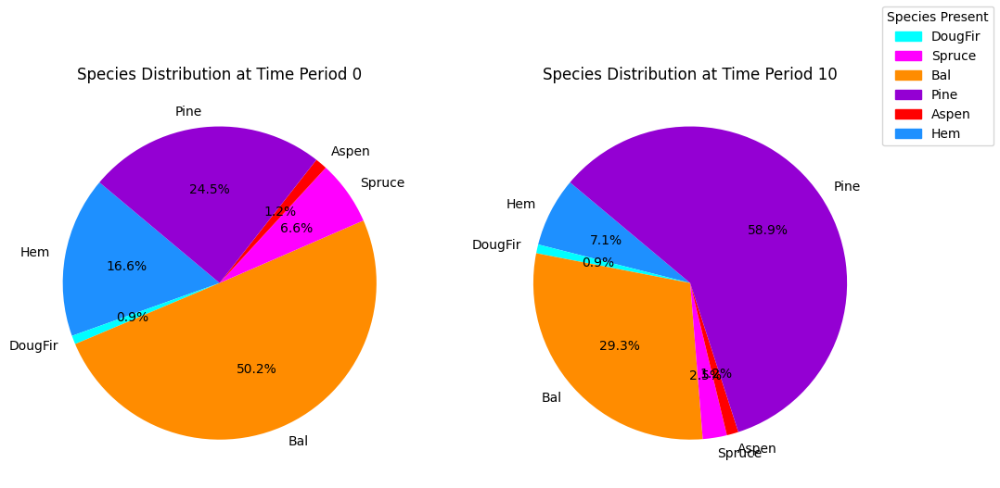

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_50%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.25s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

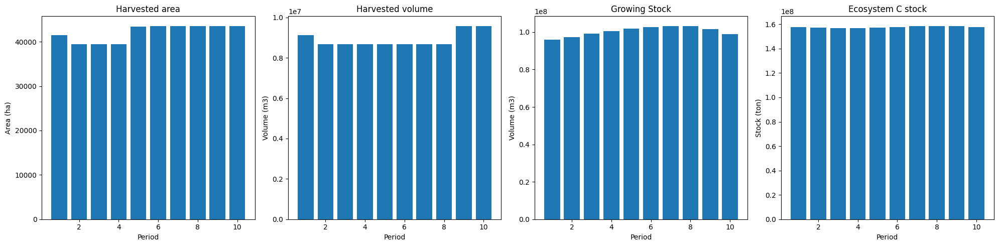

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


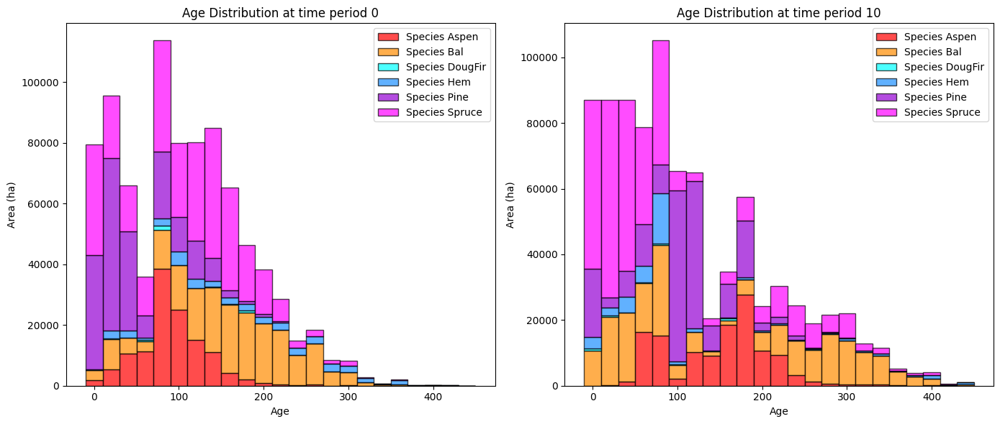

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


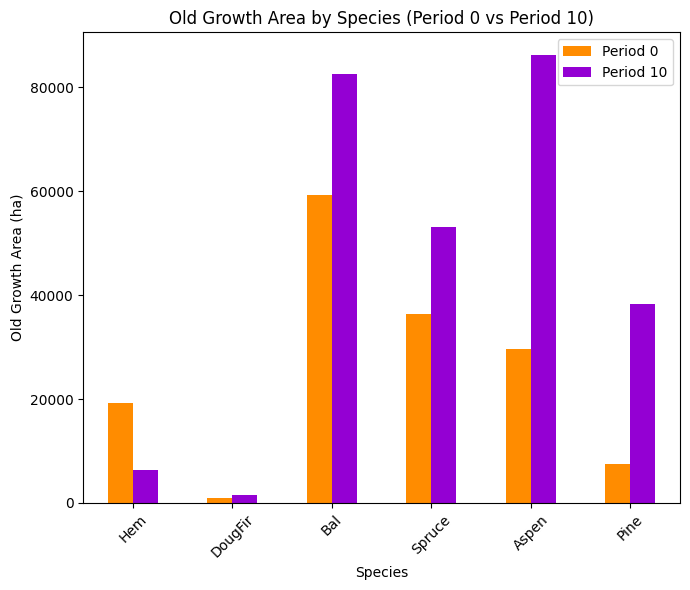

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


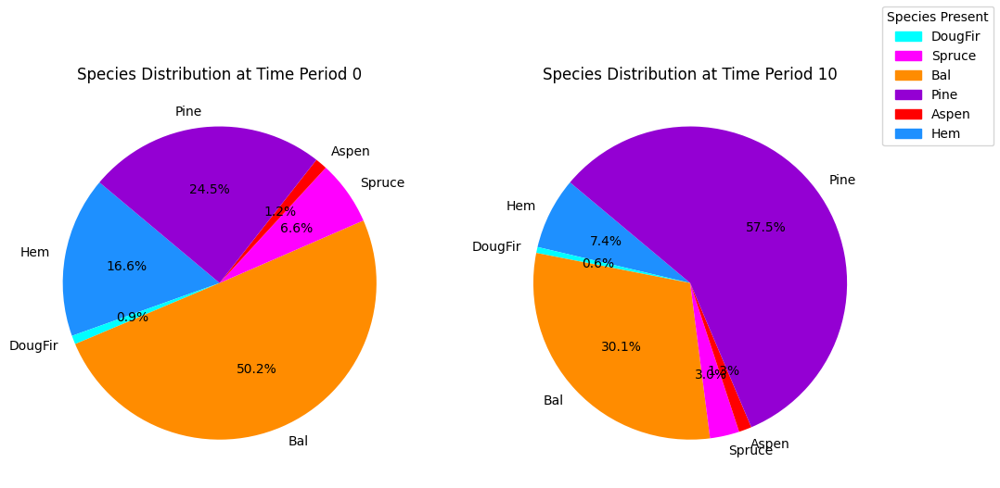

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


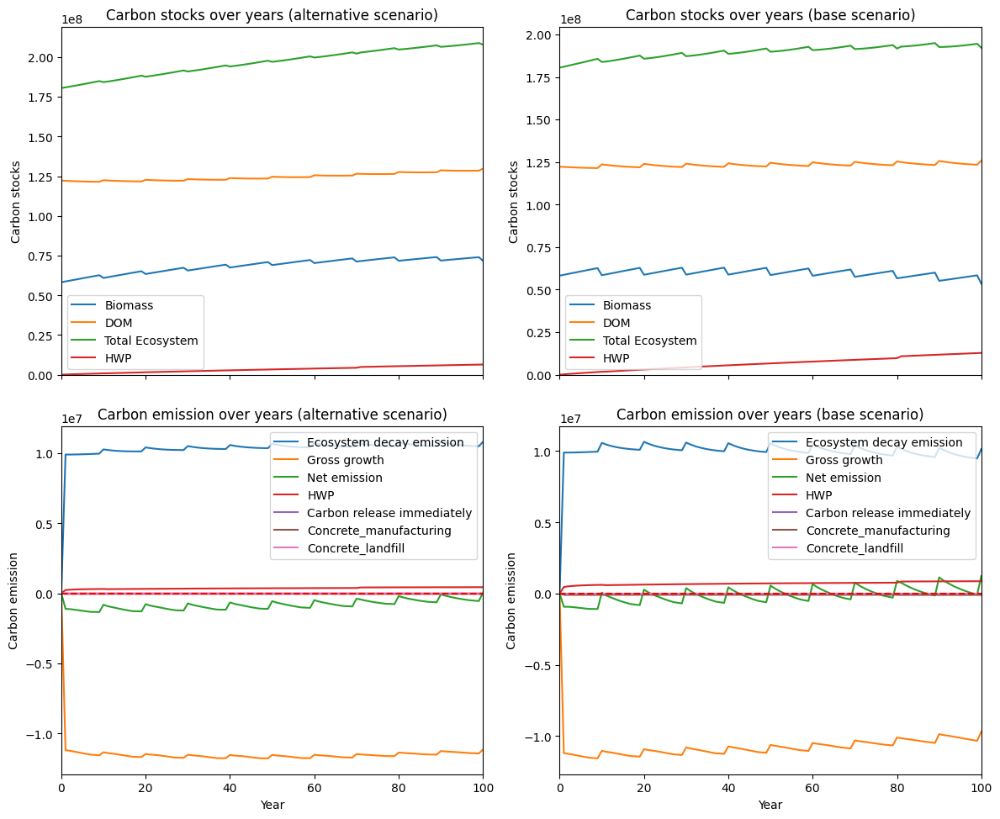

---------------------------------------------------------------------------------------
Net emission difference -13008966.614127643
Net emission base scenario -26926891.15516379
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.7687005660495794
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   2587.778105   2587.778105
DougFir  0.0   1100.552134   1100.552134
Bal      0.0  12939.534929  12939.534929
Spruce   0.0  80510.472650  80510.472650
Aspen    0.0  28100.725228  28100.725228
Pine     0.0  26422.268182  26422.268182

Overall, the old growth area has **increased** by 151661.33 hectares in the alternative scenario compared to the base scenario.


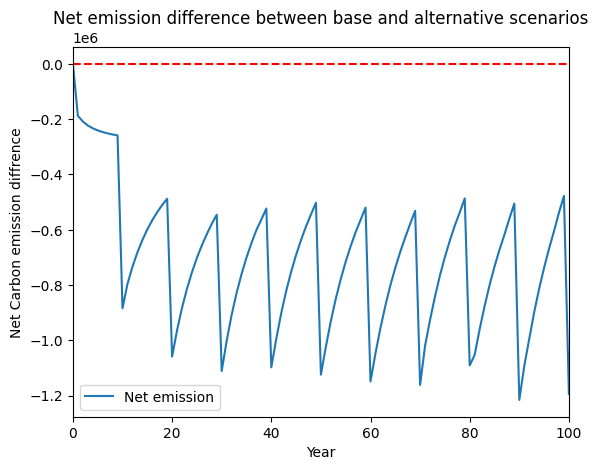

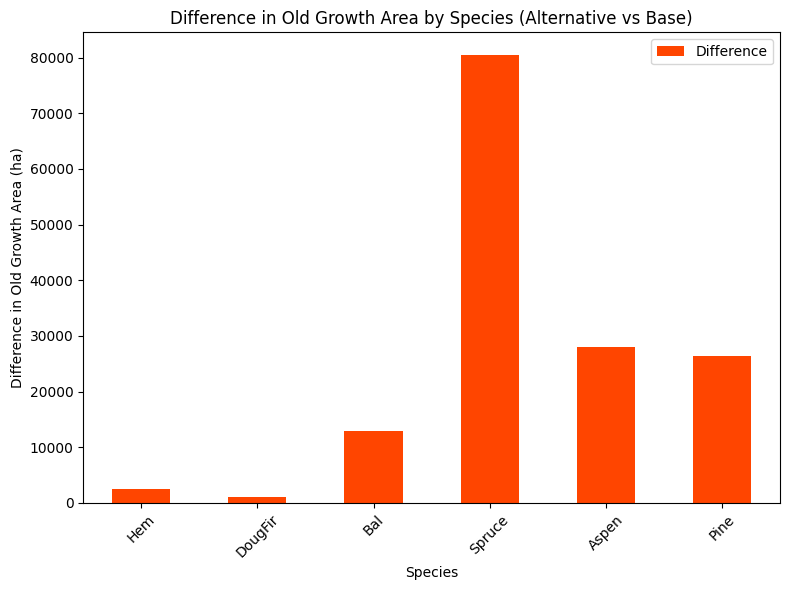

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


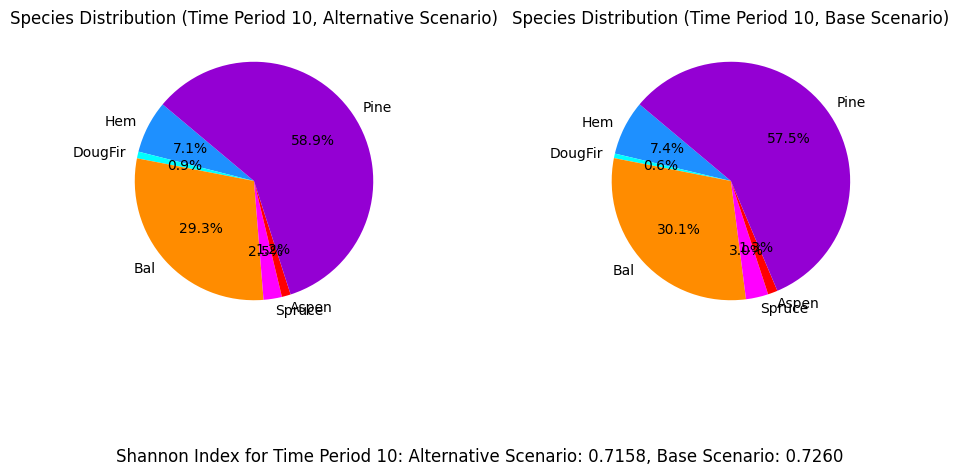

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_40%...
running the scenario for the Equity Silver mining site (40%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x4e9c4d81
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.23s
Presolved: 8375 r

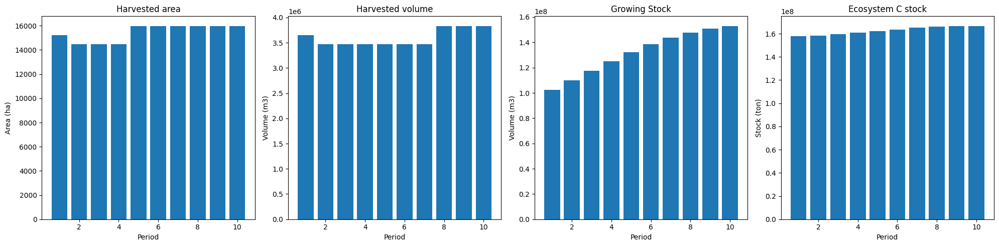

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_40%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  38020
The economic indicator (the provincial government revenues) is:  1296593
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


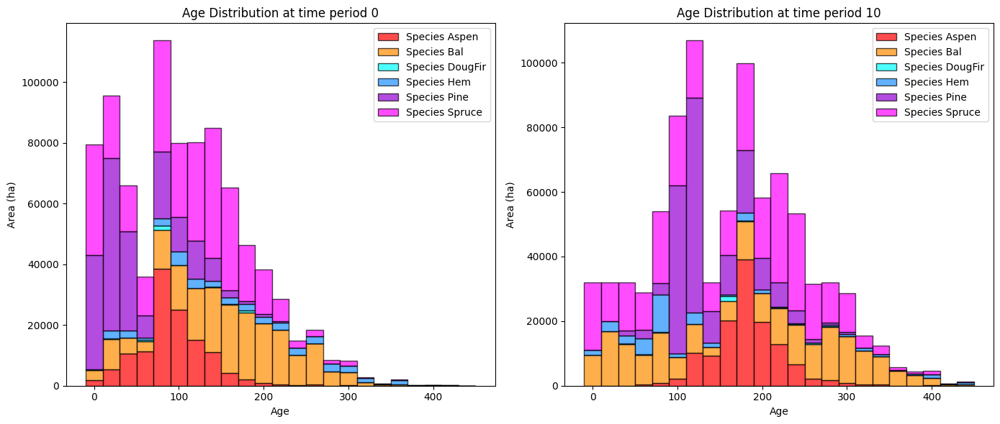

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_40%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   10774.663067   -8377.464161
DougFir    947.047810    2607.841586    1660.793776
Bal      59315.970469   99933.016891   40617.046423
Spruce   36410.744598  153909.549788  117498.805191
Aspen    29632.731169  117852.853466   88220.122297
Pine      7432.733686   65861.455786   58428.722100

Overall diversity has **increased** by 298048.03 hectares from time period 0 to time period 10.


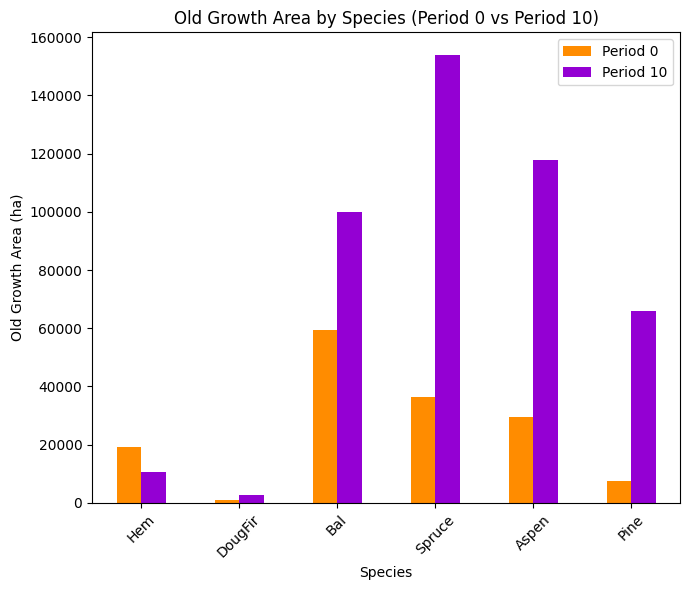

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_40%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7122

Diversity has **decreased** by 4.70% from time 0 to time 10.


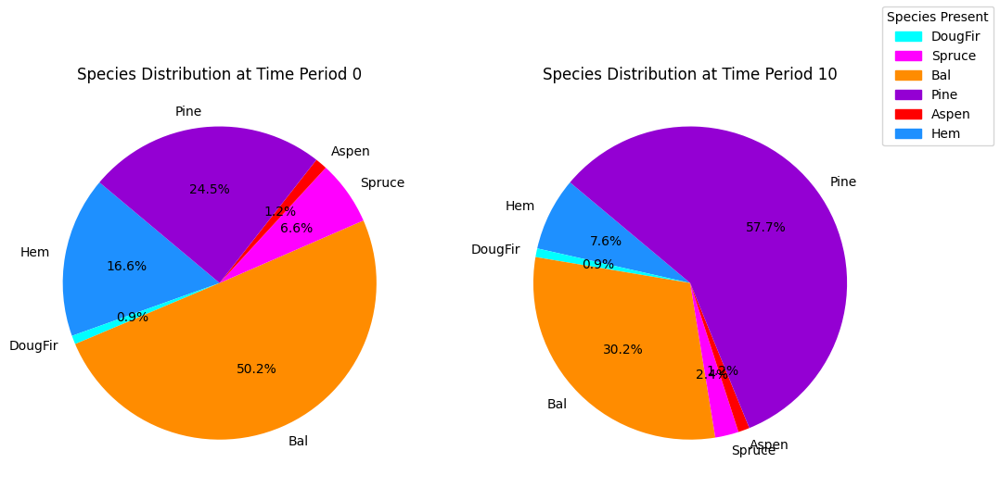

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_40%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.29s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

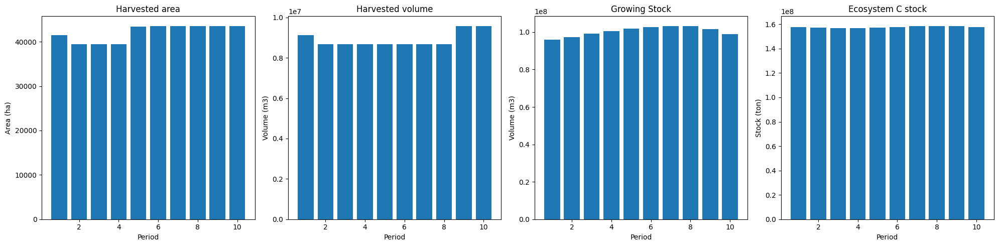

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


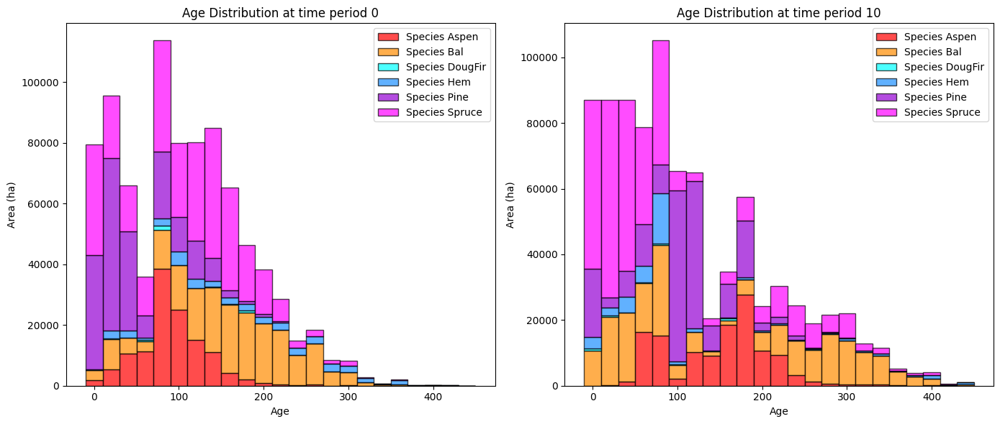

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


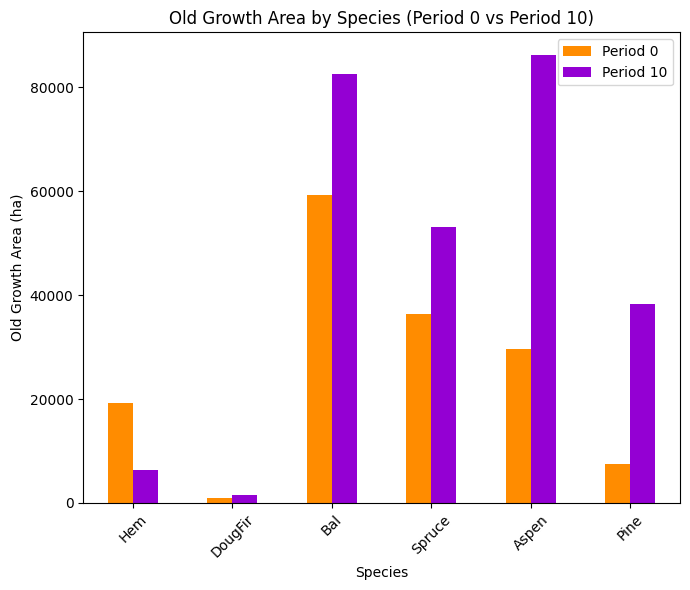

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


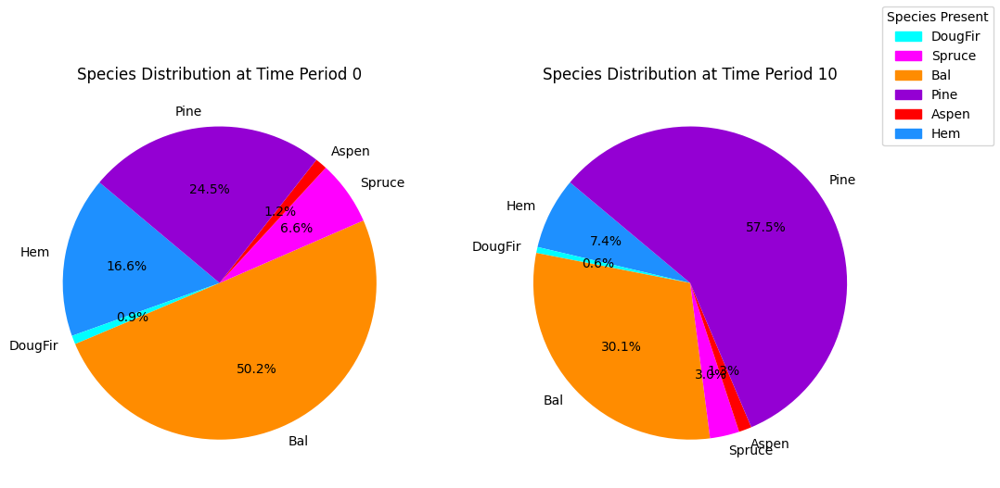

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


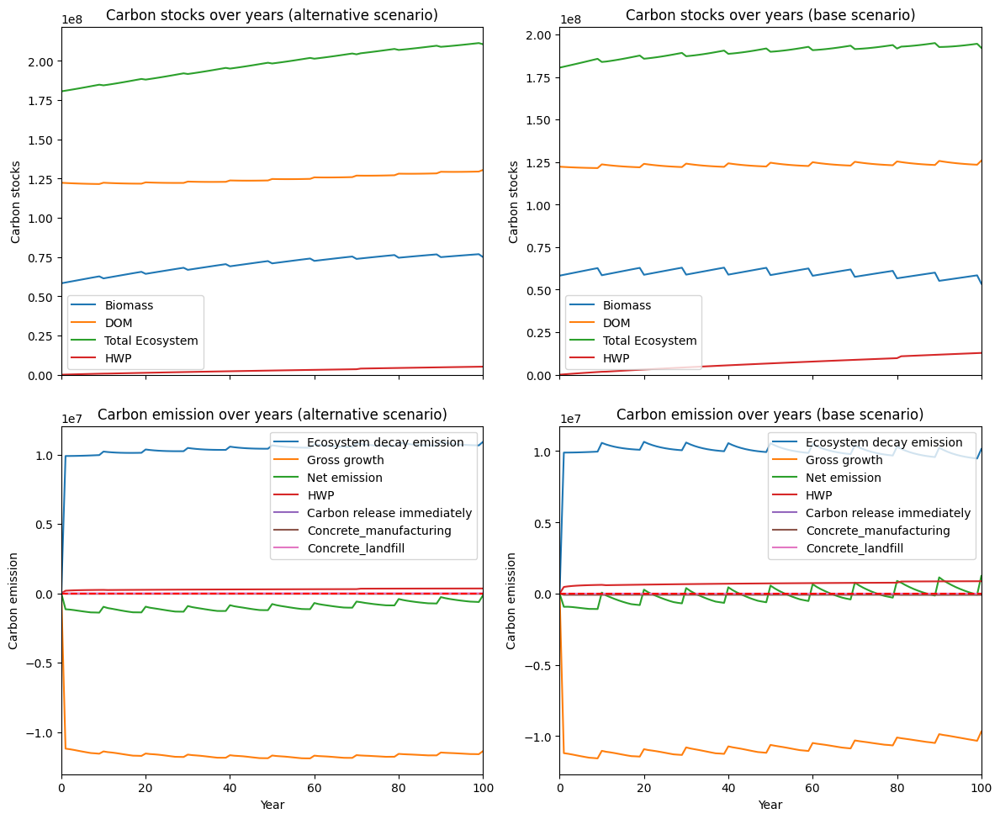

---------------------------------------------------------------------------------------
Net emission difference -15331708.77983441
Net emission base scenario -29249633.320870563
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.6522430176310722
Comparison of Old Growth Areas (Alternative - Base)
           0             10     Difference
Hem      0.0    4438.403476    4438.403476
DougFir  0.0    1120.945574    1120.945574
Bal      0.0   17322.393465   17322.393465
Spruce   0.0  100882.083654  100882.083654
Aspen    0.0   31628.794705   31628.794705
Pine     0.0   27607.886524   27607.886524

Overall, the old growth area has **increased** by 183000.51 hectares in the alternative scenario compared to the base scenario.


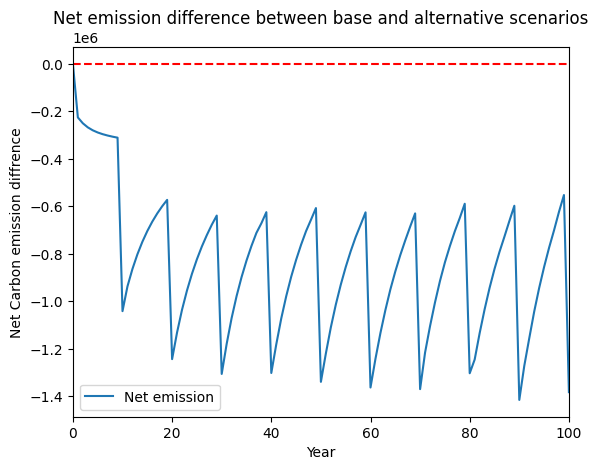

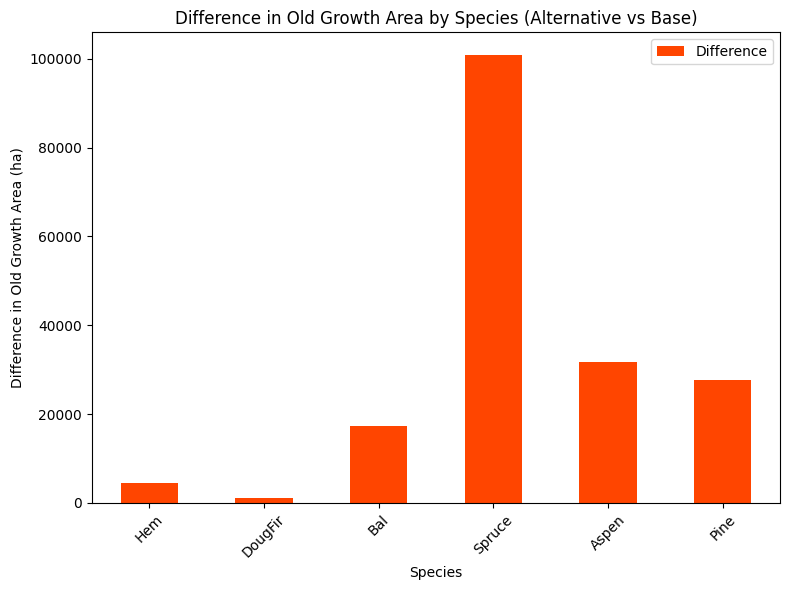

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


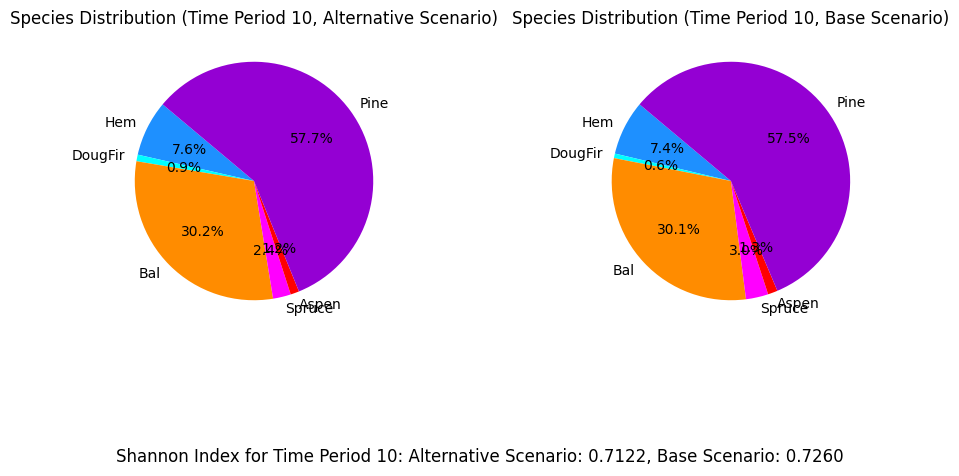

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_30%...
running the scenario for the Equity Silver mining site (30%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x7f861c3d
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.28s
Presolved: 8375 r

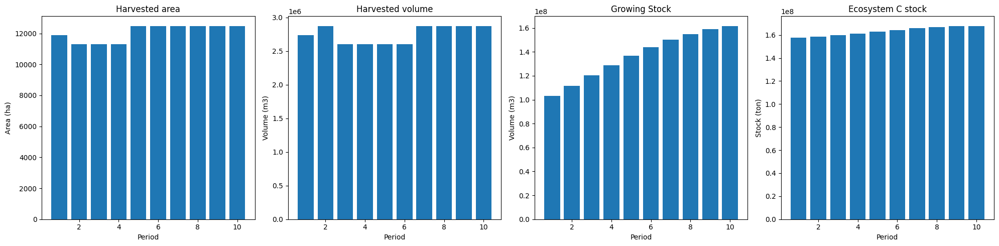

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_30%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  29094
The economic indicator (the provincial government revenues) is:  992190
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


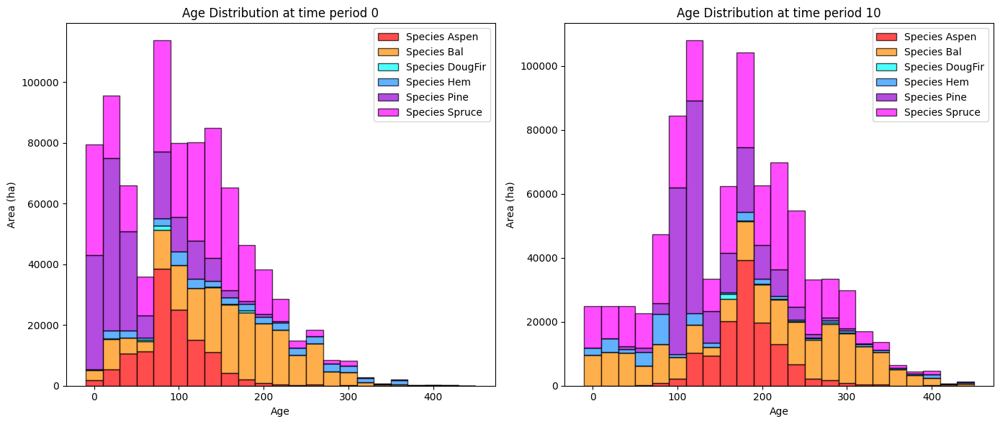

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_30%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   13217.087633   -5935.039596
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  113151.691702   53835.721234
Spruce   36410.744598  161048.576156  124637.831558
Aspen    29632.731169  118052.632115   88419.900946
Pine      7432.733686   67763.229102   60330.495416

Overall diversity has **increased** by 323091.16 hectares from time period 0 to time period 10.


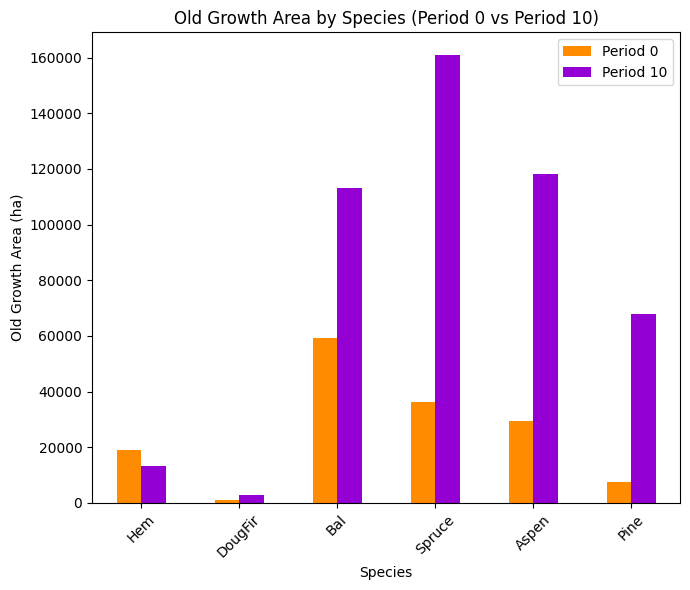

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_30%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7132

Diversity has **decreased** by 4.59% from time 0 to time 10.


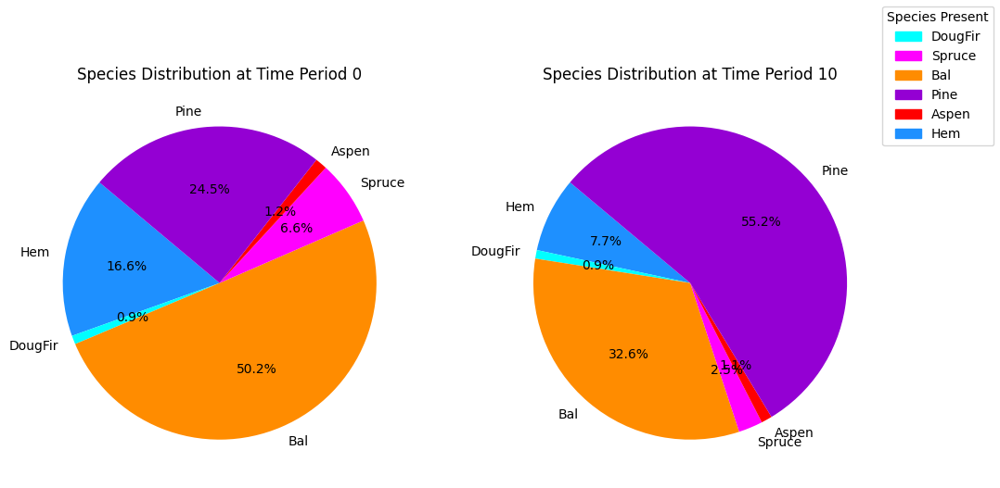

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_30%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.27s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

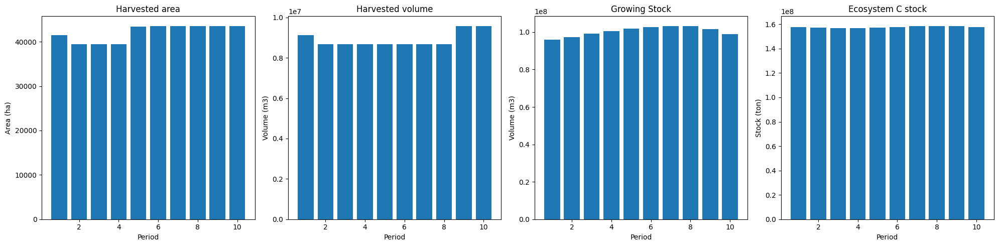

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


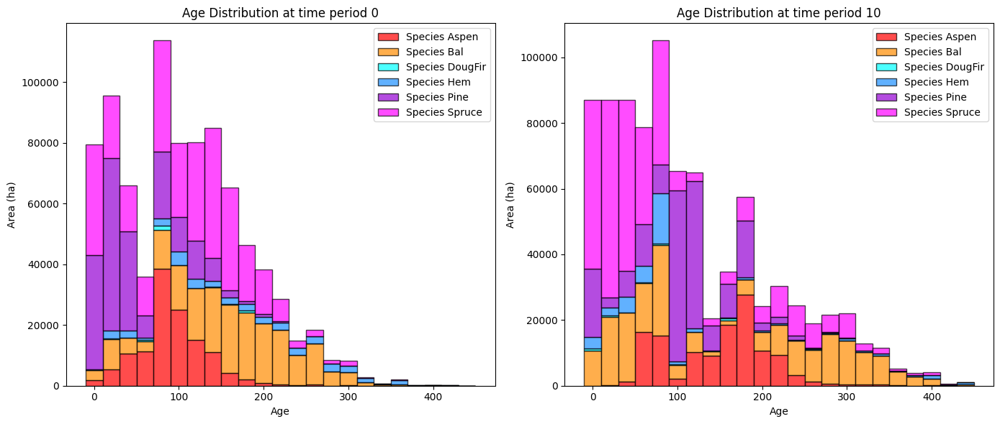

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


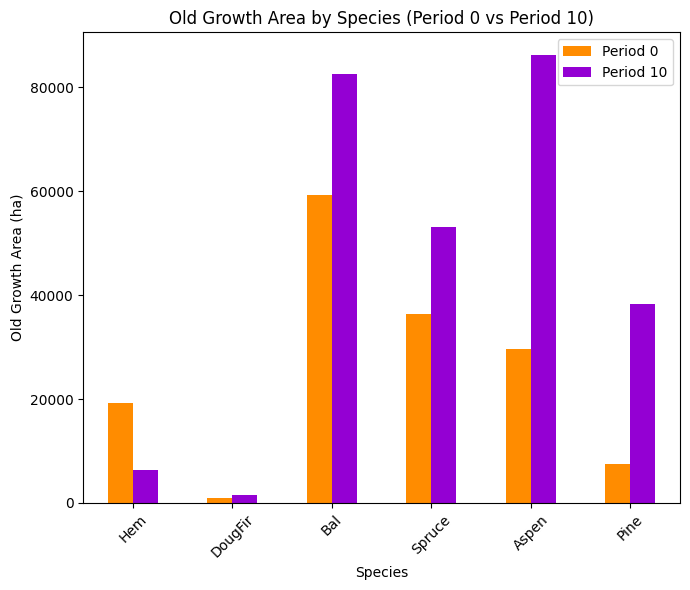

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


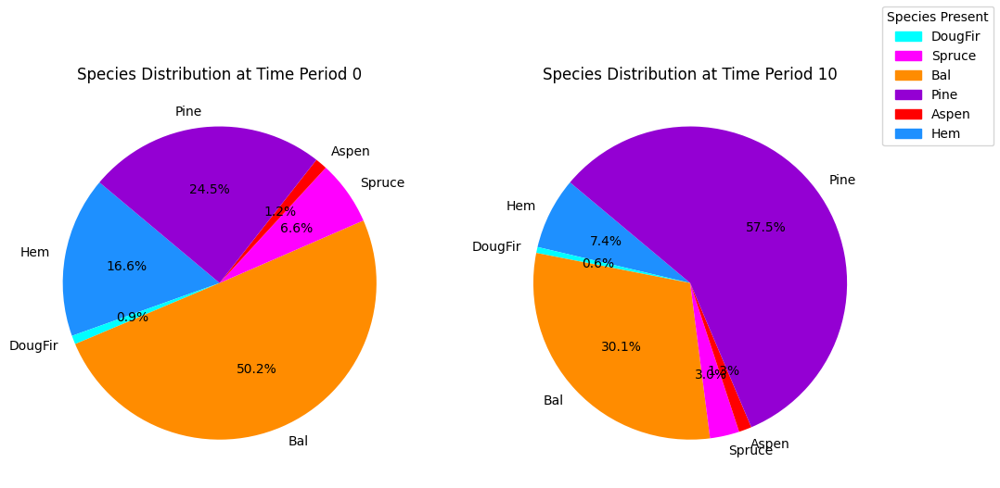

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


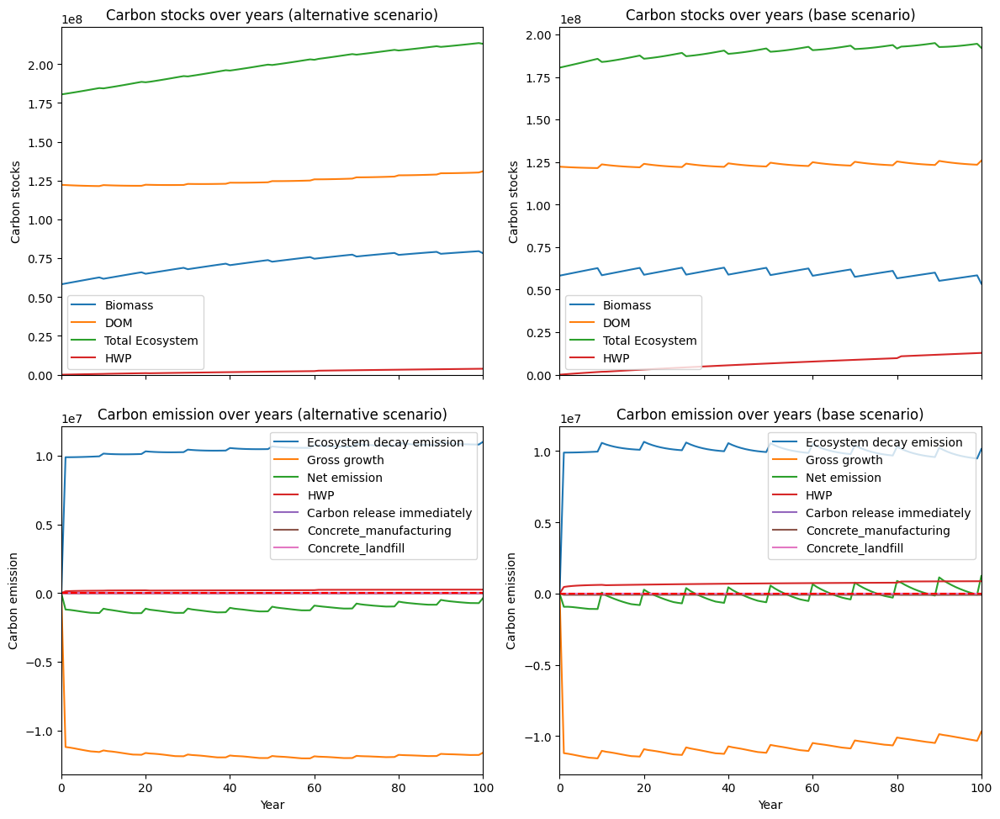

---------------------------------------------------------------------------------------
Net emission difference -17546641.76010146
Net emission base scenario -31464566.30113761
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.5699096235462311
Comparison of Old Growth Areas (Alternative - Base)
           0             10     Difference
Hem      0.0    6880.828041    6880.828041
DougFir  0.0    1262.402200    1262.402200
Bal      0.0   30541.068276   30541.068276
Spruce   0.0  108021.110021  108021.110021
Aspen    0.0   31828.573353   31828.573353
Pine     0.0   29509.659839   29509.659839

Overall, the old growth area has **increased** by 208043.64 hectares in the alternative scenario compared to the base scenario.


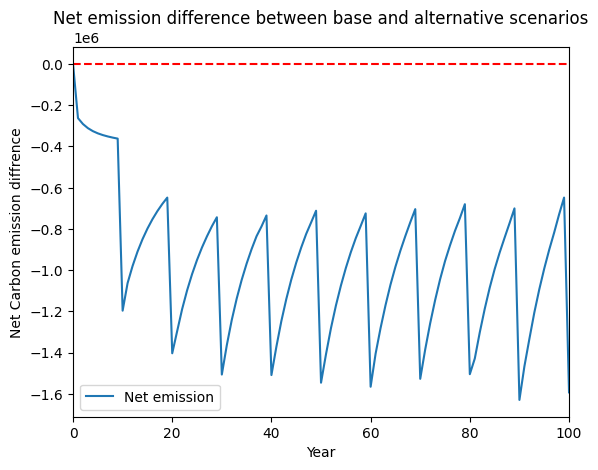

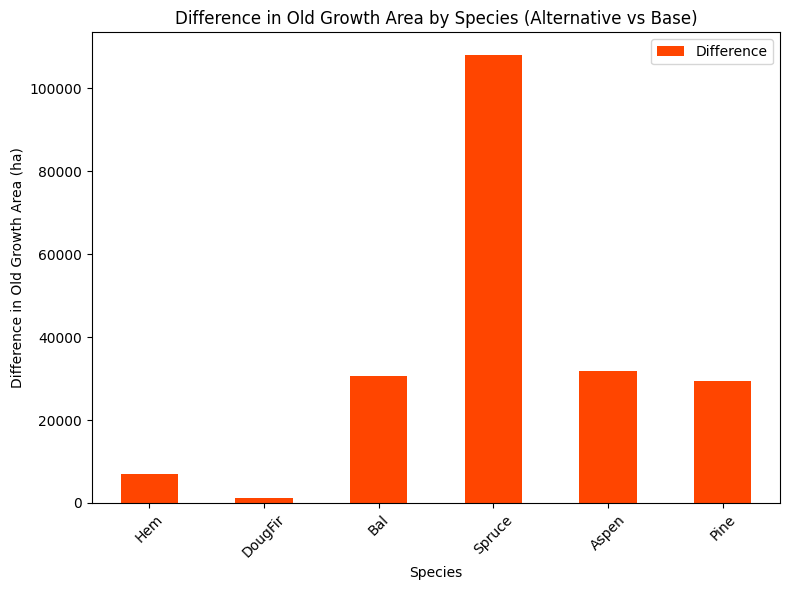

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


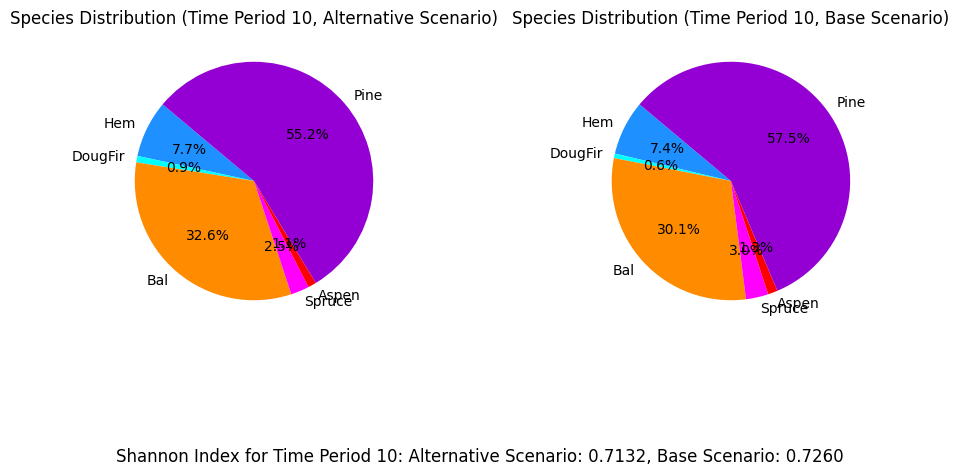

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_20%...
running the scenario for the Equity Silver mining site (20%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xaf2f8694
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.25s
Presolved: 8375 r

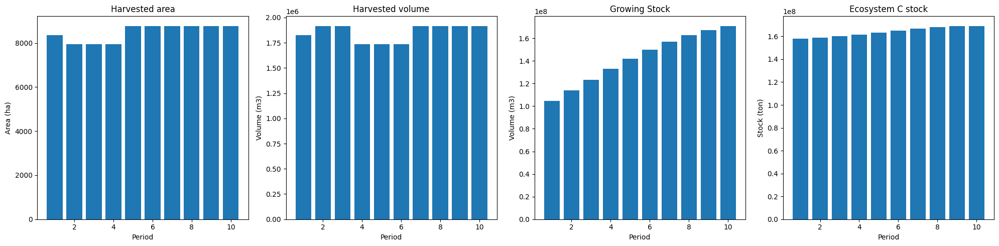

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_20%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  19589
The economic indicator (the provincial government revenues) is:  668041
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


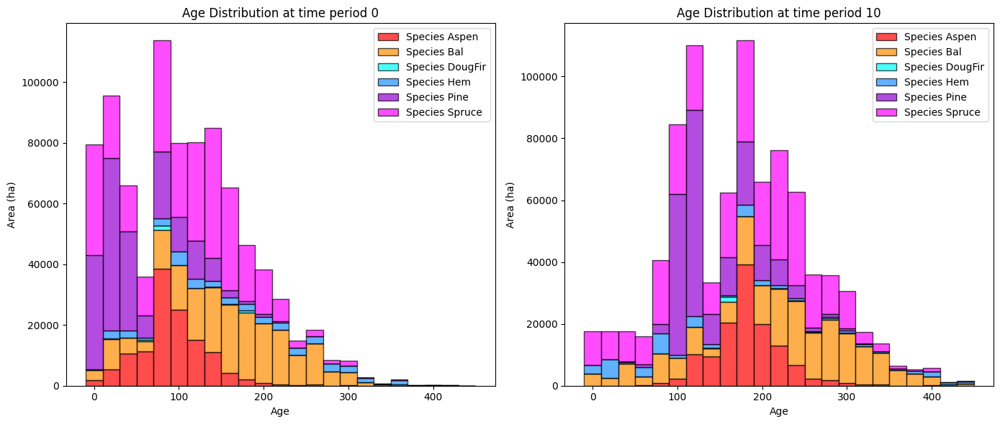

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_20%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   15070.475391   -4081.651838
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  134324.372697   75008.402229
Spruce   36410.744598  168339.164189  131928.419591
Aspen    29632.731169  118142.060176   88509.329007
Pine      7432.733686   68992.336888   61559.603202

Overall diversity has **increased** by 354726.35 hectares from time period 0 to time period 10.


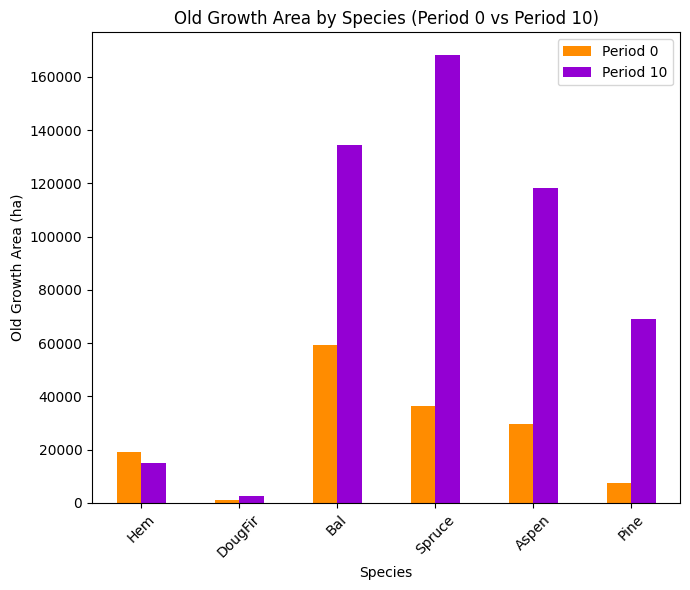

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_20%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7134

Diversity has **decreased** by 4.57% from time 0 to time 10.


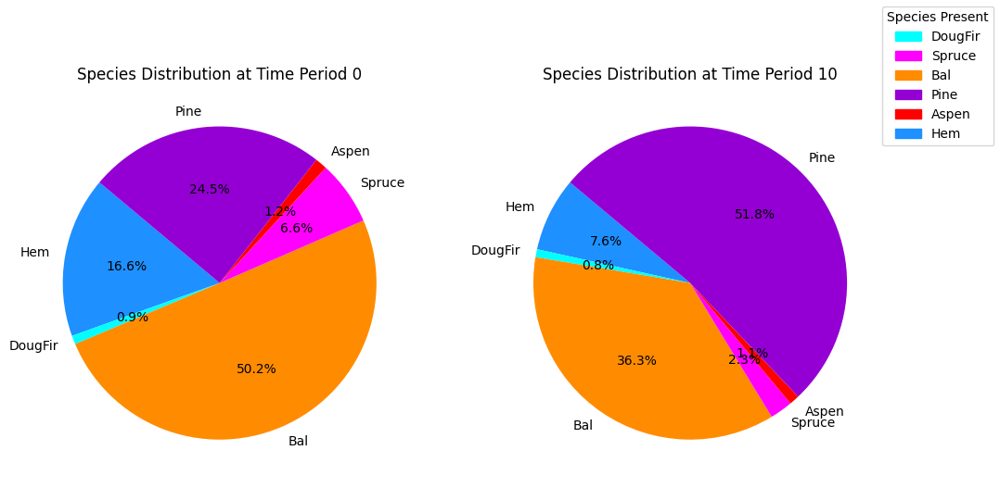

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_20%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.26s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

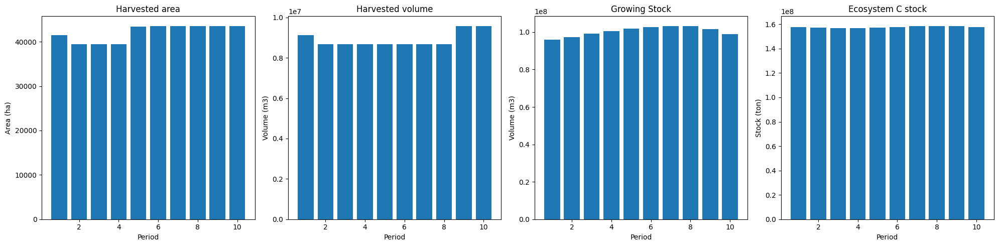

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


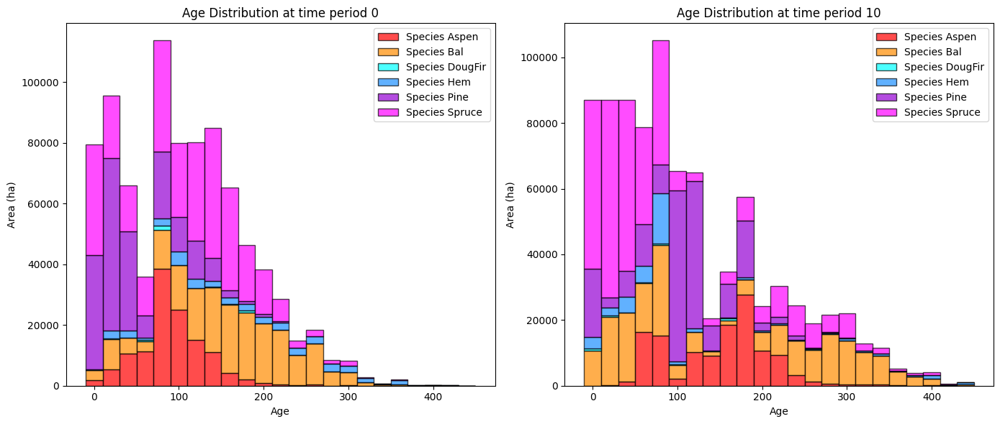

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


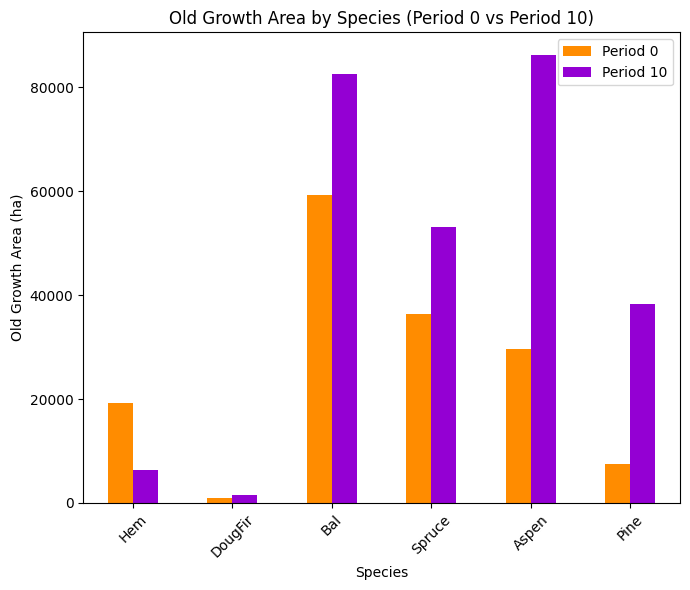

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


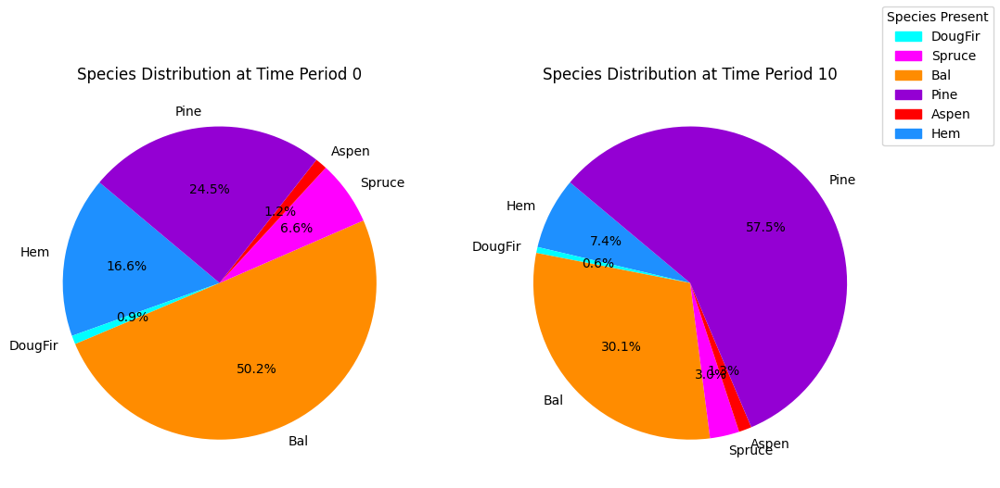

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


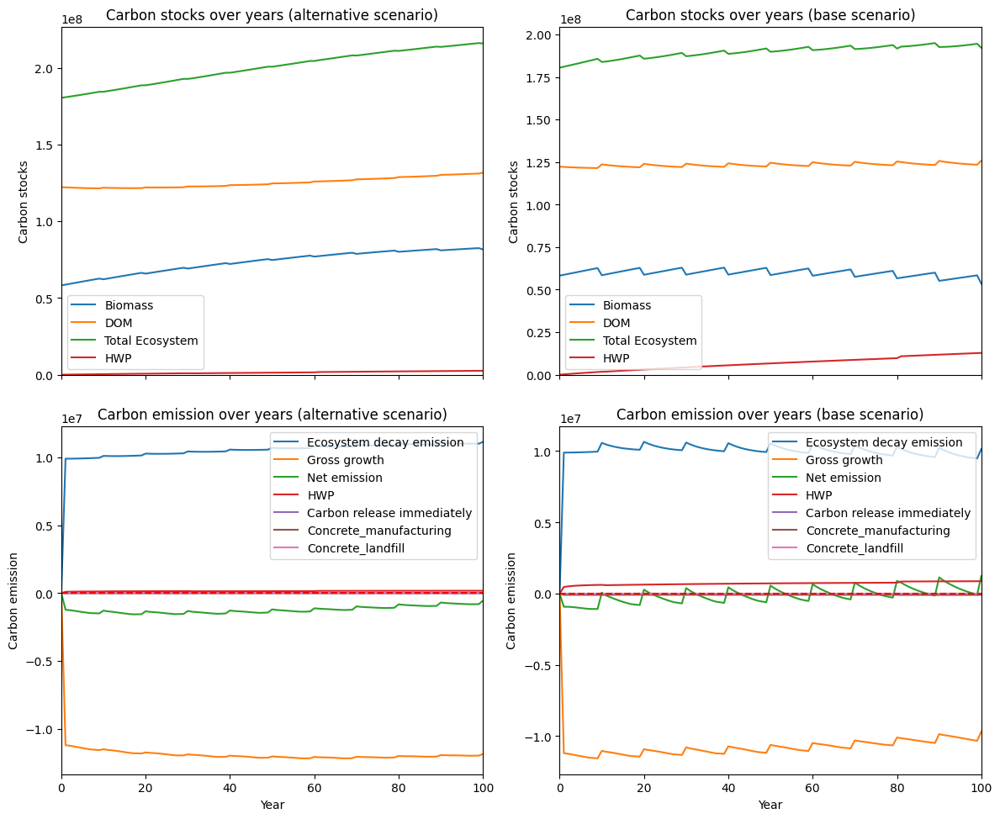

---------------------------------------------------------------------------------------
Net emission difference -20100653.854370482
Net emission base scenario -34018578.39540663
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.4974962542238745
Comparison of Old Growth Areas (Alternative - Base)
           0             10     Difference
Hem      0.0    8734.215799    8734.215799
DougFir  0.0    1262.402200    1262.402200
Bal      0.0   51713.749271   51713.749271
Spruce   0.0  115311.698054  115311.698054
Aspen    0.0   31918.001414   31918.001414
Pine     0.0   30738.767625   30738.767625

Overall, the old growth area has **increased** by 239678.83 hectares in the alternative scenario compared to the base scenario.


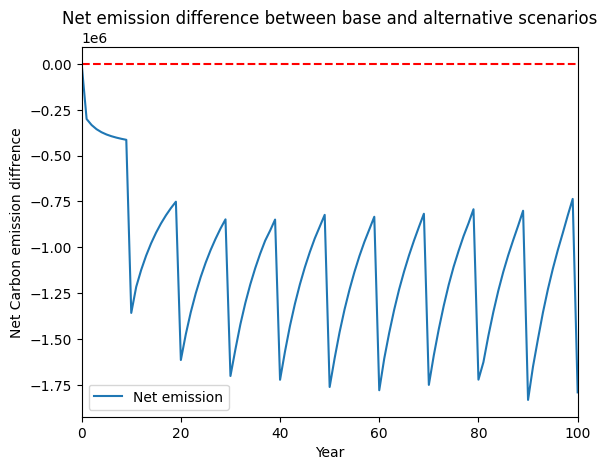

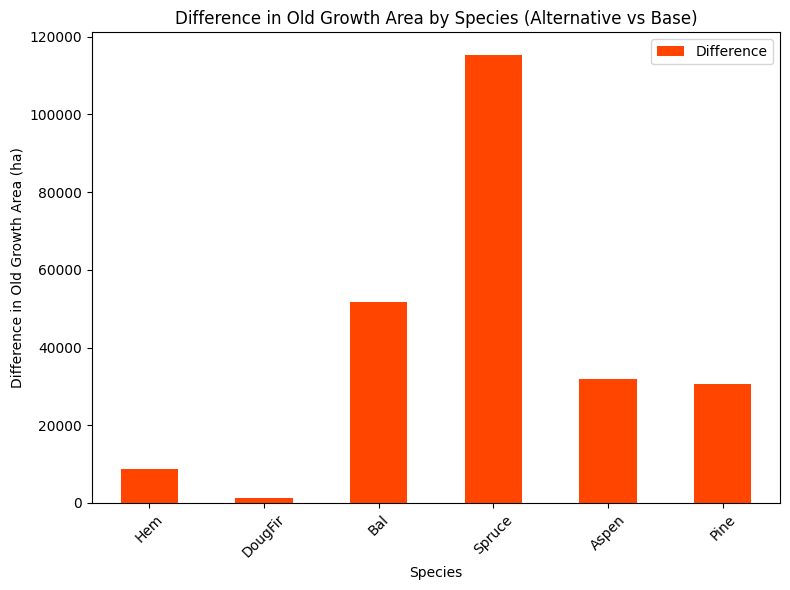

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


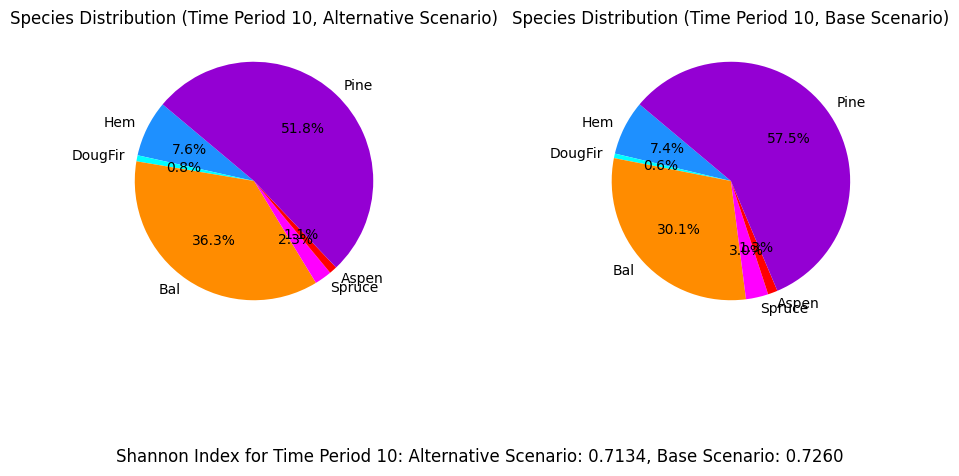

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_max_st_eqtslvr_AAC_10%...
running the scenario for the Equity Silver mining site (10%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x33790cd0
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.22s
Presolved: 8375 r

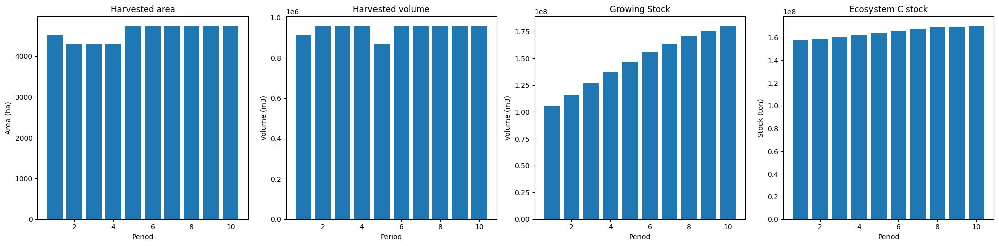

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_10%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  9987
The economic indicator (the provincial government revenues) is:  340602
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


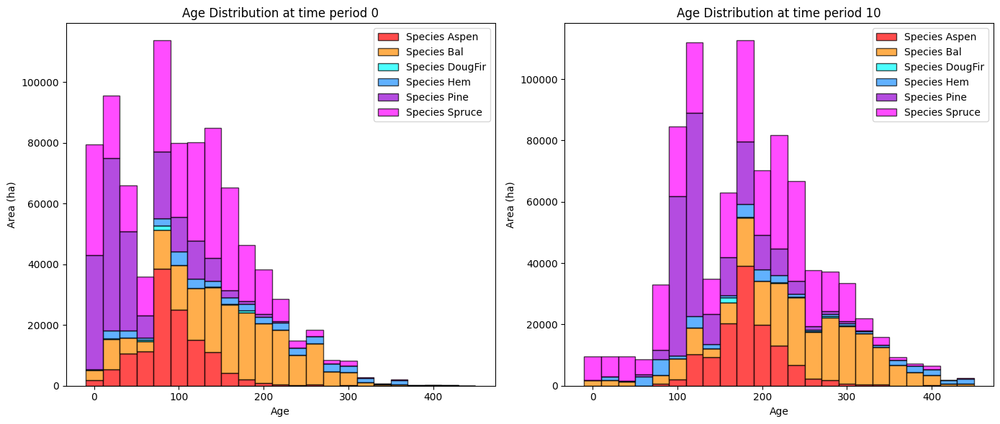

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_10%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   22764.808406    3612.681177
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  151510.434905   92194.464436
Spruce   36410.744598  175312.916367  138902.171769
Aspen    29632.731169  118295.435164   88662.703994
Pine      7432.733686   69974.668514   62541.934828

Overall diversity has **increased** by 387716.21 hectares from time period 0 to time period 10.


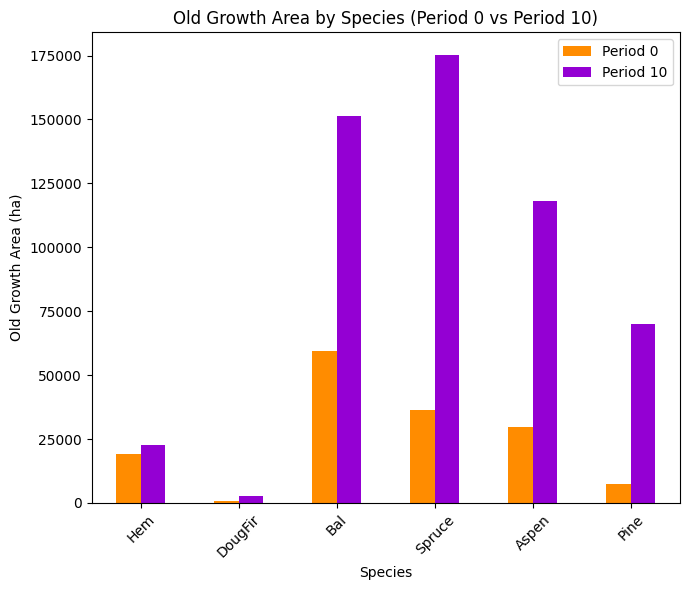

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_10%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7227

Diversity has **decreased** by 3.65% from time 0 to time 10.


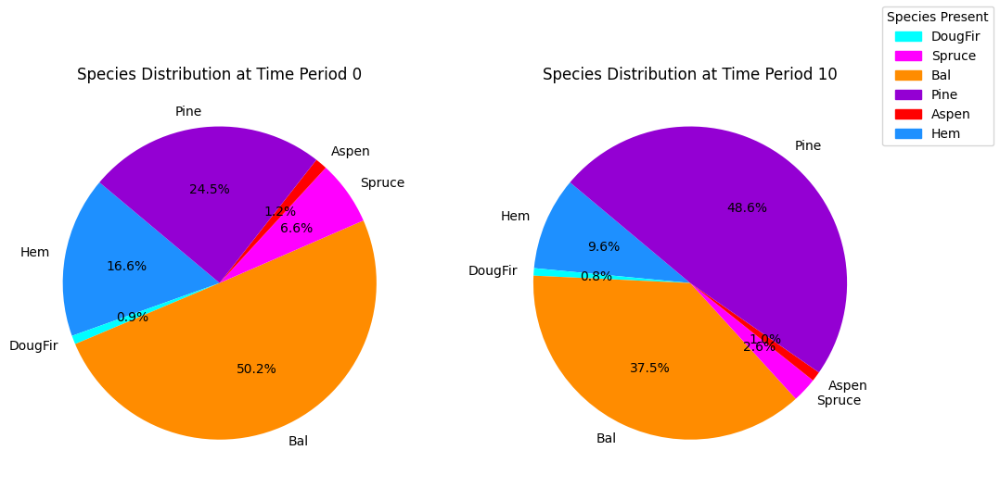

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_eqtslvr_AAC_10%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xc5591c7f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e+01, 7e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8883 columns
Presolve time: 0.22s
Presolved: 8375 rows, 74376 columns, 536315 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

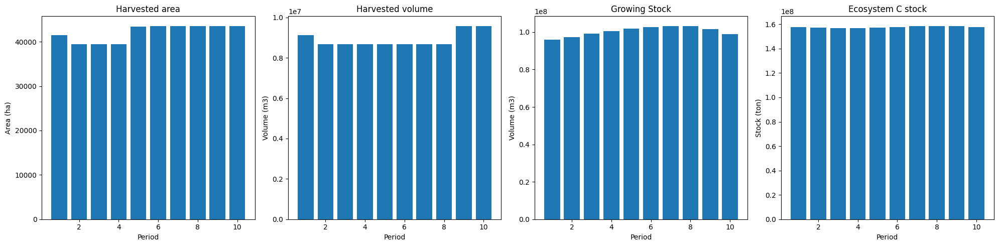

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


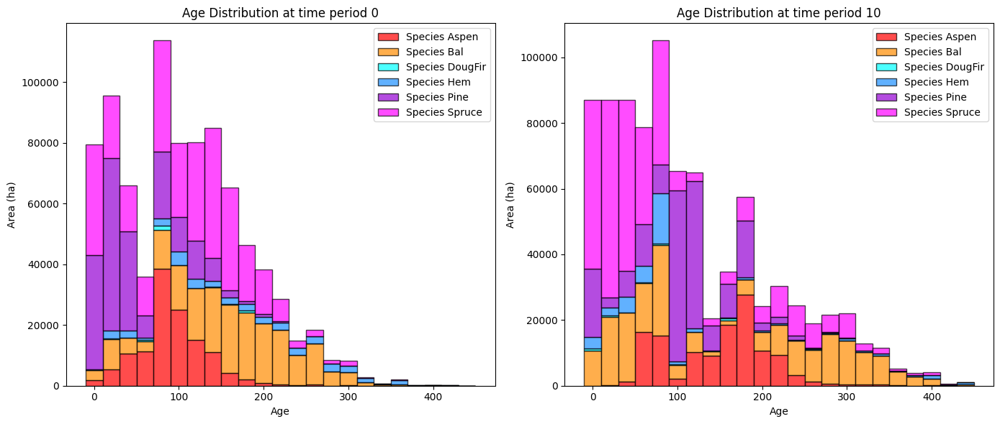

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   6336.259592 -12815.867637
DougFir    947.047810   1486.896012    539.848202
Bal      59315.970469  82610.623426  23294.652957
Spruce   36410.744598  53027.466135  16616.721537
Aspen    29632.731169  86224.058762  56591.327592
Pine      7432.733686  38253.569262  30820.835576

Overall diversity has **increased** by 115047.52 hectares from time period 0 to time period 10.


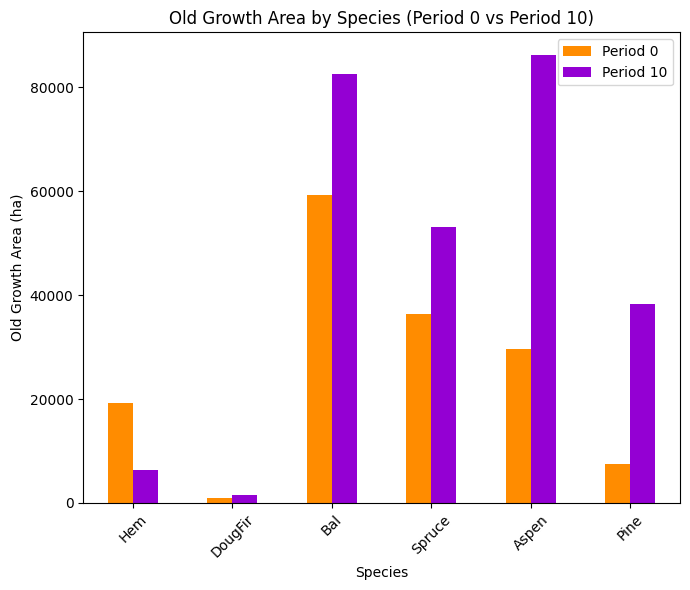

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7260

Diversity has **decreased** by 3.32% from time 0 to time 10.


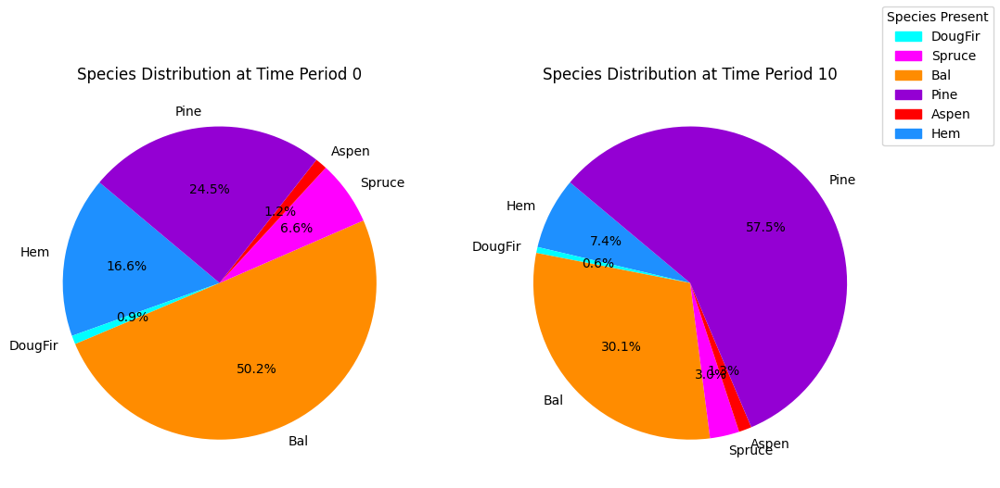

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_bau_eqtslvr_species_pie.pdf


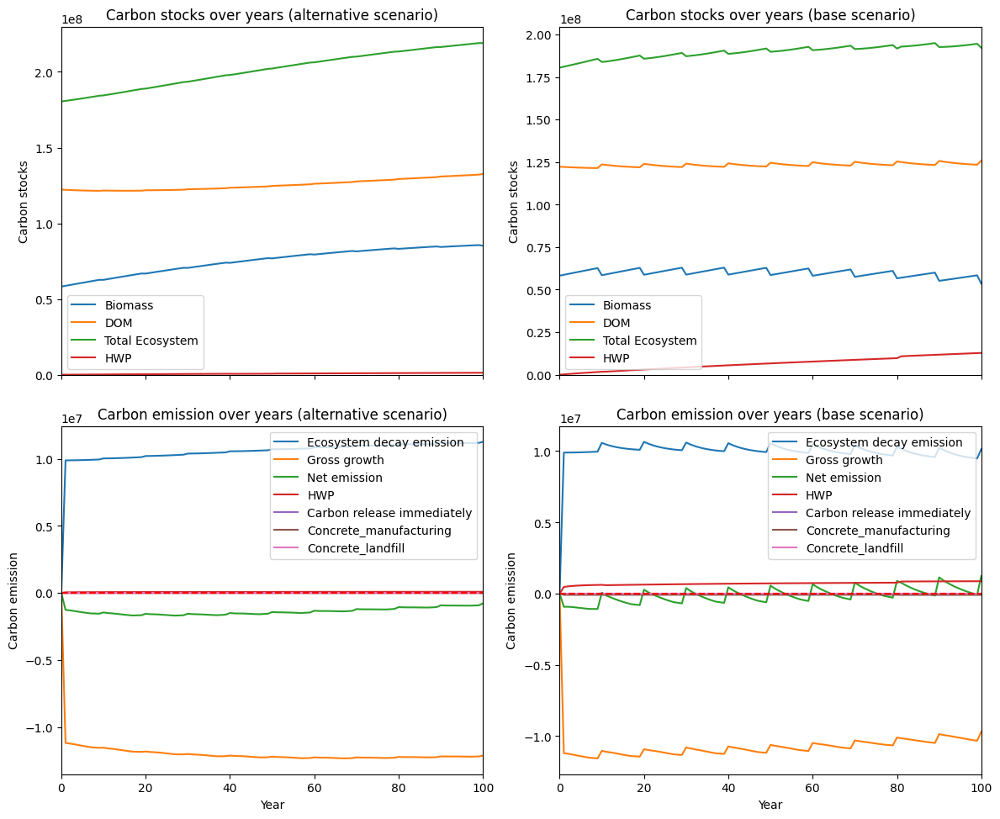

---------------------------------------------------------------------------------------
Net emission difference -22798500.985735554
Net emission base scenario -36716425.52677171
Net emission alternative scenario -13917924.541036148
dollar_per_ton is:  0.43862532919408814
Comparison of Old Growth Areas (Alternative - Base)
           0             10     Difference
Hem      0.0   16428.548814   16428.548814
DougFir  0.0    1262.402200    1262.402200
Bal      0.0   68899.811479   68899.811479
Spruce   0.0  122285.450232  122285.450232
Aspen    0.0   32071.376402   32071.376402
Pine     0.0   31721.099252   31721.099252

Overall, the old growth area has **increased** by 272668.69 hectares in the alternative scenario compared to the base scenario.


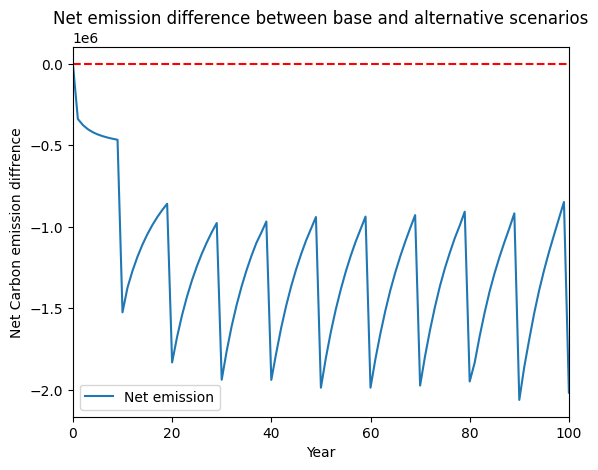

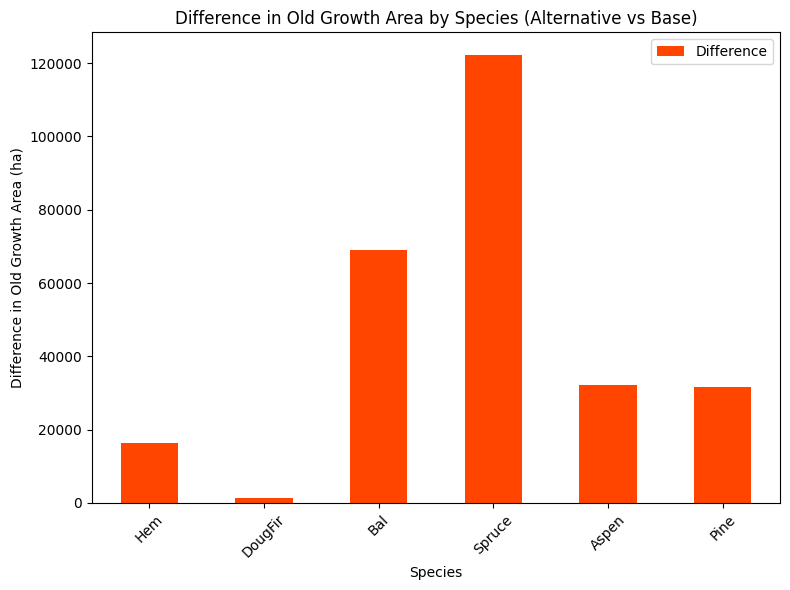

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_age_difference.pdf


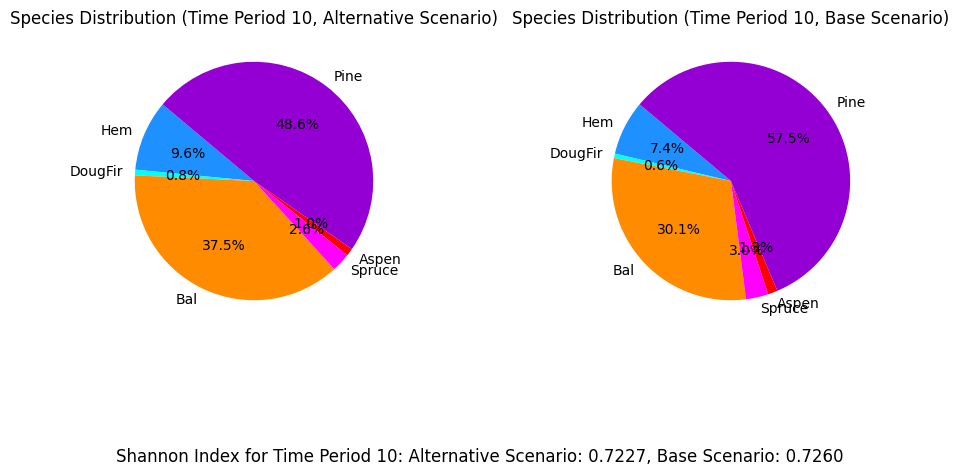

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
It took 156.8 minutes to run all scenarios.


In [12]:
Start = time.time()
scenario_names = ['eqtslvr_AAC_50%', 'eqtslvr_AAC_40%', 'eqtslvr_AAC_30%', 'eqtslvr_AAC_20%', 'eqtslvr_AAC_10%']
for scenario_name in scenario_names:
    print(f"Running for {case_study}_{obj_mode}_{scenario_name}...")
    results_scenarios(fm, 
                      clt_percentage, 
                      credibility, 
                      budget_input, 
                      n_steps, 
                      max_harvest, 
                      scenario_name, 
                      displacement_effect, 
                      hwp_pool_effect_value, 
                      release_immediately_value, 
                      case_study, 
                      obj_mode,                   
                      pickle_output_base=False, 
                      pickle_output_alter=False)
print('It took', round((time.time() - Start) / 60, 1), "minutes to run all scenarios.")

In [13]:
print('It took', round((time.time() - Start) / 60, 1), "minutes to run this script.")

It took 156.8 minutes to run this script.
